<a href="https://colab.research.google.com/github/Tom-Bellmaine/natural-gas-market-analytics/blob/main/Natural_Gas_Market_Analytics.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

HENRY HUB NATURAL GAS MARKET ANALYSIS
Source: FRED / US Energy Information Administration

First observation: 1997-01-07
Latest observation: 2026-11-03
Years of data: 29.8
Total observations: 5722

Latest Henry Hub price: $2.63/MMBtu

LATEST 10 OBSERVATIONS
      Date  Henry_Hub_USD_MMBtu    MA_30
2026-10-21                 3.01 3.045000
2026-10-22                 2.95 3.051333
2026-10-23                 2.78 3.053667
2026-10-26                 2.52 3.042667
2026-10-27                 2.76 3.035667
2026-10-28                 2.86 3.031000
2026-10-29                 2.68 3.023667
2026-10-30                 2.42 3.005333
2026-11-02                 2.54 2.992333
2026-11-03                 2.63 2.983333


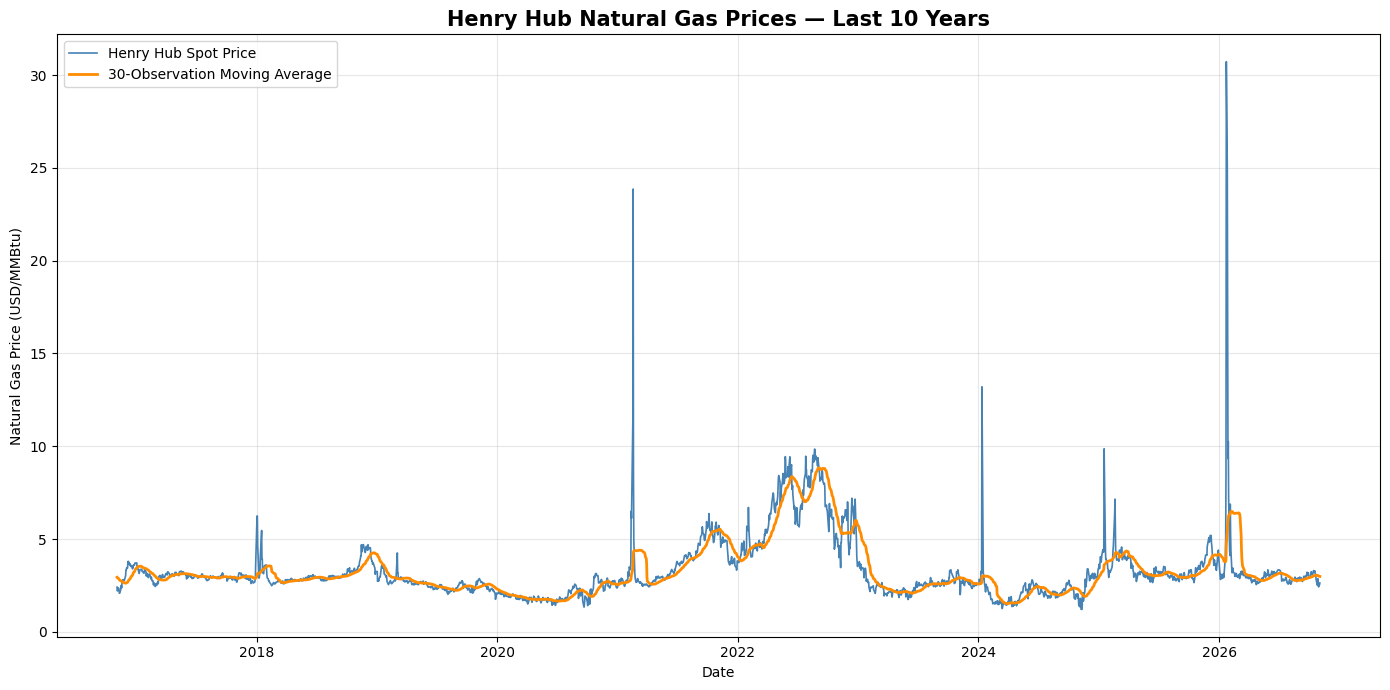


ANNUAL AVERAGE HENRY HUB PRICES
 Year  Annual_Average_USD_MMBtu
 2017                      2.99
 2018                      3.15
 2019                      2.56
 2020                      2.03
 2021                      3.89
 2022                      6.45
 2023                      2.53
 2024                      2.19
 2025                      3.52
 2026                      3.43


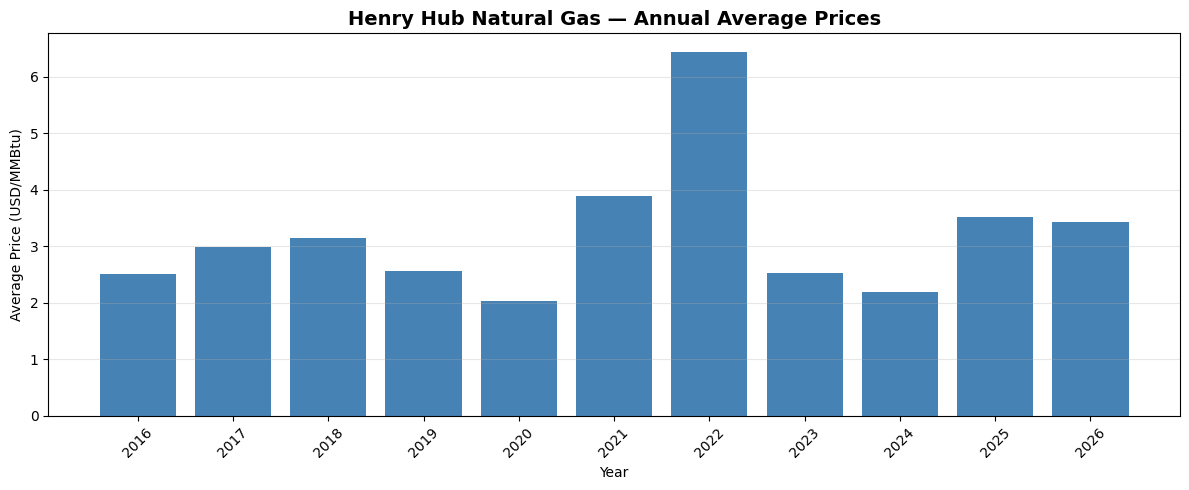


SUCCESS: Historical natural gas data saved
File: henry_hub_prices.csv
Coverage: 1997-01-07 to 2026-11-03
Total rows: 5722


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

# ============================================================
# PROJECT 3 — NATURAL GAS MARKET DASHBOARD
# BATCH 1: HENRY HUB NATURAL GAS PRICES
# 10-YEAR CHART + FULL HISTORICAL DATA
# ============================================================

import pandas as pd
import matplotlib.pyplot as plt
from google.colab import files

# ------------------------------------------------------------
# 1. DOWNLOAD HENRY HUB NATURAL GAS PRICES
# ------------------------------------------------------------

url = (
    "https://fred.stlouisfed.org/graph/fredgraph.csv"
    "?id=DHHNGSP"
)

gas = pd.read_csv(url)

# ------------------------------------------------------------
# 2. CLEAN AND PREPARE DATA
# ------------------------------------------------------------

gas.columns = ["Date", "Henry_Hub_USD_MMBtu"]

gas["Date"] = pd.to_datetime(
    gas["Date"],
    errors="coerce"
)

gas["Henry_Hub_USD_MMBtu"] = pd.to_numeric(
    gas["Henry_Hub_USD_MMBtu"],
    errors="coerce"
)

gas = (
    gas.dropna()
    .sort_values("Date")
    .reset_index(drop=True)
)

if gas.empty:
    raise ValueError(
        "No valid Henry Hub prices were downloaded."
    )

# ------------------------------------------------------------
# 3. CALCULATE 30-OBSERVATION MOVING AVERAGE
# ------------------------------------------------------------

gas["MA_30"] = (
    gas["Henry_Hub_USD_MMBtu"]
    .rolling(window=30)
    .mean()
)

# ------------------------------------------------------------
# 4. DISPLAY DATA COVERAGE AND LATEST PRICE
# ------------------------------------------------------------

first_date = gas["Date"].min()
last_date = gas["Date"].max()

years_of_data = (
    (last_date - first_date).days / 365.25
)

latest = gas.iloc[-1]

print("=" * 55)
print("HENRY HUB NATURAL GAS MARKET ANALYSIS")
print("=" * 55)

print("Source: FRED / US Energy Information Administration")
print()

print("First observation:", first_date.date())
print("Latest observation:", last_date.date())
print("Years of data:", round(years_of_data, 1))
print("Total observations:", len(gas))

print()
print(
    "Latest Henry Hub price: "
    f"${latest['Henry_Hub_USD_MMBtu']:.2f}/MMBtu"
)

print()
print("LATEST 10 OBSERVATIONS")
print(gas.tail(10).to_string(index=False))

# ------------------------------------------------------------
# 5. FILTER LAST 10 YEARS FOR CHART
# ------------------------------------------------------------

cutoff = last_date - pd.DateOffset(years=10)

recent = gas[
    gas["Date"] >= cutoff
].copy()

# ------------------------------------------------------------
# 6. CREATE 10-YEAR HENRY HUB PRICE CHART
# ------------------------------------------------------------

plt.figure(figsize=(14, 7))

plt.plot(
    recent["Date"],
    recent["Henry_Hub_USD_MMBtu"],
    label="Henry Hub Spot Price",
    linewidth=1.2,
    color="steelblue"
)

plt.plot(
    recent["Date"],
    recent["MA_30"],
    label="30-Observation Moving Average",
    linewidth=2,
    color="darkorange"
)

plt.title(
    "Henry Hub Natural Gas Prices — Last 10 Years",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Date")
plt.ylabel("Natural Gas Price (USD/MMBtu)")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 7. CALCULATE ANNUAL AVERAGE GAS PRICES
# ------------------------------------------------------------

gas["Year"] = gas["Date"].dt.year

annual = (
    gas.groupby("Year")["Henry_Hub_USD_MMBtu"]
    .mean()
    .reset_index()
)

annual.columns = [
    "Year",
    "Annual_Average_USD_MMBtu"
]

print()
print("ANNUAL AVERAGE HENRY HUB PRICES")
print(annual.tail(10).round(2).to_string(index=False))

# ------------------------------------------------------------
# 8. CREATE ANNUAL AVERAGE PRICE CHART
# ------------------------------------------------------------

annual_recent = annual[
    annual["Year"] >= cutoff.year
].copy()

plt.figure(figsize=(12, 5))

plt.bar(
    annual_recent["Year"],
    annual_recent["Annual_Average_USD_MMBtu"],
    color="steelblue"
)

plt.title(
    "Henry Hub Natural Gas — Annual Average Prices",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Year")
plt.ylabel("Average Price (USD/MMBtu)")
plt.xticks(annual_recent["Year"], rotation=45)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 9. SAVE ALL AVAILABLE HISTORICAL DATA
# ------------------------------------------------------------

filename = "henry_hub_prices.csv"

gas.to_csv(
    filename,
    index=False
)

print()
print("=" * 55)
print("SUCCESS: Historical natural gas data saved")
print("File:", filename)
print("Coverage:", first_date.date(), "to", last_date.date())
print("Total rows:", len(gas))
print("=" * 55)

# ------------------------------------------------------------
# 10. DOWNLOAD CSV
# ------------------------------------------------------------

files.download(filename)


/tmp/ipykernel_9240/2959667316.py:54: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  candidate["Date"] = pd.to_datetime(



EIA NATURAL GAS STORAGE ANALYSIS
Source: US Energy Information Administration
Region: Lower 48 United States
Units: Billion cubic feet (Bcf)

First observation: 2010-01-01
Latest observation: 2026-10-30
Years of history: 16.8
Total weekly observations: 879

Latest working gas in storage: 3,801 Bcf
Latest weekly change: +77 Bcf

LATEST 10 WEEKS
      Date  Storage_Bcf  Weekly_Change_Bcf  Injection_Bcf  Withdrawal_Bcf  Year  Month
2026-08-28       3214.0               30.0           30.0            -0.0  2026      8
2026-09-04       3254.0               40.0           40.0            -0.0  2026      9
2026-09-11       3298.0               44.0           44.0            -0.0  2026      9
2026-09-18       3351.0               53.0           53.0            -0.0  2026      9
2026-09-25       3415.0               64.0           64.0            -0.0  2026      9
2026-10-02       3500.0               85.0           85.0            -0.0  2026     10
2026-10-09       3567.0               67.0  

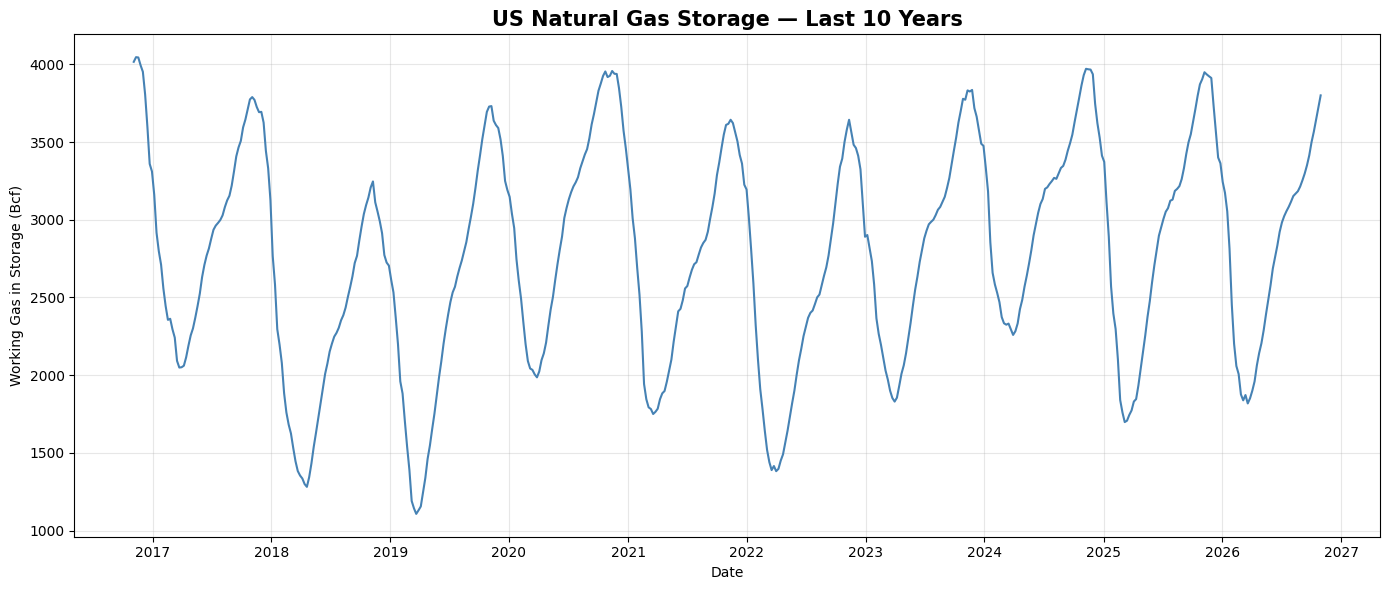

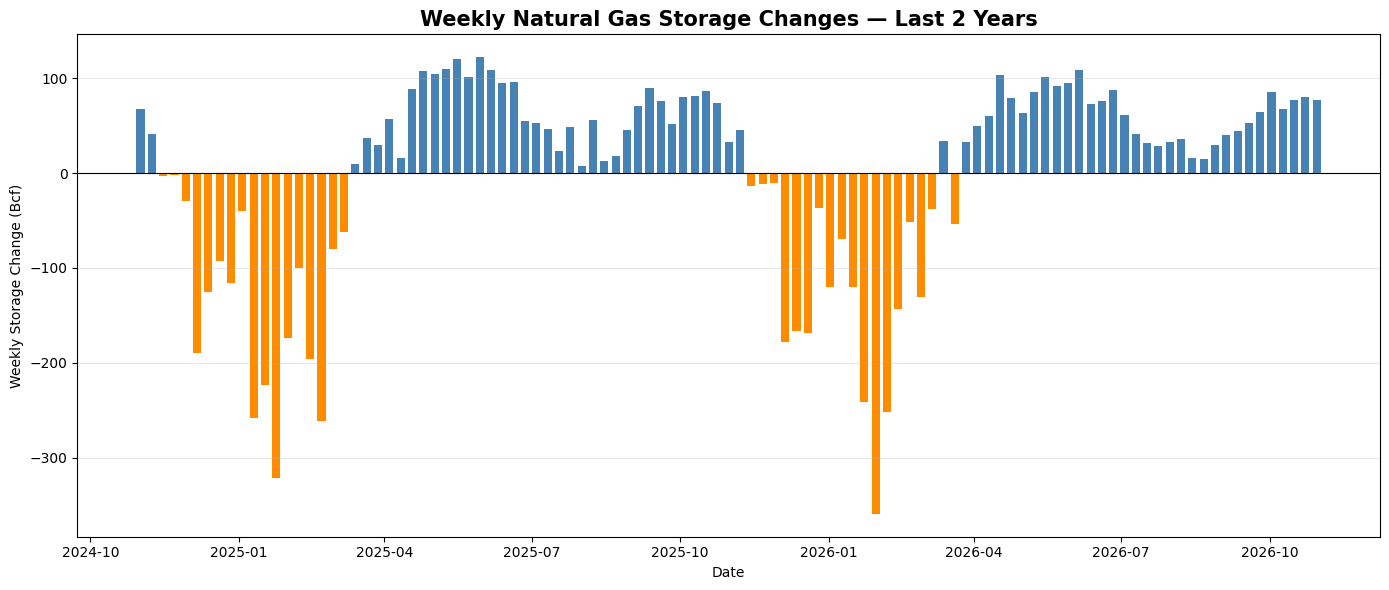

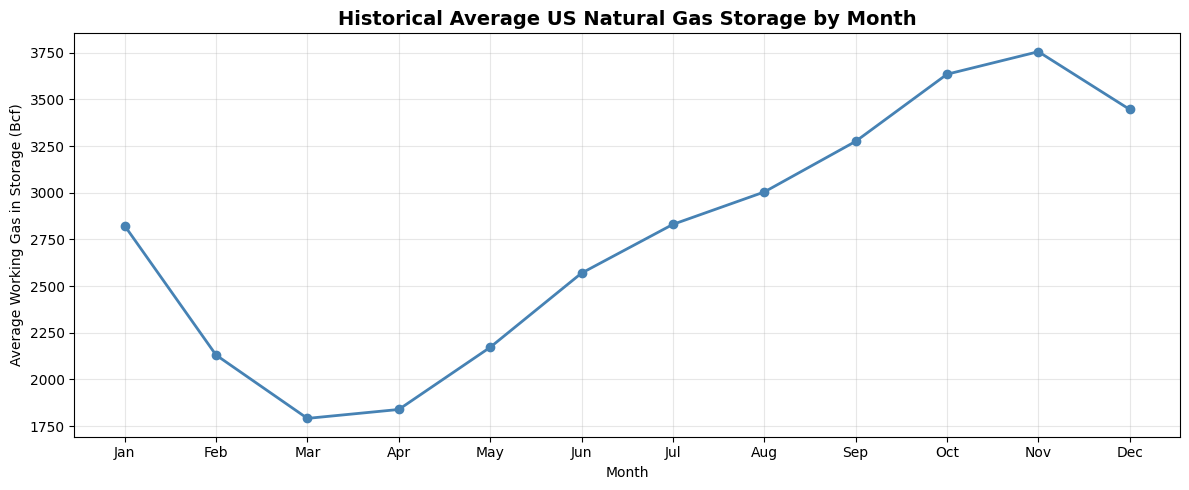


SUCCESS: Natural gas storage dataset created
File: eia_natural_gas_storage.csv
First date: 2010-01-01
Last date: 2026-10-30
Rows: 879


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

# ============================================================
# PROJECT 3 — NATURAL GAS MARKET DASHBOARD
# BATCH 2: EIA WEEKLY NATURAL GAS STORAGE
# FULL HISTORICAL DATA + INJECTIONS AND WITHDRAWALS
# ============================================================

!pip -q install xlrd

import pandas as pd
import matplotlib.pyplot as plt
import requests
from io import BytesIO
from google.colab import files

# ------------------------------------------------------------
# 1. DOWNLOAD OFFICIAL EIA HISTORICAL STORAGE DATA
# ------------------------------------------------------------

url = (
    "https://www.eia.gov/dnav/ng/hist_xls/"
    "NW2_EPG0_SWO_R48_BCFw.xls"
)

print("Downloading EIA natural gas storage data...")

response = requests.get(
    url,
    timeout=90,
    headers={"User-Agent": "Mozilla/5.0"}
)

response.raise_for_status()

# ------------------------------------------------------------
# 2. READ THE EIA EXCEL FILE
# ------------------------------------------------------------

raw = pd.read_excel(
    BytesIO(response.content),
    sheet_name="Data 1",
    header=None
)

# Identify the date and storage columns
# without relying on a fixed Excel header row.

storage = None

for col in range(raw.shape[1] - 1):

    candidate = raw.iloc[:, [col, col + 1]].copy()
    candidate.columns = ["Date", "Storage_Bcf"]

    candidate["Date"] = pd.to_datetime(
        candidate["Date"],
        errors="coerce"
    )

    candidate["Storage_Bcf"] = pd.to_numeric(
        candidate["Storage_Bcf"],
        errors="coerce"
    )

    candidate = candidate.dropna()

    candidate = candidate[
        candidate["Date"].between(
            "2000-01-01",
            "2035-12-31"
        )
    ]

    if len(candidate) >= 100:
        storage = candidate.copy()
        break

if storage is None:
    raise ValueError(
        "Could not identify the historical storage "
        "data columns in the EIA Excel file."
    )

storage = (
    storage.drop_duplicates(subset="Date")
    .sort_values("Date")
    .reset_index(drop=True)
)

# ------------------------------------------------------------
# 3. CALCULATE WEEKLY STORAGE CHANGES
# ------------------------------------------------------------

storage["Weekly_Change_Bcf"] = (
    storage["Storage_Bcf"].diff()
)

# Positive change = net stock build
# Negative change = net stock draw

storage["Injection_Bcf"] = (
    storage["Weekly_Change_Bcf"].clip(lower=0)
)

storage["Withdrawal_Bcf"] = (
    -storage["Weekly_Change_Bcf"].clip(upper=0)
)

storage["Year"] = storage["Date"].dt.year
storage["Month"] = storage["Date"].dt.month

# ------------------------------------------------------------
# 4. DISPLAY DATA COVERAGE
# ------------------------------------------------------------

first_date = storage["Date"].min()
last_date = storage["Date"].max()
latest = storage.iloc[-1]

print()
print("=" * 55)
print("EIA NATURAL GAS STORAGE ANALYSIS")
print("=" * 55)

print("Source: US Energy Information Administration")
print("Region: Lower 48 United States")
print("Units: Billion cubic feet (Bcf)")
print()

print("First observation:", first_date.date())
print("Latest observation:", last_date.date())

print(
    "Years of history:",
    round((last_date - first_date).days / 365.25, 1)
)

print("Total weekly observations:", len(storage))

print()
print(
    "Latest working gas in storage:",
    f"{latest['Storage_Bcf']:,.0f} Bcf"
)

print(
    "Latest weekly change:",
    f"{latest['Weekly_Change_Bcf']:+,.0f} Bcf"
)

print()
print("LATEST 10 WEEKS")
print(storage.tail(10).to_string(index=False))

# ------------------------------------------------------------
# 5. CHART: LAST 10 YEARS OF STORAGE LEVELS
# ------------------------------------------------------------

cutoff = last_date - pd.DateOffset(years=10)

recent = storage[
    storage["Date"] >= cutoff
].copy()

plt.figure(figsize=(14, 6))

plt.plot(
    recent["Date"],
    recent["Storage_Bcf"],
    color="steelblue",
    linewidth=1.5
)

plt.title(
    "US Natural Gas Storage — Last 10 Years",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Date")
plt.ylabel("Working Gas in Storage (Bcf)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 6. CHART: WEEKLY INJECTIONS AND WITHDRAWALS
# ------------------------------------------------------------

last_two_years = storage[
    storage["Date"] >= (
        last_date - pd.DateOffset(years=2)
    )
].copy()

bar_colours = [
    "steelblue" if change >= 0 else "darkorange"
    for change in last_two_years["Weekly_Change_Bcf"]
]

plt.figure(figsize=(14, 6))

plt.bar(
    last_two_years["Date"],
    last_two_years["Weekly_Change_Bcf"],
    color=bar_colours,
    width=5
)

plt.axhline(0, color="black", linewidth=0.8)

plt.title(
    "Weekly Natural Gas Storage Changes — Last 2 Years",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Date")
plt.ylabel("Weekly Storage Change (Bcf)")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 7. CHART: AVERAGE MONTHLY STORAGE LEVELS
# ------------------------------------------------------------

monthly_average = (
    storage.groupby("Month")["Storage_Bcf"]
    .mean()
    .reindex(range(1, 13))
)

month_names = [
    "Jan", "Feb", "Mar", "Apr",
    "May", "Jun", "Jul", "Aug",
    "Sep", "Oct", "Nov", "Dec"
]

plt.figure(figsize=(12, 5))

plt.plot(
    month_names,
    monthly_average.values,
    marker="o",
    linewidth=2,
    color="steelblue"
)

plt.title(
    "Historical Average US Natural Gas Storage by Month",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Month")
plt.ylabel("Average Working Gas in Storage (Bcf)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 8. SAVE COMPLETE HISTORICAL DATA
# ------------------------------------------------------------

filename = "eia_natural_gas_storage.csv"

storage.to_csv(filename, index=False)

print()
print("=" * 55)
print("SUCCESS: Natural gas storage dataset created")
print("File:", filename)
print("First date:", first_date.date())
print("Last date:", last_date.date())
print("Rows:", len(storage))
print("=" * 55)

# ------------------------------------------------------------
# 9. DOWNLOAD CSV
# ------------------------------------------------------------

files.download(filename)


In [ ]:

# ============================================================
# PROJECT 3 — NATURAL GAS MARKET DASHBOARD
# BATCH 3: FIVE-YEAR SEASONAL STORAGE ANALYSIS
# ============================================================

import pandas as pd
import numpy as np
import plotly.graph_objects as go
from google.colab import files

# ------------------------------------------------------------
# 1. PREPARE HISTORICAL STORAGE DATA
# ------------------------------------------------------------

# Use the storage dataset created in Batch 2.
# If the Colab session restarted, run Batch 2 first.

if "storage" not in globals():
    raise ValueError(
        "Storage data not found. Run Batch 2 first."
    )

seasonal = storage[
    ["Date", "Storage_Bcf"]
].copy()

seasonal["Date"] = pd.to_datetime(
    seasonal["Date"],
    errors="coerce"
)

seasonal["Storage_Bcf"] = pd.to_numeric(
    seasonal["Storage_Bcf"],
    errors="coerce"
)

seasonal = (
    seasonal.dropna()
    .drop_duplicates(subset="Date")
    .sort_values("Date")
    .reset_index(drop=True)
)

# Use ISO calendar weeks to align seasonal observations.
iso = seasonal["Date"].dt.isocalendar()

seasonal["ISO_Year"] = iso.year.astype(int)
seasonal["ISO_Week"] = iso.week.astype(int)

# ------------------------------------------------------------
# 2. CALCULATE PRECEDING FIVE-YEAR AVERAGES
# ------------------------------------------------------------

# First calculate one value per ISO year and week.
weekly = (
    seasonal.groupby(
        ["ISO_Year", "ISO_Week"],
        as_index=False
    )["Storage_Bcf"]
    .mean()
)

# For each observation, calculate the average of
# the SAME ISO week in the PRECEDING five years.
# Do not use future observations.

lookup = weekly.set_index(
    ["ISO_Year", "ISO_Week"]
)["Storage_Bcf"]

def calculate_five_year_average(row):

    year = int(row["ISO_Year"])
    week = int(row["ISO_Week"])

    historical_values = []

    for previous_year in range(year - 5, year):

        key = (previous_year, week)

        if key in lookup.index:
            historical_values.append(
                float(lookup.loc[key])
            )

    # Require all five historical years.
    if len(historical_values) != 5:
        return np.nan

    return float(np.mean(historical_values))


seasonal["Five_Year_Avg_Bcf"] = seasonal.apply(
    calculate_five_year_average,
    axis=1
)

# Exclude observations without five full
# preceding years of comparable weekly data.
seasonal = seasonal.dropna(
    subset=["Five_Year_Avg_Bcf"]
).copy()

if seasonal.empty:
    raise ValueError(
        "No complete five-year seasonal comparisons "
        "could be calculated."
    )

# ------------------------------------------------------------
# 3. CALCULATE STORAGE SURPLUS / DEFICIT
# ------------------------------------------------------------

seasonal["Surplus_Deficit_Bcf"] = (
    seasonal["Storage_Bcf"]
    - seasonal["Five_Year_Avg_Bcf"]
)

seasonal["Deviation_Pct"] = (
    seasonal["Surplus_Deficit_Bcf"]
    / seasonal["Five_Year_Avg_Bcf"]
    * 100
)

seasonal["Reference_Years"] = seasonal[
    "ISO_Year"
].apply(
    lambda year: f"{year - 5}-{year - 1}"
)

seasonal = seasonal.sort_values(
    "Date"
).reset_index(drop=True)

# ------------------------------------------------------------
# 4. DISPLAY LATEST MARKET METRICS
# ------------------------------------------------------------

latest = seasonal.iloc[-1]

print("=" * 60)
print("US NATURAL GAS — FIVE-YEAR STORAGE COMPARISON")
print("=" * 60)

print(
    "Latest observation:",
    latest["Date"].date()
)

print(
    "Actual storage:",
    f"{latest['Storage_Bcf']:,.0f} Bcf"
)

print(
    "Five-year seasonal average:",
    f"{latest['Five_Year_Avg_Bcf']:,.0f} Bcf"
)

print(
    "Storage surplus / deficit:",
    f"{latest['Surplus_Deficit_Bcf']:+,.0f} Bcf"
)

print(
    "Deviation from seasonal average:",
    f"{latest['Deviation_Pct']:+.2f}%"
)

print(
    "Reference years:",
    latest["Reference_Years"]
)

print()
print("LATEST 10 OBSERVATIONS")

print(
    seasonal[
        [
            "Date",
            "Storage_Bcf",
            "Five_Year_Avg_Bcf",
            "Surplus_Deficit_Bcf",
            "Deviation_Pct"
        ]
    ].tail(10).round(2).to_string(index=False)
)

# ------------------------------------------------------------
# 5. CHART: ACTUAL VS FIVE-YEAR SEASONAL AVERAGE
# ------------------------------------------------------------

# Display 10 years where available.
cutoff = (
    seasonal["Date"].max()
    - pd.DateOffset(years=10)
)

recent = seasonal[
    seasonal["Date"] >= cutoff
].copy()

fig = go.Figure()

fig.add_trace(
    go.Scatter(
        x=recent["Date"],
        y=recent["Storage_Bcf"],
        mode="lines",
        name="Actual Storage",
        line=dict(color="steelblue")
    )
)

fig.add_trace(
    go.Scatter(
        x=recent["Date"],
        y=recent["Five_Year_Avg_Bcf"],
        mode="lines",
        name="Preceding Five-Year Average",
        line=dict(
            color="darkorange",
            dash="dash"
        )
    )
)

fig.update_layout(
    title=(
        "US Natural Gas Storage vs Five-Year "
        "Seasonal Average"
    ),
    xaxis_title="Date",
    yaxis_title="Working Gas in Storage (Bcf)",
    hovermode="x unified",
    template="plotly_white",
    height=500
)

fig.show()

# ------------------------------------------------------------
# 6. CHART: STORAGE SURPLUS / DEFICIT
# ------------------------------------------------------------

fig2 = go.Figure()

fig2.add_trace(
    go.Bar(
        x=recent["Date"],
        y=recent["Surplus_Deficit_Bcf"],
        name="Storage Surplus / Deficit",
        marker_color=[
            "steelblue" if value >= 0
            else "darkorange"
            for value in recent["Surplus_Deficit_Bcf"]
        ]
    )
)

fig2.add_hline(
    y=0,
    line_color="black",
    line_width=1
)

fig2.update_layout(
    title="Natural Gas Storage Surplus / Deficit",
    xaxis_title="Date",
    yaxis_title="Deviation from Five-Year Average (Bcf)",
    template="plotly_white",
    height=450
)

fig2.show()

# ------------------------------------------------------------
# 7. AUTOMATIC MARKET COMMENTARY
# ------------------------------------------------------------

deviation = float(latest["Deviation_Pct"])

print()
print("=" * 60)
print("NATURAL GAS MARKET INTERPRETATION")
print("=" * 60)

if deviation > 5:

    print(
        f"US natural gas storage is {deviation:.1f}% "
        "above its five-year seasonal average."
    )

    print(
        "This indicates relatively comfortable "
        "inventory levels and may be bearish "
        "for natural gas prices, all else equal."
    )

elif deviation < -5:

    print(
        f"US natural gas storage is "
        f"{abs(deviation):.1f}% below its "
        "five-year seasonal average."
    )

    print(
        "This suggests relatively tight "
        "inventory levels and may support "
        "natural gas prices, all else equal."
    )

else:

    print(
        f"US natural gas storage is within 5% "
        "of its five-year seasonal average."
    )

    print(
        "Inventories are broadly in line "
        "with recent seasonal norms."
    )

print()
print(
    "Note: Price reactions also depend on "
    "market expectations, weather, production, "
    "LNG exports and other supply-demand factors."
)

# ------------------------------------------------------------
# 8. SAVE DATA FOR STREAMLIT
# ------------------------------------------------------------

filename = "eia_gas_storage_seasonality.csv"

seasonal.to_csv(
    filename,
    index=False
)

print()
print("=" * 60)
print("SUCCESS: Seasonal storage analysis complete")
print("File:", filename)
print("First comparison:", seasonal["Date"].min().date())
print("Latest comparison:", seasonal["Date"].max().date())
print("Rows:", len(seasonal))
print("=" * 60)

# ------------------------------------------------------------
# 9. DOWNLOAD CSV
# ------------------------------------------------------------

files.download(filename)


US NATURAL GAS — FIVE-YEAR STORAGE COMPARISON
Latest observation: 2026-10-30
Actual storage: 3,801 Bcf
Five-year seasonal average: 3,761 Bcf
Storage surplus / deficit: +40 Bcf
Deviation from seasonal average: +1.05%
Reference years: 2021-2025

LATEST 10 OBSERVATIONS
      Date  Storage_Bcf  Five_Year_Avg_Bcf  Surplus_Deficit_Bcf  Deviation_Pct
2026-08-28       3214.0             3074.8                139.2           4.53
2026-09-04       3254.0             3140.4                113.6           3.62
2026-09-11       3298.0             3218.6                 79.4           2.47
2026-09-18       3351.0             3299.6                 51.4           1.56
2026-09-25       3415.0             3387.6                 27.4           0.81
2026-10-02       3500.0             3478.0                 22.0           0.63
2026-10-09       3567.0             3569.4                 -2.4          -0.07
2026-10-16       3644.0             3645.0                 -1.0          -0.03
2026-10-23       3724.


NATURAL GAS MARKET INTERPRETATION
US natural gas storage is within 5% of its five-year seasonal average.
Inventories are broadly in line with recent seasonal norms.

Note: Price reactions also depend on market expectations, weather, production, LNG exports and other supply-demand factors.

SUCCESS: Seasonal storage analysis complete
File: eia_gas_storage_seasonality.csv
First comparison: 2015-01-02
Latest comparison: 2026-10-30
Rows: 616


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Weather period: 2015-01-01 to 2026-10-30

NATURAL GAS WEATHER ANALYSIS
Weather source: Open-Meteo historical archive
Locations: Chicago, New York, Dallas
Weather weighting: Equal-weight city proxy
HDD/CDD base temperature: 18 C

First weekly observation: 2015-01-09
Latest weekly observation: 2026-10-30
Matched weekly observations: 617

LATEST FIVE OBSERVATIONS
      Date  Storage_Bcf  Weekly_Change_Bcf  HDD_Weekly  CDD_Weekly  Average_Temperature_C  Withdrawal_Bcf
2026-10-02       3500.0               85.0        4.87       24.43                  20.80           -85.0
2026-10-09       3567.0               67.0       10.80       11.47                  18.10           -67.0
2026-10-16       3644.0               77.0        5.97       22.43                  20.35           -77.0
2026-10-23       3724.0               80.0       31.50        3.87                  14.05           -80.0
2026-10-30       3801.0               77.0       19.40        8.53                  16.45           -77.0


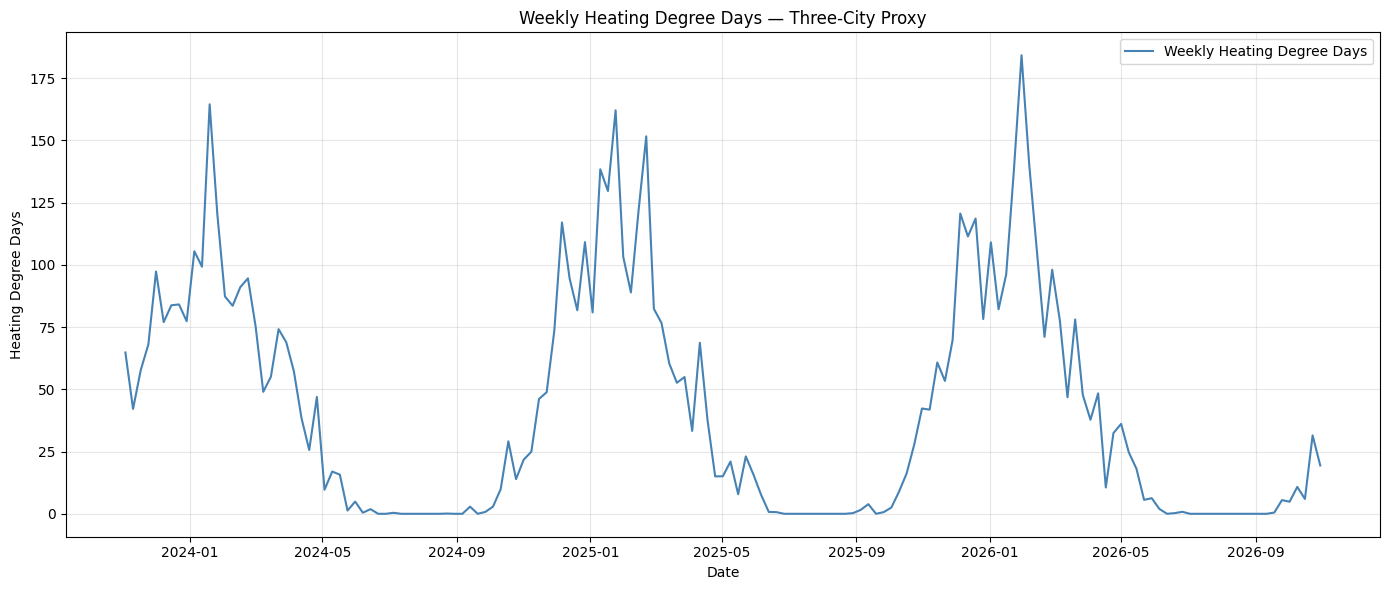

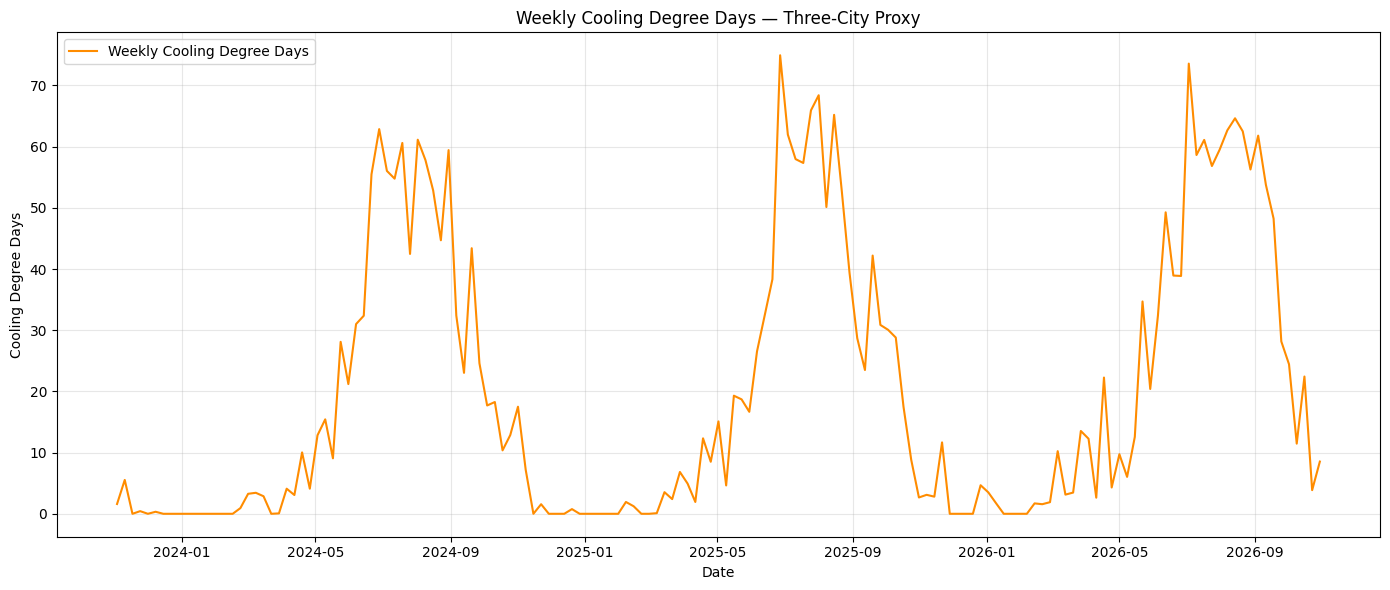

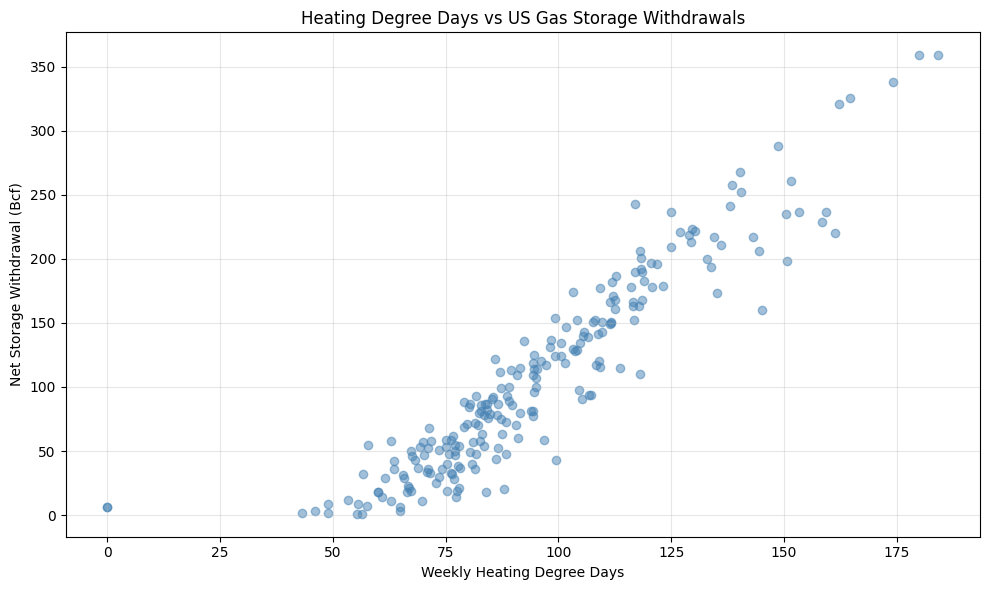


WEATHER AND STORAGE RELATIONSHIP
Correlation between weekly HDD and net withdrawals: 0.931

This is a descriptive historical correlation, not a causal estimate or price forecast.
The three-city weather proxy is not representative of all US gas demand.

SUCCESS: Weather analysis complete
File: natural_gas_weather_analysis.csv
Rows: 617


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

# ============================================================
# PROJECT 3 — NATURAL GAS MARKET DASHBOARD
# BATCH 4: WEATHER AND GAS DEMAND INDICATORS
# ============================================================

import pandas as pd
import numpy as np
import requests
import matplotlib.pyplot as plt
from google.colab import files

# ------------------------------------------------------------
# 1. LOAD EXISTING STORAGE DATA
# ------------------------------------------------------------

# If Colab has restarted, this loads the CSV
# created in Batch 2 from the session files.

try:
    storage_weather = storage.copy()
except NameError:
    storage_weather = pd.read_csv(
        "eia_natural_gas_storage.csv"
    )

storage_weather["Date"] = pd.to_datetime(
    storage_weather["Date"]
)

storage_weather = (
    storage_weather.sort_values("Date")
    .drop_duplicates("Date")
    .copy()
)

# ------------------------------------------------------------
# 2. SELECT WEATHER LOCATIONS
# ------------------------------------------------------------

cities = {
    "Chicago": (41.8781, -87.6298),
    "New York": (40.7128, -74.0060),
    "Dallas": (32.7767, -96.7970)
}

# Start in 2015 to provide over 10 years
# of historical weather observations.

start_date = "2015-01-01"

# Leave a short delay for historical weather
# data to become available.

latest_storage_date = storage_weather["Date"].max()

end_date = min(
    latest_storage_date,
    pd.Timestamp.today().normalize()
    - pd.Timedelta(days=7)
).strftime("%Y-%m-%d")

print("Weather period:", start_date, "to", end_date)

# ------------------------------------------------------------
# 3. DOWNLOAD HISTORICAL DAILY TEMPERATURES
# ------------------------------------------------------------

weather_frames = []

for city, (latitude, longitude) in cities.items():

    print("Downloading weather data for", city)

    url = "https://archive-api.open-meteo.com/v1/archive"

    params = {
        "latitude": latitude,
        "longitude": longitude,
        "start_date": start_date,
        "end_date": end_date,
        "daily": "temperature_2m_mean",
        "timezone": "UTC"
    }

    response = requests.get(
        url,
        params=params,
        timeout=120
    )

    response.raise_for_status()

    data = response.json()

    if "daily" not in data:
        raise ValueError(
            f"No daily weather data returned for {city}: "
            f"{data}"
        )

    city_weather = pd.DataFrame({
        "Date": data["daily"]["time"],
        "Temperature_C": data["daily"][
            "temperature_2m_mean"
        ]
    })

    city_weather["Date"] = pd.to_datetime(
        city_weather["Date"]
    )

    city_weather["Temperature_C"] = pd.to_numeric(
        city_weather["Temperature_C"],
        errors="coerce"
    )

    city_weather["City"] = city

    weather_frames.append(city_weather)

weather_daily = pd.concat(
    weather_frames,
    ignore_index=True
)

weather_daily = weather_daily.dropna(
    subset=["Date", "Temperature_C"]
)

if weather_daily.empty:
    raise ValueError("No valid weather data downloaded.")

# ------------------------------------------------------------
# 4. CALCULATE HEATING AND COOLING DEGREE DAYS
# ------------------------------------------------------------

# Base temperature: 18 degrees Celsius
# Approximately 65 degrees Fahrenheit.

base_temperature = 18.0

weather_daily["HDD"] = np.maximum(
    base_temperature
    - weather_daily["Temperature_C"],
    0
)

weather_daily["CDD"] = np.maximum(
    weather_daily["Temperature_C"]
    - base_temperature,
    0
)

# HDD and CDD are degree-days, not gas volumes.
# Higher HDD suggests more heating demand.
# Higher CDD suggests more cooling demand.

# ------------------------------------------------------------
# 5. BUILD AN EQUAL-WEIGHT THREE-CITY PROXY
# ------------------------------------------------------------

daily_proxy = (
    weather_daily.groupby("Date", as_index=False)
    .agg(
        HDD=("HDD", "mean"),
        CDD=("CDD", "mean"),
        Temperature_C=("Temperature_C", "mean"),
        City_Count=("City", "nunique")
    )
)

# Require all three cities for each daily value.
daily_proxy = daily_proxy[
    daily_proxy["City_Count"] == len(cities)
].copy()

# ------------------------------------------------------------
# 6. AGGREGATE TO WEEKLY WEATHER INDICATORS
# ------------------------------------------------------------

# EIA storage observations are week-ending Friday.
# Weekly HDD and CDD are sums of daily degree-days.

weather_weekly = (
    daily_proxy.set_index("Date")
    .resample("W-FRI")
    .agg(
        HDD_Weekly=("HDD", "sum"),
        CDD_Weekly=("CDD", "sum"),
        Average_Temperature_C=(
            "Temperature_C", "mean"
        ),
        Days_Observed=("HDD", "count")
    )
    .reset_index()
)

# Only use complete seven-day weather weeks.
weather_weekly = weather_weekly[
    weather_weekly["Days_Observed"] == 7
].copy()

# ------------------------------------------------------------
# 7. JOIN WEATHER WITH EIA STORAGE
# ------------------------------------------------------------

combined = pd.merge(
    storage_weather[
        ["Date", "Storage_Bcf", "Weekly_Change_Bcf"]
    ],
    weather_weekly[
        [
            "Date",
            "HDD_Weekly",
            "CDD_Weekly",
            "Average_Temperature_C"
        ]
    ],
    on="Date",
    how="inner"
)

combined = combined.dropna().sort_values("Date")

if combined.empty:
    raise ValueError(
        "No matching weekly weather and storage dates. "
        "Check the dates in the EIA dataset."
    )

combined["Withdrawal_Bcf"] = (
    -combined["Weekly_Change_Bcf"]
)

# ------------------------------------------------------------
# 8. DISPLAY DATA COVERAGE
# ------------------------------------------------------------

print()
print("=" * 55)
print("NATURAL GAS WEATHER ANALYSIS")
print("=" * 55)

print("Weather source: Open-Meteo historical archive")
print("Locations: Chicago, New York, Dallas")
print("Weather weighting: Equal-weight city proxy")
print("HDD/CDD base temperature: 18 C")
print()

print(
    "First weekly observation:",
    combined["Date"].min().date()
)

print(
    "Latest weekly observation:",
    combined["Date"].max().date()
)

print("Matched weekly observations:", len(combined))

print()
print("LATEST FIVE OBSERVATIONS")
print(combined.tail(5).round(2).to_string(index=False))

# ------------------------------------------------------------
# 9. CHART: WEEKLY HEATING DEGREE DAYS
# ------------------------------------------------------------

cutoff = (
    combined["Date"].max()
    - pd.DateOffset(years=3)
)

recent = combined[
    combined["Date"] >= cutoff
].copy()

plt.figure(figsize=(14, 6))

plt.plot(
    recent["Date"],
    recent["HDD_Weekly"],
    label="Weekly Heating Degree Days",
    color="steelblue"
)

plt.title(
    "Weekly Heating Degree Days — Three-City Proxy"
)

plt.xlabel("Date")
plt.ylabel("Heating Degree Days")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 10. CHART: WEEKLY COOLING DEGREE DAYS
# ------------------------------------------------------------

plt.figure(figsize=(14, 6))

plt.plot(
    recent["Date"],
    recent["CDD_Weekly"],
    label="Weekly Cooling Degree Days",
    color="darkorange"
)

plt.title(
    "Weekly Cooling Degree Days — Three-City Proxy"
)

plt.xlabel("Date")
plt.ylabel("Cooling Degree Days")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 11. CHART: HEATING DEMAND VS STORAGE WITHDRAWALS
# ------------------------------------------------------------

# Focus on weeks with net storage withdrawals.
winter_data = combined[
    combined["Weekly_Change_Bcf"] < 0
].copy()

plt.figure(figsize=(10, 6))

plt.scatter(
    winter_data["HDD_Weekly"],
    winter_data["Withdrawal_Bcf"],
    alpha=0.5,
    color="steelblue"
)

plt.title(
    "Heating Degree Days vs US Gas Storage Withdrawals"
)

plt.xlabel("Weekly Heating Degree Days")
plt.ylabel("Net Storage Withdrawal (Bcf)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 12. SIMPLE STATISTICAL COMPARISON
# ------------------------------------------------------------

correlation = winter_data[
    ["HDD_Weekly", "Withdrawal_Bcf"]
].corr().iloc[0, 1]

print()
print("=" * 55)
print("WEATHER AND STORAGE RELATIONSHIP")
print("=" * 55)

print(
    "Correlation between weekly HDD "
    "and net withdrawals:",
    f"{correlation:.3f}"
)

print()
print(
    "This is a descriptive historical correlation, "
    "not a causal estimate or price forecast."
)

print(
    "The three-city weather proxy is not "
    "representative of all US gas demand."
)

# ------------------------------------------------------------
# 13. SAVE WEATHER AND STORAGE DATA
# ------------------------------------------------------------

filename = "natural_gas_weather_analysis.csv"

combined.to_csv(
    filename,
    index=False
)

print()
print("=" * 55)
print("SUCCESS: Weather analysis complete")
print("File:", filename)
print("Rows:", len(combined))
print("=" * 55)

files.download(filename)


In [ ]:

# ============================================================
# PROJECT 3 — NATURAL GAS MARKET DASHBOARD
# BATCH 5: COMBINED MARKET ANALYSIS
# ============================================================

import pandas as pd
import numpy as np
import plotly.graph_objects as go
import matplotlib.pyplot as plt
from pathlib import Path
from google.colab import files

# ------------------------------------------------------------
# 1. LOAD DATASETS FROM PREVIOUS BATCHES
# ------------------------------------------------------------

required_files = [
    "henry_hub_prices.csv",
    "eia_natural_gas_storage.csv",
    "eia_gas_storage_seasonality.csv",
    "natural_gas_weather_analysis.csv"
]

missing_files = [
    name for name in required_files
    if not Path(name).exists()
]

if missing_files:
    raise FileNotFoundError(
        "Missing CSV files: "
        + ", ".join(missing_files)
        + ". Run the earlier Colab cells again "
        "or upload these files to the Colab session."
    )

prices = pd.read_csv(
    "henry_hub_prices.csv",
    parse_dates=["Date"]
)

storage_data = pd.read_csv(
    "eia_natural_gas_storage.csv",
    parse_dates=["Date"]
)

seasonal_data = pd.read_csv(
    "eia_gas_storage_seasonality.csv",
    parse_dates=["Date"]
)

weather_data = pd.read_csv(
    "natural_gas_weather_analysis.csv",
    parse_dates=["Date"]
)

# ------------------------------------------------------------
# 2. PREPARE WEEKLY HENRY HUB PRICES
# ------------------------------------------------------------

# Calculate the average of available daily prices
# for each week ending on Friday.
# This is a weekly average, not a Friday closing price.

prices["Henry_Hub_USD_MMBtu"] = pd.to_numeric(
    prices["Henry_Hub_USD_MMBtu"],
    errors="coerce"
)

weekly_prices = (
    prices.dropna(
        subset=["Date", "Henry_Hub_USD_MMBtu"]
    )
    .set_index("Date")
    .resample("W-FRI")
    .agg(
        Henry_Hub_Weekly_Avg=(
            "Henry_Hub_USD_MMBtu", "mean"
        ),
        Price_Observations=(
            "Henry_Hub_USD_MMBtu", "count"
        )
    )
    .reset_index()
)

weekly_prices = weekly_prices[
    weekly_prices["Price_Observations"] > 0
].copy()

# ------------------------------------------------------------
# 3. COMBINE PRICES, STORAGE AND WEATHER
# ------------------------------------------------------------

# Use the seasonal dataset as the main table.
# It already includes actual storage levels,
# seasonal averages and storage deviations.

combined = seasonal_data[
    [
        "Date",
        "Storage_Bcf",
        "Five_Year_Avg_Bcf",
        "Surplus_Deficit_Bcf",
        "Deviation_Pct",
        "Reference_Years"
    ]
].copy()

combined = combined.merge(
    storage_data[
        ["Date", "Weekly_Change_Bcf"]
    ],
    on="Date",
    how="left",
    validate="one_to_one"
)

combined = combined.merge(
    weekly_prices[
        ["Date", "Henry_Hub_Weekly_Avg"]
    ],
    on="Date",
    how="left",
    validate="one_to_one"
)

combined = combined.merge(
    weather_data[
        [
            "Date",
            "HDD_Weekly",
            "CDD_Weekly",
            "Average_Temperature_C"
        ]
    ],
    on="Date",
    how="left",
    validate="one_to_one"
)

# Keep weeks with complete observations
# for all four main analytical components.

combined = (
    combined.dropna(
        subset=[
            "Storage_Bcf",
            "Five_Year_Avg_Bcf",
            "Weekly_Change_Bcf",
            "Henry_Hub_Weekly_Avg",
            "HDD_Weekly",
            "CDD_Weekly"
        ]
    )
    .sort_values("Date")
    .reset_index(drop=True)
)

if combined.empty:
    raise ValueError(
        "No matching observations across the datasets. "
        "Check the dates in your CSV files."
    )

# ------------------------------------------------------------
# 4. CALCULATE ADDITIONAL MARKET INDICATORS
# ------------------------------------------------------------

combined["Net_Withdrawal_Bcf"] = (
    -combined["Weekly_Change_Bcf"]
)

combined["Price_Change_USD_MMBtu"] = (
    combined["Henry_Hub_Weekly_Avg"].diff()
)

combined["Price_Change_Pct"] = (
    combined["Henry_Hub_Weekly_Avg"]
    .pct_change(fill_method=None)
    * 100
)

combined["Year"] = combined["Date"].dt.year

# ------------------------------------------------------------
# 5. DISPLAY COVERAGE AND LATEST MARKET METRICS
# ------------------------------------------------------------

latest = combined.iloc[-1]

print("=" * 60)
print("COMBINED US NATURAL GAS MARKET ANALYSIS")
print("=" * 60)

print("First observation:", combined["Date"].min().date())
print("Latest observation:", combined["Date"].max().date())
print("Weekly observations:", len(combined))

print()
print("LATEST MARKET INDICATORS")

print(
    "Henry Hub weekly average:",
    f"${latest['Henry_Hub_Weekly_Avg']:.2f}/MMBtu"
)

print(
    "Working gas in storage:",
    f"{latest['Storage_Bcf']:,.0f} Bcf"
)

print(
    "Storage deviation:",
    f"{latest['Surplus_Deficit_Bcf']:+,.0f} Bcf"
)

print(
    "Storage deviation (%):",
    f"{latest['Deviation_Pct']:+.2f}%"
)

print(
    "Weekly storage change:",
    f"{latest['Weekly_Change_Bcf']:+,.0f} Bcf"
)

print(
    "Weekly HDD proxy:",
    f"{latest['HDD_Weekly']:.1f}"
)

print(
    "Weekly CDD proxy:",
    f"{latest['CDD_Weekly']:.1f}"
)

# ------------------------------------------------------------
# 6. CHART: HENRY HUB PRICE AND STORAGE DEVIATION
# ------------------------------------------------------------

recent = combined[
    combined["Date"] >= (
        combined["Date"].max()
        - pd.DateOffset(years=5)
    )
].copy()

fig = go.Figure()

fig.add_trace(
    go.Scatter(
        x=recent["Date"],
        y=recent["Henry_Hub_Weekly_Avg"],
        name="Henry Hub Weekly Average",
        mode="lines",
        line=dict(color="steelblue")
    )
)

fig.add_trace(
    go.Scatter(
        x=recent["Date"],
        y=recent["Surplus_Deficit_Bcf"],
        name="Storage Surplus / Deficit",
        mode="lines",
        yaxis="y2",
        line=dict(color="darkorange")
    )
)

fig.update_layout(
    title="Henry Hub Prices vs Storage Surplus / Deficit",
    xaxis_title="Date",
    yaxis=dict(
        title="Henry Hub Price (USD/MMBtu)"
    ),
    yaxis2=dict(
        title="Storage Deviation (Bcf)",
        overlaying="y",
        side="right",
        showgrid=False
    ),
    hovermode="x unified",
    template="plotly_white",
    height=500
)

fig.show()

# ------------------------------------------------------------
# 7. CHART: HEATING DEGREE DAYS VS GAS PRICE
# ------------------------------------------------------------

fig2 = go.Figure()

fig2.add_trace(
    go.Scatter(
        x=combined["HDD_Weekly"],
        y=combined["Henry_Hub_Weekly_Avg"],
        mode="markers",
        name="Weekly Observations",
        marker=dict(
            color="steelblue",
            opacity=0.5
        )
    )
)

fig2.update_layout(
    title="Heating Degree Days vs Henry Hub Prices",
    xaxis_title="Weekly HDD — Three-City Proxy",
    yaxis_title="Henry Hub Weekly Average (USD/MMBtu)",
    template="plotly_white",
    height=450
)

fig2.show()

# ------------------------------------------------------------
# 8. CALCULATE HISTORICAL CORRELATIONS
# ------------------------------------------------------------

analysis_columns = [
    "Henry_Hub_Weekly_Avg",
    "Surplus_Deficit_Bcf",
    "Weekly_Change_Bcf",
    "HDD_Weekly",
    "CDD_Weekly"
]

correlation_matrix = combined[
    analysis_columns
].corr()

print()
print("=" * 60)
print("HISTORICAL CORRELATION MATRIX")
print("=" * 60)

print(correlation_matrix.round(3).to_string())

# ------------------------------------------------------------
# 9. AUTOMATED MARKET SUMMARY
# ------------------------------------------------------------

print()
print("=" * 60)
print("LATEST NATURAL GAS MARKET SUMMARY")
print("=" * 60)

print(
    "As of",
    latest["Date"].date(),
    "the Henry Hub weekly average was",
    f"${latest['Henry_Hub_Weekly_Avg']:.2f}/MMBtu."
)

if latest["Deviation_Pct"] > 5:
    print(
        "US gas inventories are materially above "
        "their preceding five-year seasonal average, "
        "indicating relatively comfortable stocks."
    )

elif latest["Deviation_Pct"] < -5:
    print(
        "US gas inventories are materially below "
        "their preceding five-year seasonal average, "
        "suggesting a relatively tighter stock position."
    )

else:
    print(
        "US gas inventories are broadly in line "
        "with their preceding five-year seasonal average."
    )

if latest["Weekly_Change_Bcf"] > 0:
    print(
        "The latest storage week recorded a net "
        "injection of",
        f"{latest['Weekly_Change_Bcf']:.0f} Bcf."
    )

elif latest["Weekly_Change_Bcf"] < 0:
    print(
        "The latest storage week recorded a net "
        "withdrawal of",
        f"{abs(latest['Weekly_Change_Bcf']):.0f} Bcf."
    )

else:
    print("Storage was unchanged over the latest week.")

print()
print(
    "Interpretation: These indicators provide "
    "historical market context, not a trading signal. "
    "Price changes also depend on supply, LNG exports, "
    "weather forecasts and market expectations."
)

# ------------------------------------------------------------
# 10. SAVE COMBINED DATA FOR STREAMLIT
# ------------------------------------------------------------

filename = "natural_gas_combined_market_data.csv"

combined.to_csv(filename, index=False)

print()
print("=" * 60)
print("SUCCESS: Combined natural gas dataset created")
print("File:", filename)
print("Rows:", len(combined))
print("=" * 60)

files.download(filename)


COMBINED US NATURAL GAS MARKET ANALYSIS
First observation: 2015-01-09
Latest observation: 2026-10-30
Weekly observations: 615

LATEST MARKET INDICATORS
Henry Hub weekly average: $2.65/MMBtu
Working gas in storage: 3,801 Bcf
Storage deviation: +40 Bcf
Storage deviation (%): +1.05%
Weekly storage change: +77 Bcf
Weekly HDD proxy: 19.4
Weekly CDD proxy: 8.5



HISTORICAL CORRELATION MATRIX
                      Henry_Hub_Weekly_Avg  Surplus_Deficit_Bcf  Weekly_Change_Bcf  HDD_Weekly  CDD_Weekly
Henry_Hub_Weekly_Avg                 1.000               -0.443             -0.147       0.105       0.036
Surplus_Deficit_Bcf                 -0.443                1.000              0.088      -0.122       0.037
Weekly_Change_Bcf                   -0.147                0.088              1.000      -0.912       0.471
HDD_Weekly                           0.105               -0.122             -0.912       1.000      -0.750
CDD_Weekly                           0.036                0.037              0.471      -0.750       1.000

LATEST NATURAL GAS MARKET SUMMARY
As of 2026-10-30 the Henry Hub weekly average was $2.65/MMBtu.
US gas inventories are broadly in line with their preceding five-year seasonal average.
The latest storage week recorded a net injection of 77 Bcf.

Interpretation: These indicators provide historical market context, not a tradin

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
from google.colab import files
from pathlib import Path

filename = "natural_gas_combined_market_data.csv"

if Path(filename).exists():
    print("CSV found. Starting download...")
    files.download(filename)
else:
    print("CSV not found. Saving the combined dataset...")
    if "combined" not in globals():
        raise ValueError(
            "Combined data is not available. Run Batch 5 again."
        )
    combined.to_csv(filename, index=False)
    files.download(filename)

print("Download requested:", filename)

CSV found. Starting download...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Download requested: natural_gas_combined_market_data.csv


NATURAL GAS STORAGE FORECAST
Origin: 2026-10-30
Starting storage: 3801 Bcf

4-WEEK FORECAST
Date: 2026-11-27
Base: 3747 Bcf
Higher storage: 3827 Bcf
Lower storage: 3667 Bcf

8-WEEK FORECAST
Date: 2026-12-25
Base: 3307 Bcf
Higher storage: 3467 Bcf
Lower storage: 3147 Bcf

12-WEEK FORECAST
Date: 2027-01-22
Base: 2781 Bcf
Higher storage: 3021 Bcf
Lower storage: 2541 Bcf


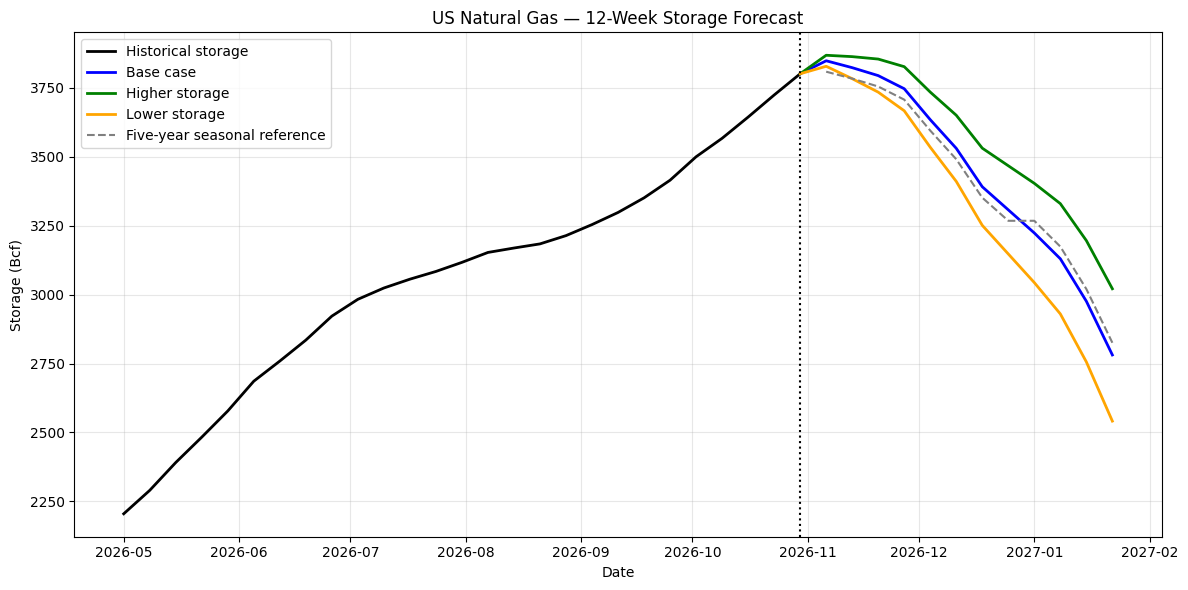


HISTORICAL BACKTEST
 Horizon_Weeks  Tests  Model_MAE_Bcf  Naive_MAE_Bcf  Improvement_Pct
             4     47          80.44         301.49            73.32
             8     47         116.61         618.04            81.13
            12     47         162.75         805.11            79.79

SUCCESS: Batch 6 forecasting completed.
Both CSV files created.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

# ============================================================
# BATCH 6 FIX — ROBUST STORAGE FORECASTING
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from google.colab import files

# 1. Load storage data

filename = "eia_natural_gas_storage.csv"

if not Path(filename).exists():
    print("Please upload your EIA storage CSV.")
    uploaded = files.upload()

history = pd.read_csv(
    filename,
    parse_dates=["Date"]
)

history["Storage_Bcf"] = pd.to_numeric(
    history["Storage_Bcf"],
    errors="coerce"
)

history = (
    history.dropna(subset=["Date", "Storage_Bcf"])
    .drop_duplicates("Date")
    .sort_values("Date")
    .reset_index(drop=True)
)

history["Weekly_Change_Bcf"] = (
    history["Storage_Bcf"].diff()
)

history.loc[
    history["Date"].diff().dt.days != 7,
    "Weekly_Change_Bcf"
] = np.nan

# ISO calendar week can be 53.
# Use ISO week 52 as the seasonal proxy for week 53.

iso = history["Date"].dt.isocalendar()
history["ISO_Week"] = (
    iso.week.astype(int).clip(upper=52)
)

# 2. Seasonal weekly change model

def seasonal_change(target_date, training_data):

    target_date = pd.Timestamp(target_date)
    target_week = min(
        int(target_date.isocalendar().week),
        52
    )

    # The latest five available observations
    # for the same seasonal week.
    matches = training_data[
        (training_data["Date"] < target_date)
        & (training_data["ISO_Week"] == target_week)
    ].dropna(subset=["Weekly_Change_Bcf"])

    values = matches.tail(5)[
        "Weekly_Change_Bcf"
    ]

    if len(values) < 3:
        return np.nan

    return float(values.mean())


def make_forecast(
    origin_date,
    starting_storage,
    training_data,
    weeks=12
):

    rows = []
    level = float(starting_storage)

    for step in range(1, weeks + 1):

        target_date = (
            pd.Timestamp(origin_date)
            + pd.Timedelta(weeks=step)
        )

        change = seasonal_change(
            target_date,
            training_data
        )

        if not np.isfinite(change):
            return None

        level += change

        rows.append({
            "Date": target_date,
            "Week_Ahead": step,
            "Forecast_Weekly_Change_Bcf": change,
            "Base_Forecast_Bcf": level
        })

    return pd.DataFrame(rows)


# 3. Latest forecast

latest = history.iloc[-1]

origin_date = latest["Date"]
starting_storage = float(
    latest["Storage_Bcf"]
)

forecast = make_forecast(
    origin_date,
    starting_storage,
    history[history["Date"] <= origin_date],
    weeks=12
)

if forecast is None:
    raise ValueError(
        "Insufficient seasonal data. "
        "Please check the storage CSV."
    )

# 4. Scenario forecasts

adjustment = 20.0

forecast["Higher_Storage_Bcf"] = (
    forecast["Base_Forecast_Bcf"]
    + adjustment * forecast["Week_Ahead"]
)

forecast["Lower_Storage_Bcf"] = (
    forecast["Base_Forecast_Bcf"]
    - adjustment * forecast["Week_Ahead"]
)

# Historical seasonal inventory reference

def storage_reference(target_date):

    target_week = min(
        int(pd.Timestamp(target_date).isocalendar().week),
        52
    )

    values = history[
        (history["Date"] <= origin_date)
        & (history["ISO_Week"] == target_week)
    ]["Storage_Bcf"].tail(5)

    if len(values) < 3:
        return np.nan

    return float(values.mean())


forecast["Five_Year_Avg_Bcf"] = (
    forecast["Date"].apply(storage_reference)
)

forecast["Base_Deviation_Bcf"] = (
    forecast["Base_Forecast_Bcf"]
    - forecast["Five_Year_Avg_Bcf"]
)

forecast["Forecast_Origin_Date"] = (
    origin_date.date()
)

forecast["Starting_Storage_Bcf"] = (
    starting_storage
)

forecast["Scenario_Adjustment_Bcf_Per_Week"] = (
    adjustment
)

# 5. Forecast summary

print("=" * 55)
print("NATURAL GAS STORAGE FORECAST")
print("=" * 55)
print("Origin:", origin_date.date())
print("Starting storage:", round(starting_storage), "Bcf")

for horizon in [4, 8, 12]:

    row = forecast.iloc[horizon - 1]

    print()
    print(f"{horizon}-WEEK FORECAST")
    print("Date:", row["Date"].date())
    print(
        "Base:",
        round(row["Base_Forecast_Bcf"]),
        "Bcf"
    )
    print(
        "Higher storage:",
        round(row["Higher_Storage_Bcf"]),
        "Bcf"
    )
    print(
        "Lower storage:",
        round(row["Lower_Storage_Bcf"]),
        "Bcf"
    )

# 6. Plot forecast

recent = history[
    history["Date"] >= (
        origin_date - pd.Timedelta(weeks=26)
    )
]

plt.figure(figsize=(12, 6))

plt.plot(
    recent["Date"],
    recent["Storage_Bcf"],
    color="black",
    linewidth=2,
    label="Historical storage"
)

dates = [origin_date] + forecast["Date"].tolist()

for column, label, color in [
    ("Base_Forecast_Bcf", "Base case", "blue"),
    ("Higher_Storage_Bcf", "Higher storage", "green"),
    ("Lower_Storage_Bcf", "Lower storage", "orange")
]:

    values = (
        [starting_storage]
        + forecast[column].tolist()
    )

    plt.plot(
        dates,
        values,
        linewidth=2,
        color=color,
        label=label
    )

plt.plot(
    forecast["Date"],
    forecast["Five_Year_Avg_Bcf"],
    linestyle="--",
    color="grey",
    label="Five-year seasonal reference"
)

plt.axvline(
    origin_date,
    linestyle=":",
    color="black"
)

plt.title("US Natural Gas — 12-Week Storage Forecast")
plt.xlabel("Date")
plt.ylabel("Storage (Bcf)")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

# 7. Historical backtest

actuals = history.set_index("Date")[
    "Storage_Bcf"
]

rows = []

# Quarterly historical forecast origins
for origin in history.iloc[260:-12:13].itertuples():

    training = history[
        history["Date"] <= origin.Date
    ]

    prediction = make_forecast(
        origin.Date,
        origin.Storage_Bcf,
        training,
        weeks=12
    )

    if prediction is None:
        continue

    for horizon in [4, 8, 12]:

        result = prediction.iloc[horizon - 1]
        target_date = result["Date"]

        if target_date not in actuals.index:
            continue

        actual = float(actuals.loc[target_date])
        predicted = float(
            result["Base_Forecast_Bcf"]
        )

        naive = float(origin.Storage_Bcf)

        rows.append({
            "Origin_Date": origin.Date,
            "Target_Date": target_date,
            "Horizon_Weeks": horizon,
            "Actual_Bcf": actual,
            "Forecast_Bcf": predicted,
            "Naive_Forecast_Bcf": naive,
            "Absolute_Error_Bcf": abs(
                actual - predicted
            ),
            "Naive_Absolute_Error_Bcf": abs(
                actual - naive
            )
        })

backtest = pd.DataFrame(rows)

if backtest.empty:
    raise ValueError(
        "No valid historical backtests were generated."
    )

results = (
    backtest.groupby("Horizon_Weeks")
    .agg(
        Tests=("Actual_Bcf", "count"),
        Model_MAE_Bcf=("Absolute_Error_Bcf", "mean"),
        Naive_MAE_Bcf=(
            "Naive_Absolute_Error_Bcf",
            "mean"
        )
    )
    .reset_index()
)

results["Improvement_Pct"] = (
    1 - (
        results["Model_MAE_Bcf"]
        / results["Naive_MAE_Bcf"]
    )
) * 100

print()
print("=" * 55)
print("HISTORICAL BACKTEST")
print("=" * 55)
print(results.round(2).to_string(index=False))

# 8. Save and download

forecast_file = "natural_gas_storage_forecast.csv"
backtest_file = "natural_gas_forecast_backtest.csv"

forecast.to_csv(forecast_file, index=False)
backtest.to_csv(backtest_file, index=False)

print()
print("SUCCESS: Batch 6 forecasting completed.")
print("Both CSV files created.")

files.download(forecast_file)
files.download(backtest_file)


SUCCESS: Storage and weather data merged.
First date: 2015-01-09
Latest date: 2026-10-30
Weekly observations: 617

WEATHER-DRIVEN NATURAL GAS STORAGE FORECAST
Origin: 2026-10-30
Starting storage: 3801 Bcf
Weather assumption: historical seasonal averages

4-WEEK FORECAST
Target: 2026-11-27
Weather model: 3704 Bcf
Seasonal model: 3747 Bcf

8-WEEK FORECAST
Target: 2026-12-25
Weather model: 3295 Bcf
Seasonal model: 3307 Bcf

12-WEEK FORECAST
Target: 2027-01-22
Weather model: 2785 Bcf
Seasonal model: 2781 Bcf


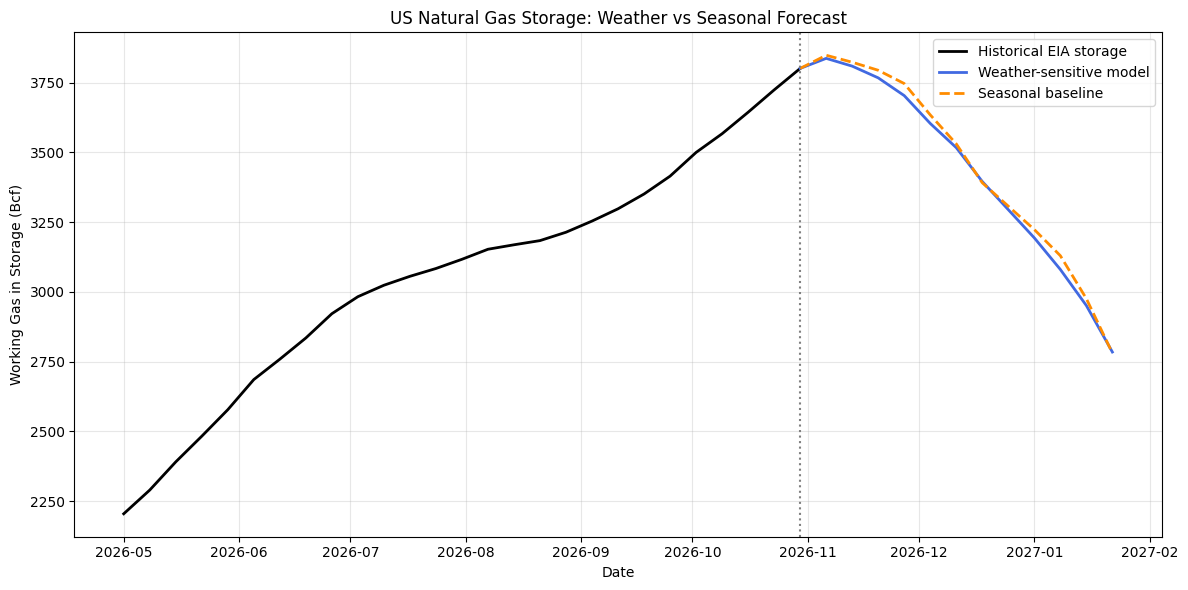


OUT-OF-SAMPLE FORECAST COMPARISON
MAE = average absolute storage error in Bcf.
Lower MAE indicates better historical accuracy.

 Horizon_Weeks  Tests  Weather_MAE_Bcf  Seasonal_MAE_Bcf  Naive_MAE_Bcf  Weather_vs_Seasonal_Improvement_Pct
             4     31           108.73             80.31         342.03                               -35.39
             8     31           177.16            119.17         635.16                               -48.66
            12     31           180.78            150.69         796.84                               -19.97


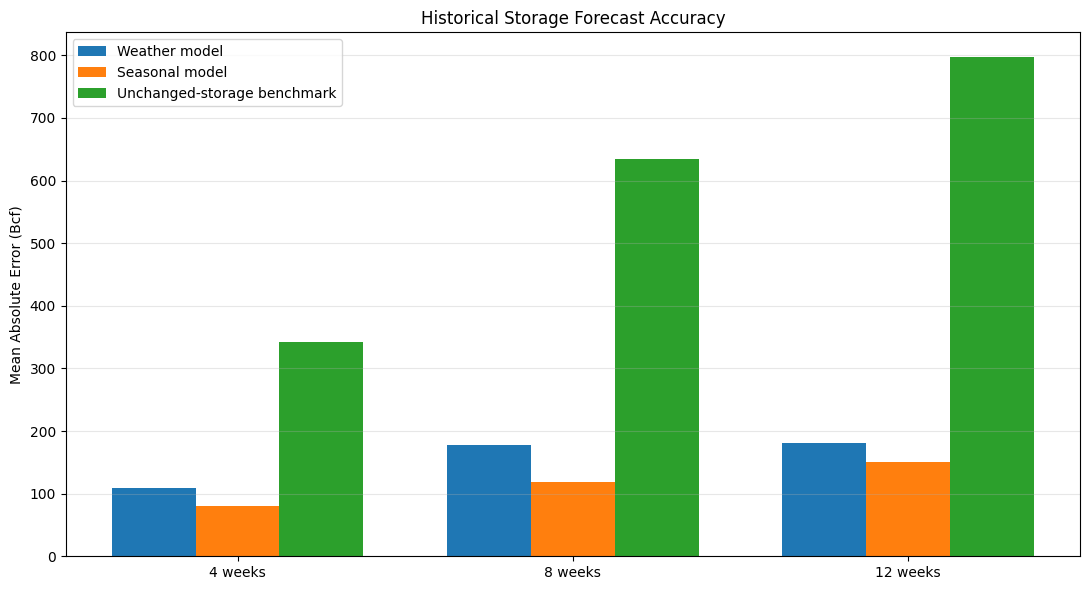


SUCCESS: BATCH 7 COMPLETED
Files created:
natural_gas_weather_forecast.csv
natural_gas_weather_backtest.csv
natural_gas_model_comparison.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

# ============================================================
# PROJECT 3 — BATCH 7
# WEATHER-DRIVEN NATURAL GAS STORAGE FORECASTING
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from google.colab import files

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge

# ------------------------------------------------------------
# 1. LOAD THE TWO EXISTING DATASETS
# ------------------------------------------------------------

required_files = [
    "eia_natural_gas_storage.csv",
    "natural_gas_weather_analysis.csv"
]

for filename in required_files:
    if not Path(filename).exists():
        print("Please upload:", filename)
        files.upload()

storage = pd.read_csv(
    "eia_natural_gas_storage.csv",
    parse_dates=["Date"]
)

weather = pd.read_csv(
    "natural_gas_weather_analysis.csv",
    parse_dates=["Date"]
)

storage["Storage_Bcf"] = pd.to_numeric(
    storage["Storage_Bcf"], errors="coerce"
)

storage = (
    storage[["Date", "Storage_Bcf"]]
    .dropna()
    .drop_duplicates("Date")
    .sort_values("Date")
    .reset_index(drop=True)
)

storage["Weekly_Change_Bcf"] = (
    storage["Storage_Bcf"].diff()
)

storage.loc[
    storage["Date"].diff().dt.days != 7,
    "Weekly_Change_Bcf"
] = np.nan

weather_columns = [
    "Date", "HDD_Weekly", "CDD_Weekly"
]

weather = weather[weather_columns].copy()

for col in ["HDD_Weekly", "CDD_Weekly"]:
    weather[col] = pd.to_numeric(
        weather[col], errors="coerce"
    )

weather = (
    weather.drop_duplicates("Date")
    .sort_values("Date")
)

data = pd.merge(
    storage,
    weather,
    on="Date",
    how="inner"
)

data = data.dropna(
    subset=[
        "Storage_Bcf",
        "Weekly_Change_Bcf",
        "HDD_Weekly",
        "CDD_Weekly"
    ]
).sort_values("Date").reset_index(drop=True)

# Seasonal calendar features
iso = data["Date"].dt.isocalendar()

data["Seasonal_Week"] = (
    iso.week.astype(int).clip(upper=52)
)

data["Season_Sin"] = np.sin(
    2 * np.pi * data["Seasonal_Week"] / 52
)

data["Season_Cos"] = np.cos(
    2 * np.pi * data["Seasonal_Week"] / 52
)

print("SUCCESS: Storage and weather data merged.")
print("First date:", data["Date"].min().date())
print("Latest date:", data["Date"].max().date())
print("Weekly observations:", len(data))

if len(data) < 260:
    raise ValueError(
        "Insufficient historical observations "
        "for weather-model training."
    )

# ------------------------------------------------------------
# 2. DEFINE FORECAST FEATURES
# ------------------------------------------------------------

feature_cols = [
    "HDD_Weekly",
    "CDD_Weekly",
    "Season_Sin",
    "Season_Cos"
]

def week_number(date):
    return min(
        int(pd.Timestamp(date).isocalendar().week),
        52
    )


def seasonal_weather(target_date, training):

    # Estimate FUTURE HDD/CDD from the previous
    # five historical observations for the same
    # calendar week.
    #
    # No actual future weather is used.

    week = week_number(target_date)

    matches = training[
        (training["Date"] < target_date)
        & (training["Seasonal_Week"] == week)
    ].tail(5)

    if len(matches) < 3:
        return None

    return {
        "HDD_Weekly": float(
            matches["HDD_Weekly"].mean()
        ),
        "CDD_Weekly": float(
            matches["CDD_Weekly"].mean()
        )
    }


def seasonal_storage_change(
    target_date, training
):

    week = week_number(target_date)

    matches = training[
        (training["Date"] < target_date)
        & (training["Seasonal_Week"] == week)
    ].tail(5)

    if len(matches) < 3:
        return np.nan

    return float(
        matches["Weekly_Change_Bcf"].mean()
    )


# ------------------------------------------------------------
# 3. TRAIN AND FORECAST
# ------------------------------------------------------------

def create_forecast(
    origin_date,
    starting_storage,
    training,
    horizon=12
):

    # Train only on data available at the origin.
    training = training[
        training["Date"] <= origin_date
    ].copy()

    if len(training) < 156:
        return None

    model = make_pipeline(
        StandardScaler(),
        Ridge(alpha=10.0)
    )

    model.fit(
        training[feature_cols],
        training["Weekly_Change_Bcf"]
    )

    weather_level = float(starting_storage)
    seasonal_level = float(starting_storage)

    rows = []

    for step in range(1, horizon + 1):

        target_date = (
            pd.Timestamp(origin_date)
            + pd.Timedelta(weeks=step)
        )

        weather_estimate = seasonal_weather(
            target_date, training
        )

        seasonal_change = (
            seasonal_storage_change(
                target_date, training
            )
        )

        if (
            weather_estimate is None
            or not np.isfinite(seasonal_change)
        ):
            return None

        week = week_number(target_date)

        features = pd.DataFrame([{
            "HDD_Weekly":
                weather_estimate["HDD_Weekly"],
            "CDD_Weekly":
                weather_estimate["CDD_Weekly"],
            "Season_Sin":
                np.sin(2 * np.pi * week / 52),
            "Season_Cos":
                np.cos(2 * np.pi * week / 52)
        }])

        predicted_change = float(
            model.predict(features)[0]
        )

        weather_level += predicted_change
        seasonal_level += seasonal_change

        rows.append({
            "Date": target_date,
            "Week_Ahead": step,
            "Forecast_HDD_Weekly":
                weather_estimate["HDD_Weekly"],
            "Forecast_CDD_Weekly":
                weather_estimate["CDD_Weekly"],
            "Weather_Weekly_Change_Bcf":
                predicted_change,
            "Seasonal_Weekly_Change_Bcf":
                seasonal_change,
            "Weather_Forecast_Bcf":
                weather_level,
            "Seasonal_Forecast_Bcf":
                seasonal_level
        })

    return pd.DataFrame(rows)


# ------------------------------------------------------------
# 4. PRODUCE THE LATEST 12-WEEK FORECAST
# ------------------------------------------------------------

latest = data.iloc[-1]

origin_date = latest["Date"]
starting_storage = float(
    latest["Storage_Bcf"]
)

forecast = create_forecast(
    origin_date,
    starting_storage,
    data,
    horizon=12
)

if forecast is None:
    raise ValueError(
        "Unable to construct the latest forecast. "
        "Check historical weather coverage."
    )

forecast["Forecast_Origin_Date"] = (
    origin_date.date()
)

forecast["Starting_Storage_Bcf"] = (
    starting_storage
)

# ------------------------------------------------------------
# 5. SHOW FORECAST SUMMARY
# ------------------------------------------------------------

print()
print("=" * 60)
print("WEATHER-DRIVEN NATURAL GAS STORAGE FORECAST")
print("=" * 60)

print("Origin:", origin_date.date())
print("Starting storage:", round(starting_storage), "Bcf")
print("Weather assumption: historical seasonal averages")

for horizon in [4, 8, 12]:

    row = forecast.iloc[horizon - 1]

    print()
    print(f"{horizon}-WEEK FORECAST")
    print("Target:", row["Date"].date())

    print(
        "Weather model:",
        round(row["Weather_Forecast_Bcf"]),
        "Bcf"
    )

    print(
        "Seasonal model:",
        round(row["Seasonal_Forecast_Bcf"]),
        "Bcf"
    )

# ------------------------------------------------------------
# 6. PLOT BOTH FORECAST MODELS
# ------------------------------------------------------------

recent = storage[
    (storage["Date"] <= origin_date)
    & (
        storage["Date"] >=
        origin_date - pd.Timedelta(weeks=26)
    )
]

plt.figure(figsize=(12, 6))

plt.plot(
    recent["Date"],
    recent["Storage_Bcf"],
    color="black",
    linewidth=2,
    label="Historical EIA storage"
)

plot_dates = (
    [origin_date] + forecast["Date"].tolist()
)

plt.plot(
    plot_dates,
    [starting_storage]
    + forecast["Weather_Forecast_Bcf"].tolist(),
    linewidth=2,
    color="royalblue",
    label="Weather-sensitive model"
)

plt.plot(
    plot_dates,
    [starting_storage]
    + forecast["Seasonal_Forecast_Bcf"].tolist(),
    linewidth=2,
    linestyle="--",
    color="darkorange",
    label="Seasonal baseline"
)

plt.axvline(
    origin_date,
    color="grey",
    linestyle=":"
)

plt.title(
    "US Natural Gas Storage: Weather vs Seasonal Forecast"
)

plt.xlabel("Date")
plt.ylabel("Working Gas in Storage (Bcf)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 7. HISTORICAL OUT-OF-SAMPLE BACKTEST
# ------------------------------------------------------------

# Quarterly test origins from 2019 onward.
# At every origin, train using earlier observations.
# Future HDD/CDD are estimated using past seasons,
# never taken from the actual future observations.

actual_storage = storage.set_index(
    "Date"
)["Storage_Bcf"]

test_origins = data[
    data["Date"] >= pd.Timestamp("2019-01-01")
].iloc[:-12:13]

backtest_rows = []

for origin in test_origins.itertuples(index=False):

    training = data[
        data["Date"] <= origin.Date
    ]

    predicted = create_forecast(
        origin.Date,
        origin.Storage_Bcf,
        training,
        horizon=12
    )

    if predicted is None:
        continue

    for horizon in [4, 8, 12]:

        result = predicted.iloc[horizon - 1]

        target_date = result["Date"]

        if target_date not in actual_storage.index:
            continue

        actual = float(
            actual_storage.loc[target_date]
        )

        weather_prediction = float(
            result["Weather_Forecast_Bcf"]
        )

        seasonal_prediction = float(
            result["Seasonal_Forecast_Bcf"]
        )

        naive_prediction = float(
            origin.Storage_Bcf
        )

        backtest_rows.append({
            "Origin_Date": origin.Date,
            "Target_Date": target_date,
            "Horizon_Weeks": horizon,
            "Actual_Bcf": actual,
            "Weather_Forecast_Bcf":
                weather_prediction,
            "Seasonal_Forecast_Bcf":
                seasonal_prediction,
            "Naive_Forecast_Bcf":
                naive_prediction,
            "Weather_Absolute_Error_Bcf":
                abs(actual - weather_prediction),
            "Seasonal_Absolute_Error_Bcf":
                abs(actual - seasonal_prediction),
            "Naive_Absolute_Error_Bcf":
                abs(actual - naive_prediction)
        })

backtest = pd.DataFrame(backtest_rows)

if backtest.empty:
    raise ValueError(
        "No historical forecasts were evaluated."
    )

# ------------------------------------------------------------
# 8. CALCULATE FORECAST ERRORS
# ------------------------------------------------------------

results = (
    backtest.groupby("Horizon_Weeks")
    .agg(
        Tests=("Actual_Bcf", "count"),
        Weather_MAE_Bcf=(
            "Weather_Absolute_Error_Bcf", "mean"
        ),
        Seasonal_MAE_Bcf=(
            "Seasonal_Absolute_Error_Bcf", "mean"
        ),
        Naive_MAE_Bcf=(
            "Naive_Absolute_Error_Bcf", "mean"
        )
    )
    .reset_index()
)

results["Weather_vs_Seasonal_Improvement_Pct"] = (
    1 -
    results["Weather_MAE_Bcf"]
    / results["Seasonal_MAE_Bcf"]
) * 100

print()
print("=" * 60)
print("OUT-OF-SAMPLE FORECAST COMPARISON")
print("=" * 60)

print(
    "MAE = average absolute storage error in Bcf."
)

print(
    "Lower MAE indicates better historical accuracy."
)

print()
print(results.round(2).to_string(index=False))

# ------------------------------------------------------------
# 9. CHART FORECAST ACCURACY
# ------------------------------------------------------------

x = np.arange(len(results))
width = 0.25

plt.figure(figsize=(11, 6))

plt.bar(
    x - width,
    results["Weather_MAE_Bcf"],
    width,
    label="Weather model"
)

plt.bar(
    x,
    results["Seasonal_MAE_Bcf"],
    width,
    label="Seasonal model"
)

plt.bar(
    x + width,
    results["Naive_MAE_Bcf"],
    width,
    label="Unchanged-storage benchmark"
)

plt.xticks(
    x,
    [
        f"{int(h)} weeks"
        for h in results["Horizon_Weeks"]
    ]
)

plt.ylabel("Mean Absolute Error (Bcf)")
plt.title("Historical Storage Forecast Accuracy")
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 10. SAVE AND DOWNLOAD
# ------------------------------------------------------------

forecast_file = (
    "natural_gas_weather_forecast.csv"
)

backtest_file = (
    "natural_gas_weather_backtest.csv"
)

summary_file = (
    "natural_gas_model_comparison.csv"
)

forecast.to_csv(
    forecast_file, index=False
)

backtest.to_csv(
    backtest_file, index=False
)

results.to_csv(
    summary_file, index=False
)

print()
print("=" * 60)
print("SUCCESS: BATCH 7 COMPLETED")
print("=" * 60)
print("Files created:")
print(forecast_file)
print(backtest_file)
print(summary_file)

files.download(forecast_file)
files.download(backtest_file)
files.download(summary_file)


In [ ]:
from pathlib import Path
from google.colab import files

csv_files = [
    "natural_gas_weather_forecast.csv",
    "natural_gas_weather_backtest.csv",
    "natural_gas_model_comparison.csv"
]

for filename in csv_files:
    if Path(filename).exists():
        print("FOUND:", filename)
        files.download(filename)
    else:
        print("MISSING:", filename)

FOUND: natural_gas_weather_forecast.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

FOUND: natural_gas_weather_backtest.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

FOUND: natural_gas_model_comparison.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
from google.colab import files

files.download("natural_gas_weather_forecast.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
from google.colab import files

files.download("natural_gas_weather_backtest.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
from google.colab import files

files.download("natural_gas_model_comparison.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Available sheets: ['Contents', 'Data 1']

US LNG EXPORT DATA
Observations: 200
First: 2010-01-15
Latest: 2026-08-15

      Date  LNG_Exports_Million_Cubic_Feet  LNG_Exports_Bcf  Days_In_Month  LNG_Exports_Bcf_Per_Day  Year
2026-03-15                        573089.0          573.089             31                18.486742  2026
2026-04-15                        537936.0          537.936             30                17.931200  2026
2026-05-15                        502812.0          502.812             31                16.219742  2026
2026-06-15                        521059.0          521.059             30                17.368633  2026
2026-07-15                        518608.0          518.608             31                16.729290  2026
2026-08-15                        514617.0          514.617             31                16.600548  2026


/tmp/ipykernel_9240/1169021503.py:61: UserWarning:

Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.

/tmp/ipykernel_9240/1169021503.py:61: UserWarning:

Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.



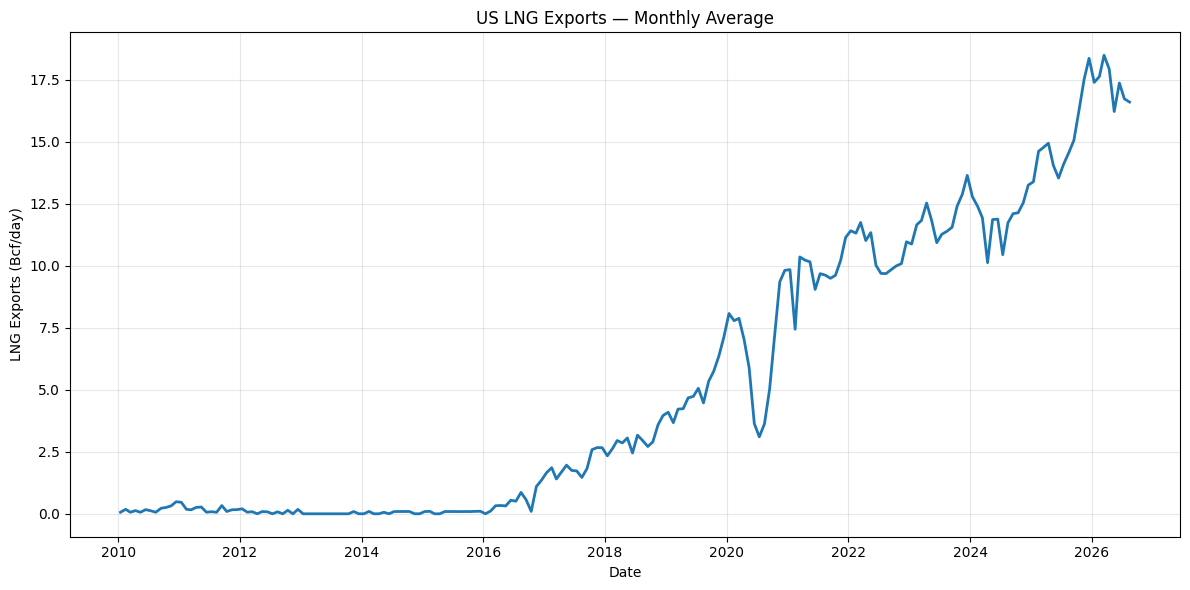


SUCCESS: US LNG export dataset created.
CSV: eia_us_lng_exports.csv
Rows: 200


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

# ============================================================
# PROJECT 3 — BATCH 8A
# US LNG EXPORTS — EIA MONTHLY DATA
# ============================================================

!pip -q install xlrd

import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from google.colab import files

# Official EIA historical Excel file
url = (
    "https://www.eia.gov/dnav/ng/hist_xls/"
    "N9133US2m.xls"
)

filename = "eia_us_lng_exports.csv"

# Download the original EIA spreadsheet
import requests

response = requests.get(url, timeout=60)
response.raise_for_status()

source_file = "eia_lng_source.xls"
Path(source_file).write_bytes(response.content)

# EIA historical spreadsheets typically contain
# a Data 1 worksheet with metadata rows.
book = pd.ExcelFile(source_file, engine="xlrd")

print("Available sheets:", book.sheet_names)

sheet = next(
    (s for s in book.sheet_names
     if s.lower().startswith("data")),
    None
)

if sheet is None:
    raise ValueError(
        "No EIA data worksheet found. "
        "Please send a screenshot."
    )

raw = pd.read_excel(
    source_file,
    sheet_name=sheet,
    header=None,
    engine="xlrd"
)

# Locate the column containing monthly dates.
# EIA commonly represents them as MMM YYYY.
best = None

for col in raw.columns:

    parsed = pd.to_datetime(
        raw[col],
        errors="coerce"
    )

    count = parsed.notna().sum()

    if best is None or count > best[0]:
        best = (count, col, parsed)

if best[0] < 24:
    raise ValueError(
        "Could not identify monthly dates. "
        "Please send a screenshot of the worksheet."
    )

date_col = best[1]
dates = best[2]

# Identify the numeric series column with the
# greatest number of observations aligned to dates.
candidates = []

for col in raw.columns:

    if col == date_col:
        continue

    values = pd.to_numeric(
        raw[col], errors="coerce"
    )

    valid = dates.notna() & values.notna()

    candidates.append((
        int(valid.sum()),
        col,
        values
    ))

candidates.sort(
    key=lambda x: x[0],
    reverse=True
)

if not candidates or candidates[0][0] < 24:
    raise ValueError(
        "Could not identify LNG export values."
    )

values = candidates[0][2]

lng = pd.DataFrame({
    "Date": dates,
    "LNG_Exports_Million_Cubic_Feet": values
}).dropna()

lng = lng[
    (lng["Date"] >= "2010-01-01")
    & (lng["Date"] <= pd.Timestamp.today())
]

lng = (
    lng.drop_duplicates("Date")
    .sort_values("Date")
    .reset_index(drop=True)
)

# Monthly million cubic feet / 1000 = Bcf
lng["LNG_Exports_Bcf"] = (
    lng["LNG_Exports_Million_Cubic_Feet"]
    / 1000
)

lng["Days_In_Month"] = (
    lng["Date"].dt.days_in_month
)

lng["LNG_Exports_Bcf_Per_Day"] = (
    lng["LNG_Exports_Bcf"]
    / lng["Days_In_Month"]
)

lng["Year"] = lng["Date"].dt.year

if len(lng) < 60:
    raise ValueError(
        "Unexpectedly short LNG series. "
        "Please send the output."
    )

print()
print("US LNG EXPORT DATA")
print("Observations:", len(lng))
print("First:", lng["Date"].min().date())
print("Latest:", lng["Date"].max().date())

print()
print(lng.tail(6).to_string(index=False))

# Plot monthly LNG export volumes
plt.figure(figsize=(12, 6))

plt.plot(
    lng["Date"],
    lng["LNG_Exports_Bcf_Per_Day"],
    linewidth=2
)

plt.title("US LNG Exports — Monthly Average")
plt.xlabel("Date")
plt.ylabel("LNG Exports (Bcf/day)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Save the dataset
lng.to_csv(filename, index=False)

print()
print("SUCCESS: US LNG export dataset created.")
print("CSV:", filename)
print("Rows:", len(lng))

# Download ONE file only
files.download(filename)


In [ ]:

# ============================================================
# PROJECT 3 — BATCH 8C
# AUTOMATIC UK GAS DATA COLLECTION
# NO API KEY / NO MANUAL DATA DOWNLOADS
# ============================================================

import requests
import pandas as pd
import io
from pathlib import Path
from google.colab import files

# Official National Gas documented CSV endpoint
URL = (
    "https://data.nationalgas.com/"
    "api/find-gas-data-download"
)

# These publication IDs appear in National Gas's
# official technical documentation.
# Their precise market meanings are NOT assumed.
PUBLICATION_IDS = ["PUBOB39", "PUBOB42"]

# Request a recent historical sample first.
# The provider may limit its accessible history.
END_DATE = pd.Timestamp.today().normalize()
START_DATE = END_DATE - pd.Timedelta(days=90)

params = {
    "applicableFor": "Y",
    "dateFrom": START_DATE.strftime(
        "%Y-%m-%dT00:00:00"
    ),
    "dateTo": END_DATE.strftime(
        "%Y-%m-%dT23:59:59"
    ),
    "dateType": "GASDAY",
    "latestFlag": "Y",
    "ids": ",".join(PUBLICATION_IDS),
    "type": "CSV"
}

print("Connecting to National Gas Transmission...")
print("Date range:", START_DATE.date(),
      "to", END_DATE.date())

try:
    response = requests.get(
        URL,
        params=params,
        timeout=60,
        headers={
            "User-Agent": "Mozilla/5.0",
            "Accept": "text/csv,*/*"
        }
    )

    response.raise_for_status()

    content = response.text.strip()

    if not content:
        raise ValueError(
            "National Gas returned an empty response."
        )

    if content.lstrip().startswith(
        ("<!DOCTYPE", "<html", "{")
    ):
        raise ValueError(
            "The endpoint returned a webpage or "
            "API message rather than CSV data."
        )

    # Read the CSV without guessing its schema.
    df = pd.read_csv(
        io.StringIO(content),
        sep=None,
        engine="python",
        on_bad_lines="warn"
    )

    if df.empty:
        raise ValueError(
            "The CSV contained no observations."
        )

    if len(df.columns) < 2:
        raise ValueError(
            "The response does not look like "
            "a usable data table."
        )

    print()
    print("SUCCESS: National Gas response received.")
    print("Rows:", len(df))
    print("Columns:", list(df.columns))

    print()
    print("First observations:")
    print(df.head(5).to_string(index=False))

    # Preserve all original values, column names,
    # and units supplied by National Gas.
    filename = "uk_gas_operational_data.csv"

    df.to_csv(filename, index=False)

    print()
    print("CSV CREATED:", filename)
    print("Downloading one file...")

    files.download(filename)

except Exception as error:

    print()
    print("UK DATA DOWNLOAD NOT COMPLETED")
    print("Reason:", str(error))

    print()
    print(
        "The National Gas endpoint may have "
        "changed or these publication IDs "
        "may no longer return data."
    )

    print(
        "No CSV was created because we will "
        "not substitute invented observations."
    )


Connecting to National Gas Transmission...
Date range: 2026-08-10 to 2026-11-08

SUCCESS: National Gas response received.
Rows: 182
Columns: ['Applicable At', 'Applicable For', 'Data Item', 'Value', 'Generated Time', 'Quality Indicator']

First observations:
      Applicable At Applicable For                 Data Item  Value      Generated Time  Quality Indicator
05/11/2026 14:22:11     08/11/2026 Demand Forecast, NTS, D-3  252.0 05/11/2026 14:26:22                NaN
04/11/2026 12:00:00     07/11/2026 Demand Forecast, NTS, D-3  242.0 04/11/2026 13:05:02                NaN
04/11/2026 12:00:00     08/11/2026 Demand Forecast, NTS, D-4  247.0 04/11/2026 13:05:02                NaN
03/11/2026 12:00:00     06/11/2026 Demand Forecast, NTS, D-3  251.0 03/11/2026 13:05:02                NaN
03/11/2026 12:00:00     07/11/2026 Demand Forecast, NTS, D-4  240.0 03/11/2026 13:05:02                NaN

CSV CREATED: uk_gas_operational_data.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

STEP 1: Checking official National Gas catalogue
Catalogue entries: 13123

LNG CANDIDATES FOUND:
PUBOBJ629 | System Entry Volume, Aggregate Physical Volume, LNG Importation, D+1 | score 175
PUBOBJ1277 | System Entry Volume, Aggregate Physical Volume, LNG Importation, M+15 | score 175
PUBOBJ633 | System Entry Energy, Aggregate Physical Energy, LNG Importation, D+1  | score 155
PUBOBJ1281 | System Entry Energy, Aggregate Physical Energy, LNG Importation, M+15 | score 155
PUBOBJ2412 | Inflow, Dragon, LNG Importation | score 130
PUBOBJ2403 | Inflow, Isle Of Grain, LNG Importation | score 130
PUBOBJ2411 | Inflow, South Hook, LNG Importation | score 130
PUBOBJ2424 | Outflow, Dragon, LNG Importation | score 130
PUBOBJ2415 | Outflow, Isle Of Grain, LNG Importation | score 130
PUBOBJ2423 | Outflow, South Hook, LNG Importation | score 130

Downloading: NTS Actual Demand
Rows: 119
Range: 92.41 to 257.07

Downloading: Closing Linepack
Rows: 119
Range: 324.57 to 359.67

STEP 5: Testing LNG candidat

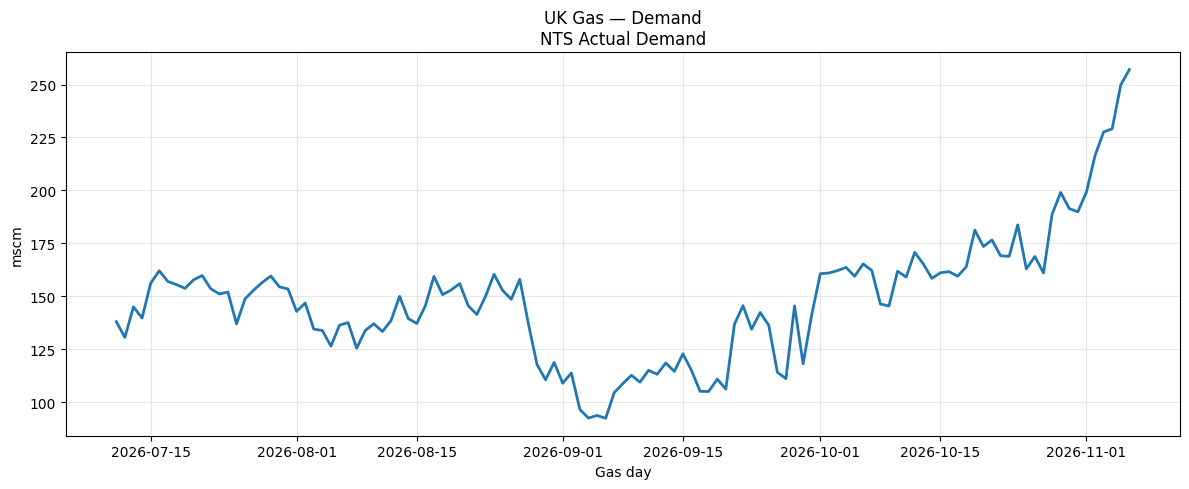

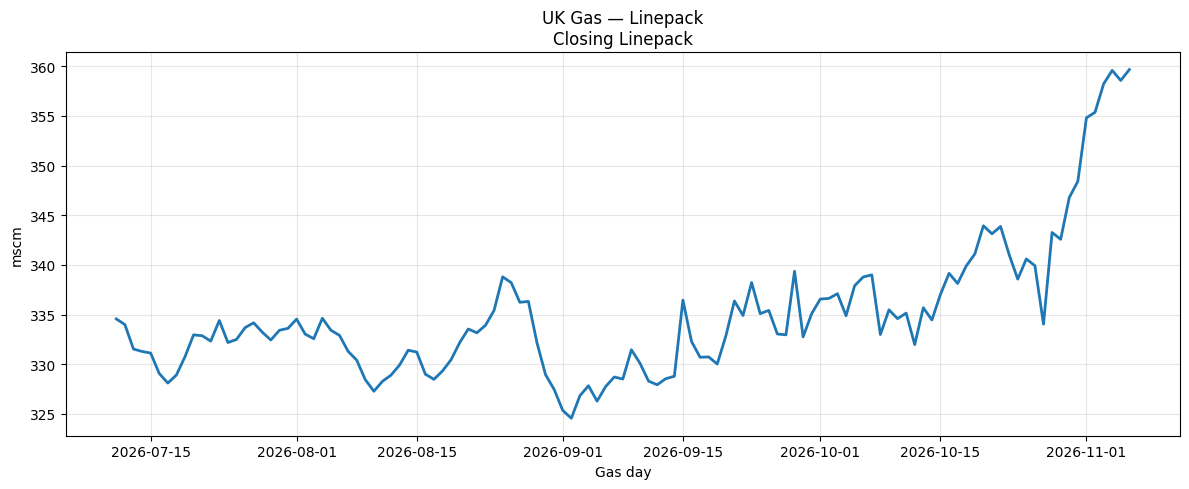

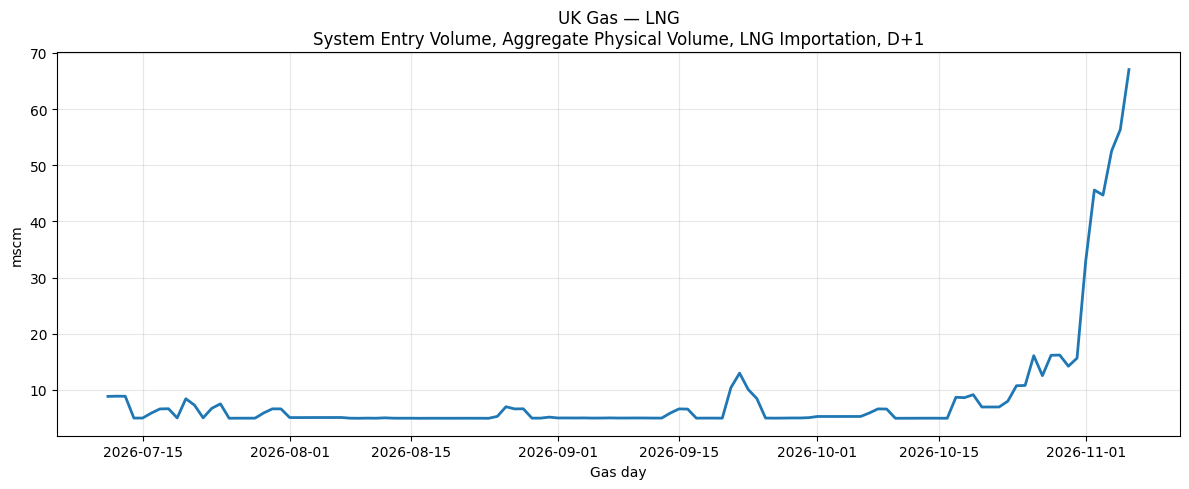


UK GAS — THREE-SERIES DATA SUMMARY
                                                                                    count        min         max  nunique
Category Series                                                               Unit                                       
Demand   NTS Actual Demand                                                    mscm    119   92.41310  257.067000      119
LNG      System Entry Volume, Aggregate Physical Volume, LNG Importation, D+1 mscm    119    4.95736   67.044820      119
Linepack Closing Linepack                                                     mscm    119  324.56805  359.669574      119

SUCCESS: Three UK gas datasets collected.
CSV: uk_gas_three_series_validated.csv
Total rows: 357
Charts created: 3


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

# ============================================================
# PROJECT 3 — BATCH 8D FINAL REBUILD
# UK DEMAND + LINEPACK + LNG
# OFFICIAL NATIONAL GAS DATA
# NO API KEY / ONE CSV DOWNLOAD
# ============================================================

import requests
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files

BASE = (
    "https://api.nationalgas.com/"
    "operationaldata/v1/publications"
)

session = requests.Session()
session.headers.update({
    "Accept": "application/json",
    "Content-Type": "application/json"
})

END = pd.Timestamp.today().normalize()
START = END - pd.Timedelta(days=120)

# Confirmed daily publication identifiers
KNOWN = {
    "Demand": {
        "id": "PUBOB637",
        "name": "NTS Actual Demand",
        "unit": "mscm"
    },
    "Linepack": {
        "id": "PUBOB694",
        "name": "Closing Linepack",
        "unit": "mscm"
    }
}

# ------------------------------------------------------------
# 1. DOWNLOAD OFFICIAL CATALOGUE
# ------------------------------------------------------------

print("STEP 1: Checking official National Gas catalogue")

response = session.get(
    BASE + "/catalogue",
    timeout=60
)
response.raise_for_status()

catalogue = response.json()

def extract_catalogue(obj):
    found = []

    if isinstance(obj, dict):
        if "publicationId" in obj:
            found.append(obj)

        for value in obj.values():
            if isinstance(value, (dict, list)):
                found.extend(extract_catalogue(value))

    elif isinstance(obj, list):
        for value in obj:
            found.extend(extract_catalogue(value))

    return found

entries = extract_catalogue(catalogue)

by_id = {}

for entry in entries:
    pub_id = entry.get("publicationId")

    if pub_id:
        by_id[str(pub_id)] = entry

print("Catalogue entries:", len(by_id))

# ------------------------------------------------------------
# 2. IDENTIFY A SUITABLE LNG SERIES
# ------------------------------------------------------------

# Exclude forecasts, allocations, capacities,
# stocks and nominations.
#
# The aim is to find actual LNG import/sendout
# volume, not a different LNG market indicator.

exclude_terms = [
    "allocation",
    "forecast",
    "capacity",
    "nomination",
    "stock",
    "inventory",
    "storage",
    "maintenance",
    "price",
    "quality"
]

lng_candidates = []

for pub_id, entry in by_id.items():

    name = str(
        entry.get("name", "")
        or entry.get("publicationName", "")
    )

    description = str(
        entry.get("description", "")
    )

    text = (name + " " + description).lower()

    if "lng" not in text and (
        "liquefied natural gas" not in text
    ):
        continue

    if any(term in text for term in exclude_terms):
        continue

    score = 0

    for term, points in [
        ("sendout", 80),
        ("send out", 80),
        ("flow", 60),
        ("importation", 40),
        ("import", 30),
        ("actual", 25),
        ("volume", 20),
        ("total", 10)
    ]:
        if term in text:
            score += points

    if score > 0:
        lng_candidates.append({
            "id": pub_id,
            "name": name,
            "description": description,
            "score": score,
            "metadata": entry
        })

lng_candidates.sort(
    key=lambda x: x["score"],
    reverse=True
)

print()
print("LNG CANDIDATES FOUND:")

for item in lng_candidates[:10]:
    print(
        item["id"],
        "|",
        item["name"],
        "| score",
        item["score"]
    )

# ------------------------------------------------------------
# 3. DOWNLOAD HISTORICAL GAS-DAY OBSERVATIONS
# ------------------------------------------------------------

def download_gasday(pub_id):

    records = []

    current = START

    while current <= END:

        finish = min(
            current + pd.Timedelta(days=29),
            END
        )

        body = {
            "fromDate": current.strftime("%Y-%m-%d"),
            "toDate": finish.strftime("%Y-%m-%d"),
            "publicationIds": [pub_id],
            "latestValue": "Y"
        }

        response = session.post(
            BASE + "/gasday",
            json=body,
            timeout=60
        )

        response.raise_for_status()
        payload = response.json()

        if isinstance(payload, dict):
            payload = payload.get(
                "data", [payload]
            )

        if not isinstance(payload, list):
            raise ValueError(
                "Unexpected National Gas response."
            )

        for group in payload:

            if not isinstance(group, dict):
                continue

            observations = group.get(
                "publications", []
            )

            for obs in observations:

                if not isinstance(obs, dict):
                    continue

                records.append({
                    "Date": obs.get("applicableFor"),
                    "Value": obs.get("value"),
                    "Generated": obs.get(
                        "generatedTimeStamp"
                    ),
                    "Publication_ID": pub_id,
                    "Source_Name": group.get(
                        "publicationName", ""
                    )
                })

        current = finish + pd.Timedelta(days=1)

    if not records:
        return pd.DataFrame()

    df = pd.DataFrame(records)

    df["Date"] = pd.to_datetime(
        df["Date"],
        errors="coerce",
        utc=True
    ).dt.tz_localize(None).dt.normalize()

    df["Generated"] = pd.to_datetime(
        df["Generated"],
        errors="coerce",
        utc=True
    )

    df["Value"] = pd.to_numeric(
        df["Value"],
        errors="coerce"
    )

    df = df.dropna(
        subset=["Date", "Value"]
    )

    # Keep the latest published revision
    # of each gas-day observation.
    df = (
        df.sort_values("Generated")
        .drop_duplicates("Date", keep="last")
        .sort_values("Date")
        .reset_index(drop=True)
    )

    return df

# ------------------------------------------------------------
# 4. DOWNLOAD VERIFIED DEMAND AND LINEPACK
# ------------------------------------------------------------

datasets = []

for category, details in KNOWN.items():

    print()
    print("Downloading:", details["name"])

    df = download_gasday(details["id"])

    if len(df) < 30:
        raise ValueError(
            f"Insufficient {category} observations."
        )

    if df["Value"].nunique() < 10:
        raise ValueError(
            f"{category} data is unexpectedly flat."
        )

    if (df["Value"] < 0).any():
        raise ValueError(
            f"Negative {category} observations found."
        )

    df["Category"] = category
    df["Series"] = details["name"]
    df["Unit"] = details["unit"]
    df["Validation_Status"] = (
        "Passed basic numerical checks"
    )

    datasets.append(df)

    print("Rows:", len(df))
    print(
        "Range:",
        round(df["Value"].min(), 2),
        "to",
        round(df["Value"].max(), 2)
    )

# ------------------------------------------------------------
# 5. TEST LNG CANDIDATES
# ------------------------------------------------------------

print()
print("STEP 5: Testing LNG candidates...")

lng_selected = None
lng_data = None

for candidate in lng_candidates[:20]:

    print(
        "Testing:",
        candidate["id"],
        candidate["name"]
    )

    try:
        df = download_gasday(candidate["id"])

        if len(df) < 30:
            print("  Skipped: insufficient history")
            continue

        if df["Value"].nunique() < 10:
            print("  Skipped: nearly constant")
            continue

        if (df["Value"] < 0).any():
            print("  Skipped: negative values")
            continue

        # Avoid series with a very large isolated
        # scale jump, like our previous LNG chart.
        positive = df.loc[
            df["Value"] > 0, "Value"
        ]

        if len(positive) < 20:
            print("  Skipped: insufficient positive data")
            continue

        median = positive.median()

        if median <= 0:
            continue

        ratio = positive.max() / median

        if ratio > 15:
            print(
                "  Skipped: extreme scale ratio",
                round(ratio, 2)
            )
            continue

        # Confirm the source explicitly identifies
        # a flow/import/sendout measure.
        name = candidate["name"].lower()

        if not any(
            word in name
            for word in [
                "sendout",
                "send out",
                "flow",
                "import"
            ]
        ):
            print("  Skipped: ambiguous publication")
            continue

        # A numeric sanity check does NOT verify
        # physical units. Preserve them as unknown
        # unless catalogue metadata identifies them.
        metadata = candidate["metadata"]

        unit = (
            metadata.get("unit")
            or metadata.get("units")
            or metadata.get("unitOfMeasure")
        )

        if not isinstance(unit, str) or not unit.strip():
            print(
                "  Skipped: physical unit not "
                "confirmed by catalogue"
            )
            continue

        lng_selected = candidate
        lng_data = df
        lng_unit = unit.strip()

        print("  Candidate passed initial checks.")
        break

    except Exception as error:
        print(
            "  Candidate failed:",
            str(error)[:100]
        )

# ------------------------------------------------------------
# 6. FINAL LNG VALIDATION
# ------------------------------------------------------------

if lng_data is None:

    print()
    print("=" * 60)
    print("LNG VALIDATION INCOMPLETE")
    print("=" * 60)
    print(
        "Demand and linepack downloaded correctly."
    )
    print(
        "No LNG candidate met all requirements "
        "for source identification, units and "
        "numerical quality."
    )
    print(
        "No misleading LNG graph or CSV "
        "will be created."
    )
    print()
    print(
        "Send me the LNG CANDIDATES FOUND "
        "and Testing output so we can select "
        "the correct official publication."
    )

    raise ValueError(
        "LNG source validation required."
    )

lng_data["Category"] = "LNG"

lng_data["Series"] = lng_selected["name"]

lng_data["Unit"] = lng_unit

lng_data["Validation_Status"] = (
    "Passed preliminary catalogue and "
    "numerical checks; definition review required"
)

datasets.append(lng_data)

# ------------------------------------------------------------
# 7. BUILD ALL THREE CHARTS
# ------------------------------------------------------------

combined = pd.concat(
    datasets,
    ignore_index=True
)

for category in ["Demand", "Linepack", "LNG"]:

    group = combined[
        combined["Category"] == category
    ].sort_values("Date")

    if group.empty:
        raise ValueError(
            f"Missing {category} chart data."
        )

    name = group["Series"].iloc[0]
    unit = group["Unit"].iloc[0]

    plt.figure(figsize=(12, 5))

    plt.plot(
        group["Date"],
        group["Value"],
        linewidth=2
    )

    plt.title(
        f"UK Gas — {category}\n{name}"
    )

    plt.xlabel("Gas day")
    plt.ylabel(unit)
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

# ------------------------------------------------------------
# 8. SUMMARY AND ONE CSV DOWNLOAD
# ------------------------------------------------------------

print()
print("=" * 65)
print("UK GAS — THREE-SERIES DATA SUMMARY")
print("=" * 65)

summary = (
    combined.groupby(
        ["Category", "Series", "Unit"]
    )["Value"]
    .agg(
        ["count", "min", "max", "nunique"]
    )
)

print(summary.to_string())

filename = "uk_gas_three_series_validated.csv"

combined.to_csv(
    filename,
    index=False
)

print()
print("SUCCESS: Three UK gas datasets collected.")
print("CSV:", filename)
print("Total rows:", len(combined))
print("Charts created: 3")

files.download(filename)



PART 1 — EUROPEAN GAS PRICES


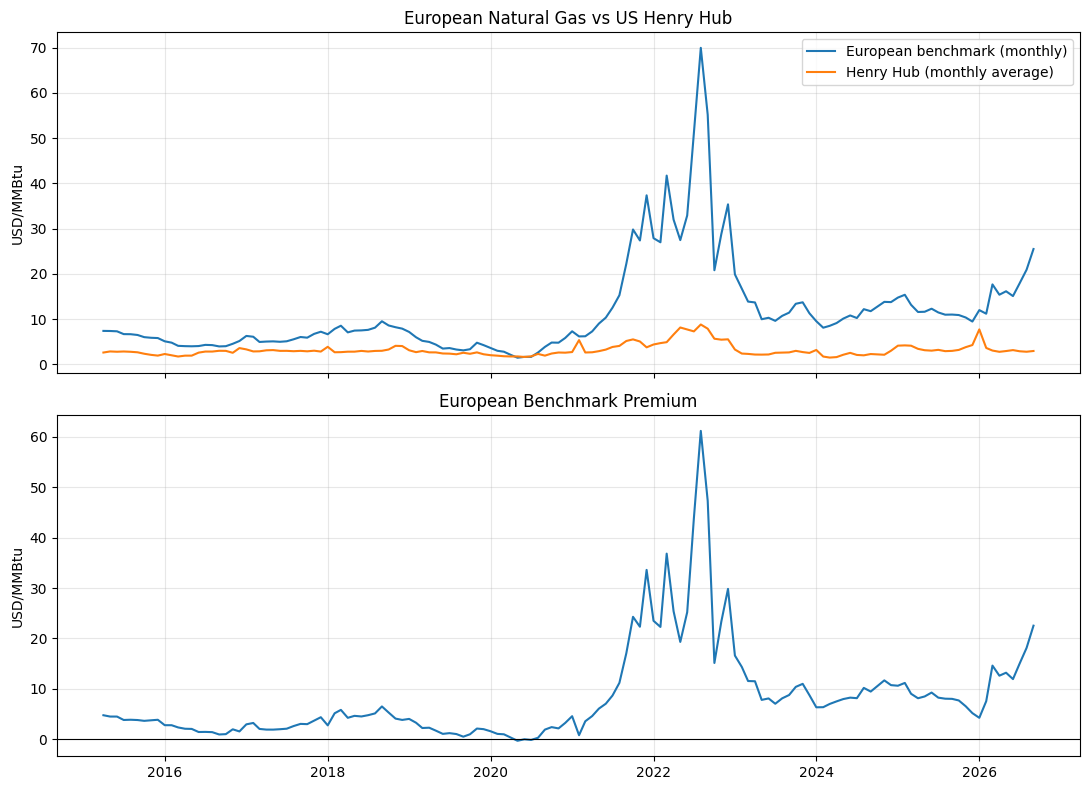

European price observations: 138
Latest price month: 2026-09-01

PART 2 — UK SUPPLY AND DEMAND


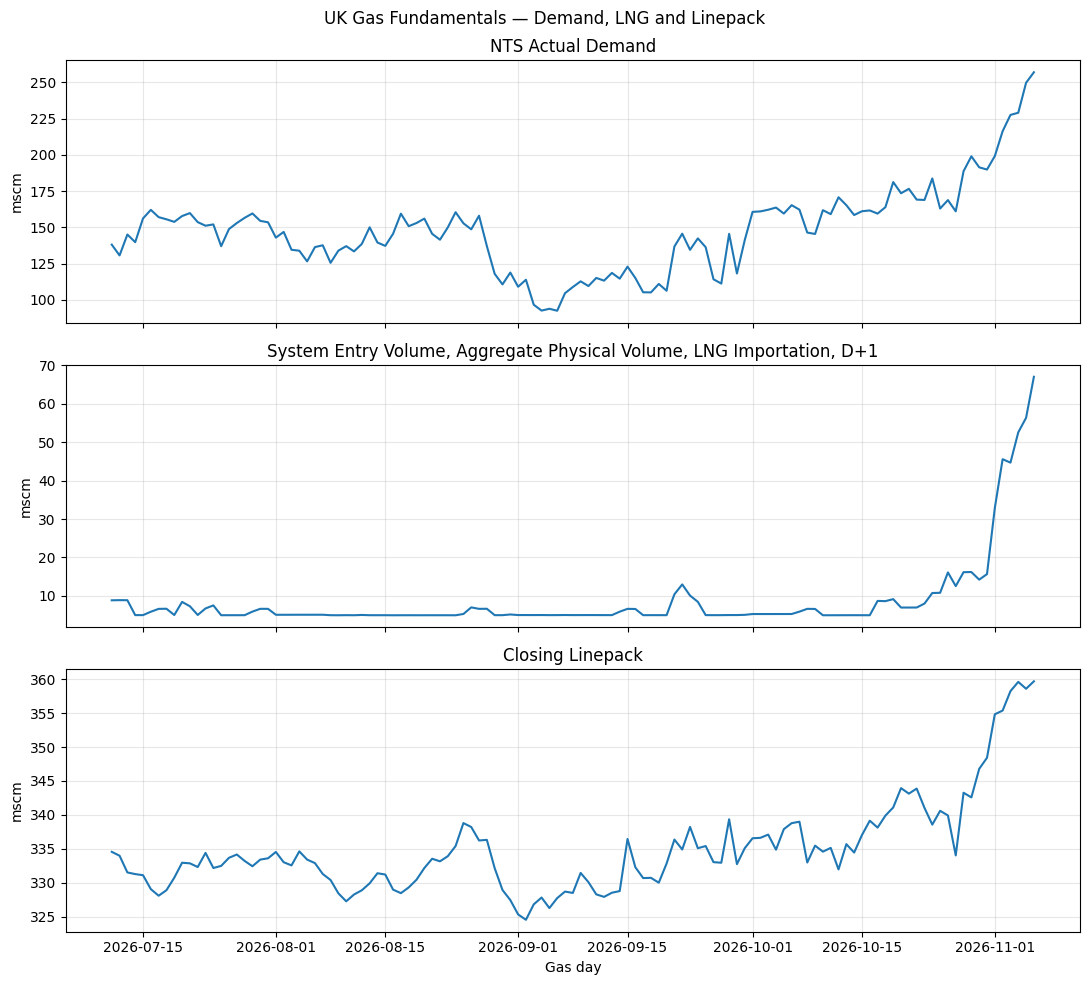

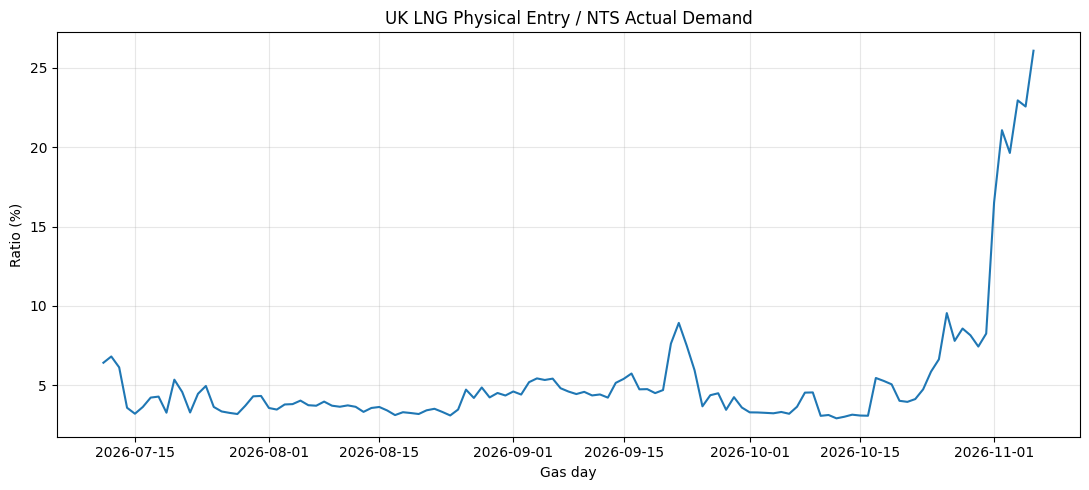


PART 3 — STORAGE FORECAST SCENARIOS


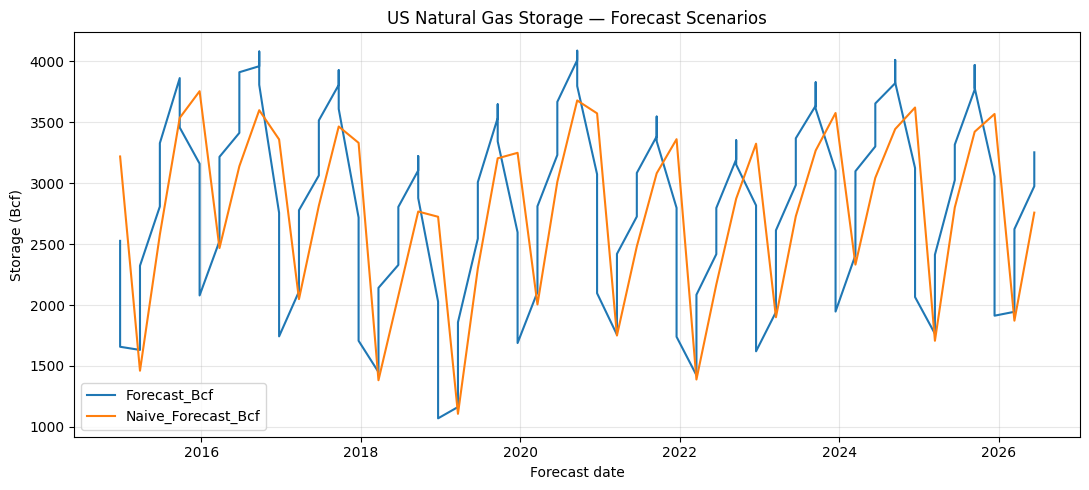

Forecast file detected: natural_gas_forecast_backtest.csv

PART 4 — MARKET INTELLIGENCE
NATURAL GAS MARKET INTELLIGENCE

EUROPEAN PRICE BENCHMARK
Observation: 2026-09-01
European gas: 25.49 USD/MMBtu
Henry Hub: 2.95 USD/MMBtu
European premium: 22.54 USD/MMBtu

UK GAS FUNDAMENTALS
Latest available UK date: 2026-11-06
Demand: 257.07 mscm | 2026-11-06
LNG: 67.04 mscm | 2026-11-06
Linepack: 359.67 mscm | 2026-11-06

ANALYST INTERPRETATION
- European benchmark exceeds Henry Hub.
- This may support interest in US LNG exports, but shipping, liquefaction, regasification and contract costs matter.
- LNG physical entry has increased relative to NTS demand over the latest two seven-day windows.

KEY RISKS TO MONITOR
- Colder weather and higher gas demand.
- LNG terminal availability and changes in physical entry volumes.
- UK linepack changes and short-term system balancing conditions.
- US storage deviations from seasonal norms.
- European price changes and global LNG supply competition.

DATA L

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

# ============================================================
# PROJECT 3 — BATCH 9
# PROFESSIONAL GAS MARKET ANALYST ENHANCEMENTS
#
# 1. European prices vs Henry Hub
# 2. UK LNG, demand and linepack
# 3. Storage forecast scenarios
# 4. Market intelligence and risk summary
#
# NO API KEY
# ONE CSV DOWNLOAD
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import requests
import io
from pathlib import Path
from google.colab import files

plt.rcParams["figure.figsize"] = (11, 5)

OUTPUT = "natural_gas_market_intelligence.csv"
results = []

def add_indicator(date, category, indicator, value,
                  unit, source, note=""):
    if pd.notna(value):
        results.append({
            "Date": pd.Timestamp(date).strftime("%Y-%m-%d"),
            "Category": category,
            "Indicator": indicator,
            "Value": float(value),
            "Unit": unit,
            "Source": source,
            "Note": note
        })

def read_csv(name):
    path = Path(name)
    if not path.exists():
        raise FileNotFoundError(
            f"Missing {name}. Run its earlier Colab batch "
            "before running Batch 9."
        )
    return pd.read_csv(path)

# ============================================================
# PART 1 — EUROPEAN GAS PRICE ANALYSIS
# ============================================================

print("\nPART 1 — EUROPEAN GAS PRICES")

fred_url = (
    "https://fred.stlouisfed.org/graph/"
    "fredgraph.csv?id=PNGASEUUSDM"
)

response = requests.get(fred_url, timeout=60)
response.raise_for_status()

eu = pd.read_csv(io.StringIO(response.text))

eu.columns = [str(c).strip() for c in eu.columns]

if "observation_date" in eu.columns:
    eu = eu.rename(columns={
        "observation_date": "Date"
    })

if "DATE" in eu.columns:
    eu = eu.rename(columns={"DATE": "Date"})

if "PNGASEUUSDM" not in eu.columns:
    raise ValueError(
        "European benchmark column not found."
    )

eu["Date"] = pd.to_datetime(
    eu["Date"], errors="coerce"
)

eu["Europe_USD_MMBtu"] = pd.to_numeric(
    eu["PNGASEUUSDM"], errors="coerce"
)

eu = eu.dropna(
    subset=["Date", "Europe_USD_MMBtu"]
)

eu = eu[eu["Date"] >= "2015-04-01"].copy()

hh = read_csv("henry_hub_prices.csv")

hh["Date"] = pd.to_datetime(
    hh["Date"], errors="coerce"
)

hh["Henry_Hub_USD_MMBtu"] = pd.to_numeric(
    hh["Henry_Hub_USD_MMBtu"],
    errors="coerce"
)

hh = hh.dropna(
    subset=["Date", "Henry_Hub_USD_MMBtu"]
)

hh_monthly = (
    hh.set_index("Date")["Henry_Hub_USD_MMBtu"]
    .resample("MS")
    .mean()
    .reset_index()
)

prices = eu[
    ["Date", "Europe_USD_MMBtu"]
].merge(
    hh_monthly,
    on="Date",
    how="inner"
).sort_values("Date")

prices["Europe_HH_Premium_USD_MMBtu"] = (
    prices["Europe_USD_MMBtu"]
    - prices["Henry_Hub_USD_MMBtu"]
)

if prices.empty:
    raise ValueError(
        "No overlapping European and US price dates."
    )

fig, axes = plt.subplots(
    2, 1, figsize=(11, 8), sharex=True
)

axes[0].plot(
    prices["Date"],
    prices["Europe_USD_MMBtu"],
    label="European benchmark (monthly)"
)

axes[0].plot(
    prices["Date"],
    prices["Henry_Hub_USD_MMBtu"],
    label="Henry Hub (monthly average)"
)

axes[0].set_title(
    "European Natural Gas vs US Henry Hub"
)
axes[0].set_ylabel("USD/MMBtu")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(
    prices["Date"],
    prices["Europe_HH_Premium_USD_MMBtu"]
)

axes[1].axhline(0, color="black", linewidth=0.8)
axes[1].set_title("European Benchmark Premium")
axes[1].set_ylabel("USD/MMBtu")
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

for row in prices.itertuples(index=False):
    add_indicator(
        row.Date, "European Prices",
        "European gas benchmark",
        row.Europe_USD_MMBtu, "USD/MMBtu",
        "IMF via FRED PNGASEUUSDM",
        "Monthly benchmark; not daily TTF futures"
    )
    add_indicator(
        row.Date, "European Prices",
        "Henry Hub monthly average",
        row.Henry_Hub_USD_MMBtu, "USD/MMBtu",
        "FRED DHHNGSP"
    )
    add_indicator(
        row.Date, "European Prices",
        "Europe minus Henry Hub premium",
        row.Europe_HH_Premium_USD_MMBtu,
        "USD/MMBtu",
        "Calculated from FRED data",
        "Not an executable LNG arbitrage margin"
    )

print("European price observations:", len(prices))
print("Latest price month:", prices["Date"].max().date())

# ============================================================
# PART 2 — UK GAS FUNDAMENTALS
# ============================================================

print("\nPART 2 — UK SUPPLY AND DEMAND")

uk = read_csv("uk_gas_three_series_validated.csv")

required = [
    "Date", "Value", "Category",
    "Series", "Unit"
]

missing = [c for c in required if c not in uk.columns]

if missing:
    raise ValueError(
        "UK CSV missing columns: " + str(missing)
    )

uk["Date"] = pd.to_datetime(
    uk["Date"], errors="coerce"
)

uk["Value"] = pd.to_numeric(
    uk["Value"], errors="coerce"
)

uk = uk.dropna(subset=["Date", "Value"])

uk["Category"] = uk["Category"].astype(str)

categories = ["Demand", "LNG", "Linepack"]

fig, axes = plt.subplots(
    3, 1, figsize=(11, 10), sharex=True
)

for ax, category in zip(axes, categories):

    part = uk[
        uk["Category"].str.lower()
        == category.lower()
    ].sort_values("Date")

    if part.empty:
        raise ValueError(
            f"Missing UK {category} series."
        )

    series_name = part["Series"].iloc[0]
    unit = part["Unit"].iloc[0]

    ax.plot(part["Date"], part["Value"])
    ax.set_title(series_name)
    ax.set_ylabel(unit)
    ax.grid(alpha=0.3)

    for row in part.itertuples(index=False):
        add_indicator(
            row.Date, "UK Fundamentals",
            row.Series, row.Value,
            row.Unit, "National Gas Transmission",
            "Physical or operational series; "
            "check publication timing"
        )

axes[-1].set_xlabel("Gas day")
plt.suptitle(
    "UK Gas Fundamentals — Demand, LNG and Linepack"
)
plt.tight_layout()
plt.show()

# Calculate LNG as a share of NTS demand.
# This is an indicator, NOT a complete UK gas balance.
demand = uk[
    uk["Category"].str.lower() == "demand"
][["Date", "Value"]].rename(
    columns={"Value": "Demand"}
)

lng = uk[
    uk["Category"].str.lower() == "lng"
][["Date", "Value"]].rename(
    columns={"Value": "LNG"}
)

share = demand.merge(lng, on="Date")

# Check the reported units before calculating.
demand_unit = uk.loc[
    uk["Category"].str.lower() == "demand",
    "Unit"
].iloc[0]

lng_unit = uk.loc[
    uk["Category"].str.lower() == "lng",
    "Unit"
].iloc[0]

if (
    demand_unit.lower() == "mscm"
    and lng_unit.lower() == "mscm"
):

    share = share[share["Demand"] > 0].copy()

    share["LNG_to_Demand_Pct"] = (
        100 * share["LNG"] / share["Demand"]
    )

    plt.figure(figsize=(11, 5))
    plt.plot(
        share["Date"],
        share["LNG_to_Demand_Pct"]
    )
    plt.title(
        "UK LNG Physical Entry / NTS Actual Demand"
    )
    plt.ylabel("Ratio (%)")
    plt.xlabel("Gas day")
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

    for row in share.itertuples(index=False):
        add_indicator(
            row.Date, "UK Fundamentals",
            "LNG entry / NTS demand",
            row.LNG_to_Demand_Pct,
            "%",
            "Calculated from National Gas",
            "Indicative ratio only; not total "
            "UK LNG dependency or a closed balance"
        )

else:
    print(
        "LNG-to-demand ratio skipped: "
        "published units do not match."
    )

# ============================================================
# PART 3 — STORAGE FORECAST SCENARIOS
# ============================================================

print("\nPART 3 — STORAGE FORECAST SCENARIOS")

# Look for the Batch 6 storage forecast CSV.
# This avoids guessing its exact filename.
forecast_files = [
    p for p in Path(".").glob("*.csv")
    if "forecast" in p.name.lower()
    and "weather" not in p.name.lower()
]

forecast_data = None
forecast_source = None

for path in forecast_files:

    try:
        test = pd.read_csv(path)

        date_candidates = [
            c for c in test.columns
            if "date" in c.lower()
        ]

        numeric_candidates = [
            c for c in test.columns
            if any(
                word in c.lower()
                for word in [
                    "base", "higher", "lower",
                    "forecast", "scenario"
                ]
            )
        ]

        if (
            date_candidates
            and len(numeric_candidates) >= 2
        ):
            forecast_data = test.copy()
            forecast_source = path.name
            break

    except Exception:
        continue

if forecast_data is not None:

    date_col = next(
        c for c in forecast_data.columns
        if "date" in c.lower()
    )

    forecast_data[date_col] = pd.to_datetime(
        forecast_data[date_col],
        errors="coerce"
    )

    plot_cols = []

    for col in forecast_data.columns:

        if col == date_col:
            continue

        if any(
            word in col.lower()
            for word in [
                "base", "higher", "lower",
                "forecast", "scenario"
            ]
        ):
            forecast_data[col] = pd.to_numeric(
                forecast_data[col],
                errors="coerce"
            )

            if forecast_data[col].notna().sum() > 1:
                plot_cols.append(col)

    if plot_cols:

        plt.figure(figsize=(11, 5))

        for col in plot_cols[:6]:
            plt.plot(
                forecast_data[date_col],
                forecast_data[col],
                label=col
            )

            for _, row in forecast_data.iterrows():
                add_indicator(
                    row[date_col],
                    "Storage Scenarios",
                    col,
                    row[col],
                    "Bcf",
                    forecast_source,
                    "Model scenario, not an "
                    "official EIA forecast"
                )

        plt.title(
            "US Natural Gas Storage — Forecast Scenarios"
        )
        plt.ylabel("Storage (Bcf)")
        plt.xlabel("Forecast date")
        plt.legend()
        plt.grid(alpha=0.3)
        plt.tight_layout()
        plt.show()

        print(
            "Forecast file detected:",
            forecast_source
        )

else:
    print(
        "Forecast CSV not detected automatically."
    )
    print(
        "Your Batch 6 forecast is NOT deleted. "
        "Its existing charts and files remain intact."
    )
    print(
        "We will link its exact columns "
        "when building Streamlit."
    )

# ============================================================
# PART 4 — MARKET INTELLIGENCE SUMMARY
# ============================================================

print("\nPART 4 — MARKET INTELLIGENCE")

latest_prices = prices.iloc[-1]

recent_uk = uk.sort_values("Date")

latest_uk_date = recent_uk["Date"].max()

print("=" * 62)
print("NATURAL GAS MARKET INTELLIGENCE")
print("=" * 62)

print()
print("EUROPEAN PRICE BENCHMARK")
print(
    "Observation:",
    latest_prices["Date"].date()
)
print(
    "European gas:",
    round(latest_prices["Europe_USD_MMBtu"], 2),
    "USD/MMBtu"
)
print(
    "Henry Hub:",
    round(latest_prices["Henry_Hub_USD_MMBtu"], 2),
    "USD/MMBtu"
)
print(
    "European premium:",
    round(
        latest_prices[
            "Europe_HH_Premium_USD_MMBtu"
        ], 2
    ),
    "USD/MMBtu"
)

print()
print("UK GAS FUNDAMENTALS")
print("Latest available UK date:", latest_uk_date.date())

for category in categories:

    part = recent_uk[
        recent_uk["Category"].str.lower()
        == category.lower()
    ].sort_values("Date")

    if not part.empty:
        row = part.iloc[-1]

        print(
            category + ":",
            round(row["Value"], 2),
            row["Unit"],
            "|",
            row["Date"].date()
        )

print()
print("ANALYST INTERPRETATION")

premium = latest_prices[
    "Europe_HH_Premium_USD_MMBtu"
]

if premium > 0:
    print(
        "- European benchmark exceeds Henry Hub."
    )
    print(
        "- This may support interest in US LNG "
        "exports, but shipping, liquefaction, "
        "regasification and contract costs matter."
    )
else:
    print(
        "- European benchmark does not exceed "
        "Henry Hub in this monthly comparison."
    )

if len(share) >= 14 and (
    demand_unit.lower() == "mscm"
    and lng_unit.lower() == "mscm"
):

    recent_share = share.tail(7)[
        "LNG_to_Demand_Pct"
    ].mean()

    earlier_share = share.iloc[-14:-7][
        "LNG_to_Demand_Pct"
    ].mean()

    if recent_share > earlier_share:
        print(
            "- LNG physical entry has increased "
            "relative to NTS demand over the "
            "latest two seven-day windows."
        )
    else:
        print(
            "- LNG physical entry has not "
            "increased relative to NTS demand "
            "over the latest two seven-day windows."
        )

print()
print("KEY RISKS TO MONITOR")
print(
    "- Colder weather and higher gas demand."
)
print(
    "- LNG terminal availability and changes "
    "in physical entry volumes."
)
print(
    "- UK linepack changes and short-term "
    "system balancing conditions."
)
print(
    "- US storage deviations from seasonal norms."
)
print(
    "- European price changes and global "
    "LNG supply competition."
)

print()
print("DATA LIMITATIONS")
print(
    "- European prices are MONTHLY, "
    "not live NBP/TTF futures quotes."
)
print(
    "- UK LNG is physical system entry, "
    "not total LNG cargo arrivals."
)
print(
    "- UK LNG / demand is a partial ratio, "
    "not a complete supply-demand balance."
)
print(
    "- Forecast scenarios are conditional "
    "models, not trading recommendations."
)

# ============================================================
# SAVE ONE CSV
# ============================================================

out = pd.DataFrame(results)

if out.empty:
    raise ValueError(
        "No market intelligence data was generated."
    )

out = out.sort_values(
    ["Category", "Indicator", "Date"]
).reset_index(drop=True)

out.to_csv(OUTPUT, index=False)

print()
print("=" * 62)
print("SUCCESS: BATCH 9 COMPLETED")
print("=" * 62)
print("File:", OUTPUT)
print("Rows:", len(out))
print("Categories:", out["Category"].nunique())
print("Indicators:", out["Indicator"].nunique())

files.download(OUTPUT)


In [ ]:

# ============================================================
# PROJECT 3 — BATCH 10
# PREPARE NATURAL GAS DASHBOARD DATA
#
# - Find all completed project CSVs
# - Check dates, columns and missing values
# - Preserve original datasets
# - Flag missing files and suspicious observations
# - Create ONE ZIP download for GitHub
#
# No API key required
# ============================================================

import pandas as pd
import numpy as np
import json
import zipfile
from pathlib import Path
from google.colab import files

print("=" * 65)
print("NATURAL GAS DASHBOARD — DATA PREPARATION")
print("=" * 65)

# ------------------------------------------------------------
# 1. EXPECTED DATASETS
# ------------------------------------------------------------

# Required: core project datasets
required_files = [
    "henry_hub_prices.csv",
    "eia_natural_gas_storage.csv",
    "eia_gas_storage_seasonality.csv",
    "natural_gas_weather_analysis.csv",
    "natural_gas_combined_market_data.csv",
    "uk_gas_three_series_validated.csv",
    "natural_gas_market_intelligence.csv"
]

# Optional: additional analysis and forecasting
optional_files = [
    "eia_us_lng_exports.csv",
    "natural_gas_weather_forecast.csv",
    "natural_gas_weather_backtest.csv",
    "natural_gas_model_comparison.csv"
]

# Also discover additional forecast/backtest CSVs
# created by earlier Colab batches.
extra_patterns = [
    "*storage*forecast*.csv",
    "*storage*backtest*.csv",
    "*gas*forecast*.csv",
    "*gas*backtest*.csv"
]

# Avoid including older, superseded UK datasets
superseded_files = {
    "uk_gas_operational_data.csv",
    "uk_gas_fundamentals.csv",
    "uk_gas_fundamentals_checked.csv",
    "uk_gas_demand_linepack_corrected.csv"
}

selected = []
missing_required = []
missing_optional = []

for name in required_files:
    if Path(name).is_file():
        selected.append(name)
    else:
        missing_required.append(name)

for name in optional_files:
    if Path(name).is_file():
        selected.append(name)
    else:
        missing_optional.append(name)

for pattern in extra_patterns:
    for path in Path(".").glob(pattern):
        if (
            path.is_file()
            and path.suffix.lower() == ".csv"
            and path.name not in superseded_files
            and path.name not in selected
        ):
            selected.append(path.name)

selected = sorted(set(selected))

print()
print("FILES FOUND:", len(selected))

for name in selected:
    print("  FOUND:", name)

if missing_required:
    print()
    print("REQUIRED FILES NOT FOUND:")
    for name in missing_required:
        print("  MISSING:", name)

if missing_optional:
    print()
    print("OPTIONAL FILES NOT FOUND:")
    for name in missing_optional:
        print("  OPTIONAL:", name)

if not selected:
    raise ValueError(
        "No project CSVs found in this Colab session. "
        "Run the earlier data collection cells first."
    )

# ------------------------------------------------------------
# 2. CHECK EACH CSV
# ------------------------------------------------------------

report_rows = []
valid_files = []

for name in selected:

    print()
    print("-" * 60)
    print("CHECKING:", name)

    try:
        df = pd.read_csv(name)

        if df.empty:
            raise ValueError("CSV has no rows")

        # Check for common date column names.
        date_candidates = [
            c for c in df.columns
            if str(c).strip().lower()
            in {
                "date",
                "forecast_date",
                "gas_day",
                "gasday",
                "observation_date"
            }
        ]

        first_date = None
        latest_date = None
        invalid_dates = None

        if date_candidates:

            date_col = date_candidates[0]

            dates = pd.to_datetime(
                df[date_col],
                errors="coerce",
                utc=True
            )

            invalid_dates = int(dates.isna().sum())

            if dates.notna().any():
                first_date = str(
                    dates.min().date()
                )
                latest_date = str(
                    dates.max().date()
                )

        missing_cells = int(
            df.isna().sum().sum()
        )

        numeric_cols = df.select_dtypes(
            include="number"
        ).columns.tolist()

        # Identify numeric columns with very
        # few distinct values. This is a warning,
        # not proof that the data is incorrect.
        flat_columns = []

        for col in numeric_cols:

            values = df[col].dropna()

            if (
                len(values) >= 20
                and values.nunique() <= 2
            ):
                flat_columns.append(col)

        duplicate_rows = int(
            df.duplicated().sum()
        )

        warnings = []

        if invalid_dates:
            warnings.append(
                f"{invalid_dates} invalid dates"
            )

        if flat_columns:
            warnings.append(
                "Low-variation columns: "
                + ", ".join(flat_columns)
            )

        if duplicate_rows:
            warnings.append(
                f"{duplicate_rows} duplicate rows"
            )

        if missing_cells:
            warnings.append(
                f"{missing_cells} missing cells"
            )

        # UK LNG remains subject to an
        # independent spike/source review.
        if name == "uk_gas_three_series_validated.csv":
            warnings.append(
                "UK LNG late-period spike "
                "requires source verification"
            )

        # A monthly benchmark is not a live
        # UK NBP or European TTF futures quote.
        if name == "natural_gas_market_intelligence.csv":
            warnings.append(
                "European price benchmark is "
                "monthly, not live NBP/TTF"
            )

        print("Rows:", len(df))
        print("Columns:", len(df.columns))
        print("First date:", first_date)
        print("Latest date:", latest_date)
        print("Missing cells:", missing_cells)

        if warnings:
            print("WARNINGS:")
            for warning in warnings:
                print(" -", warning)
        else:
            print("No basic quality warnings.")

        report_rows.append({
            "File": name,
            "Status": "READABLE",
            "Rows": len(df),
            "Columns": len(df.columns),
            "First_Date": first_date,
            "Latest_Date": latest_date,
            "Missing_Cells": missing_cells,
            "Duplicate_Rows": duplicate_rows,
            "Warnings": "; ".join(warnings),
            "Column_Names": " | ".join(
                map(str, df.columns)
            )
        })

        valid_files.append(name)

    except Exception as error:

        print("ERROR:", str(error))

        report_rows.append({
            "File": name,
            "Status": "ERROR",
            "Rows": None,
            "Columns": None,
            "First_Date": None,
            "Latest_Date": None,
            "Missing_Cells": None,
            "Duplicate_Rows": None,
            "Warnings": str(error),
            "Column_Names": ""
        })

# ------------------------------------------------------------
# 3. CREATE DATA QUALITY REPORT
# ------------------------------------------------------------

report = pd.DataFrame(report_rows)

report_name = "data_quality_report.csv"
report.to_csv(report_name, index=False)

manifest = {
    "project": "Natural Gas Market Dashboard",
    "created_utc": pd.Timestamp.now(
        tz="UTC"
    ).isoformat(),
    "included_files": valid_files,
    "missing_required_files": missing_required,
    "missing_optional_files": missing_optional,
    "methodology_notes": [
        "Henry Hub is a US gas spot benchmark.",
        "European IMF benchmark is monthly and "
        "is not a live NBP or TTF futures price.",
        "UK LNG physical system entry is not "
        "the same as LNG cargo arrivals.",
        "UK LNG entry divided by NTS demand "
        "is not a complete supply-demand balance.",
        "UK LNG late-period spike requires "
        "independent source verification.",
        "Storage forecasts are model scenarios, "
        "not official EIA forecasts.",
        "US weather is an illustrative "
        "three-city proxy, not a nationally "
        "weighted demand indicator.",
        "Weekly changes in EIA storage levels "
        "are not necessarily EIA implied flows.",
        "Data are historical snapshots and "
        "should display their observation dates."
    ]
}

manifest_name = "data_manifest.json"

Path(manifest_name).write_text(
    json.dumps(manifest, indent=2),
    encoding="utf-8"
)

# ------------------------------------------------------------
# 4. CREATE ONE DASHBOARD ZIP
# ------------------------------------------------------------

zip_name = "natural_gas_dashboard_data.zip"

with zipfile.ZipFile(
    zip_name,
    "w",
    compression=zipfile.ZIP_DEFLATED
) as archive:

    for name in valid_files:
        archive.write(
            name,
            arcname="data/" + name
        )

    archive.write(
        report_name,
        arcname="data/" + report_name
    )

    archive.write(
        manifest_name,
        arcname="data/" + manifest_name
    )

# ------------------------------------------------------------
# 5. FINAL SUMMARY
# ------------------------------------------------------------

print()
print("=" * 65)
print("BATCH 10 COMPLETED")
print("=" * 65)

print("Readable CSV files:", len(valid_files))
print("Missing required files:", len(missing_required))
print("Missing optional files:", len(missing_optional))
print("ZIP:", zip_name)

print()
print("DATA QUALITY SUMMARY")
print(
    report[
        ["File", "Status", "Rows", "Latest_Date"]
    ].to_string(index=False)
)

if missing_required:
    print()
    print("ATTENTION:")
    print(
        "The ZIP is incomplete because "
        "some expected datasets are missing."
    )
    print(
        "Do not treat it as the final "
        "dashboard package yet."
    )
else:
    print()
    print(
        "All required files were found. "
        "Basic checks completed."
    )

print()
print(
    "NOTE: Basic checks do not independently "
    "verify every source observation."
)

print()
print("Downloading ONE ZIP file...")

files.download(zip_name)


NATURAL GAS DASHBOARD — DATA PREPARATION

FILES FOUND: 13
  FOUND: eia_gas_storage_seasonality.csv
  FOUND: eia_natural_gas_storage.csv
  FOUND: eia_us_lng_exports.csv
  FOUND: henry_hub_prices.csv
  FOUND: natural_gas_combined_market_data.csv
  FOUND: natural_gas_forecast_backtest.csv
  FOUND: natural_gas_market_intelligence.csv
  FOUND: natural_gas_model_comparison.csv
  FOUND: natural_gas_storage_forecast.csv
  FOUND: natural_gas_weather_analysis.csv
  FOUND: natural_gas_weather_backtest.csv
  FOUND: natural_gas_weather_forecast.csv
  FOUND: uk_gas_three_series_validated.csv

------------------------------------------------------------
CHECKING: eia_gas_storage_seasonality.csv
Rows: 616
Columns: 8
First date: 2015-01-02
Latest date: 2026-10-30
Missing cells: 0
No basic quality warnings.

------------------------------------------------------------
CHECKING: eia_natural_gas_storage.csv
Rows: 879
Columns: 7
First date: 2010-01-01
Latest date: 2026-10-30
Missing cells: 3
WARNINGS:
 - 3

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

# ============================================================
# BATCH 12A — NATURAL GAS DATA & FORECAST AUDIT
# Checks existing files without changing or deleting them.
# No API key. No website visits. No downloads.
# ============================================================

import pandas as pd
import numpy as np
from pathlib import Path

print("=" * 65)
print("NATURAL GAS MARKET — DATA AUDIT")
print("=" * 65)

csv_files = sorted(Path("/content").glob("*.csv"))

if not csv_files:
    print("NO CSV FILES FOUND")
    print("Your Colab runtime may have restarted.")
    print("Previously downloaded files are not deleted.")
else:
    print(f"\nCSV FILES FOUND: {len(csv_files)}")

for path in csv_files:
    print("\n" + "=" * 65)
    print("FILE:", path.name)

    try:
        df = pd.read_csv(path, low_memory=False)

        print("ROWS:", len(df))
        print("COLUMNS:", len(df.columns))
        print("COLUMN NAMES:")
        for col in df.columns:
            print("  -", col)

        date_cols = [
            c for c in df.columns
            if "date" in c.lower()
            or "gasday" in c.lower()
            or "gas_day" in c.lower()
        ]

        for col in date_cols[:2]:
            dates = pd.to_datetime(
                df[col], errors="coerce", utc=True
            )
            if dates.notna().any():
                print(
                    f"DATE RANGE ({col}):",
                    dates.min().date(),
                    "to",
                    dates.max().date()
                )

        print("MISSING VALUES:", int(df.isna().sum().sum()))

        print("\nFIRST TWO ROWS:")
        print(df.head(2).to_string(index=False))

        if "forecast" in path.name.lower():
            print("\nFORECAST FILE DETECTED")

        if "backtest" in path.name.lower():
            print("\nBACKTEST FILE DETECTED")

        if path.name == "uk_gas_three_series_validated.csv":
            print("\nUK GAS SERIES CHECK")

            if "Category" in df.columns:
                print(df["Category"].value_counts().to_string())

            if "Series" in df.columns:
                print("\nSERIES:")
                print(df["Series"].dropna().unique())

            if "Unit" in df.columns:
                print("\nUNITS:")
                print(df["Unit"].dropna().unique())

            if {"Category", "Value"}.issubset(df.columns):
                lng = df[
                    df["Category"].astype(str)
                    .str.contains("LNG", case=False, na=False)
                ].copy()

                lng["Value"] = pd.to_numeric(
                    lng["Value"], errors="coerce"
                )

                values = lng["Value"].dropna()

                if not values.empty:
                    print("\nLNG MIN:", values.min())
                    print("LNG MEDIAN:", values.median())
                    print("LNG MAX:", values.max())

                    if values.median() > 0:
                        print(
                            "MAX / MEDIAN:",
                            round(
                                values.max() / values.median(),
                                2
                            )
                        )

                    print(
                        "LNG FLAG: Extreme values require "
                        "source verification, not automatic removal."
                    )

    except Exception as e:
        print("READ ERROR:", type(e).__name__, str(e))

print("\n" + "=" * 65)
print("AUDIT FINISHED")
print("=" * 65)
print("No files were modified.")


NATURAL GAS MARKET — DATA AUDIT

CSV FILES FOUND: 18

FILE: data_quality_report.csv
ROWS: 13
COLUMNS: 10
COLUMN NAMES:
  - File
  - Status
  - Rows
  - Columns
  - First_Date
  - Latest_Date
  - Missing_Cells
  - Duplicate_Rows
  - Warnings
  - Column_Names
DATE RANGE (First_Date): 1997-01-07 to 2026-11-06
DATE RANGE (Latest_Date): 2026-08-15 to 2027-01-22
MISSING VALUES: 14

FIRST TWO ROWS:
                           File   Status  Rows  Columns First_Date Latest_Date  Missing_Cells  Duplicate_Rows        Warnings                                                                                                         Column_Names
eia_gas_storage_seasonality.csv READABLE   616        8 2015-01-02  2026-10-30              0               0             NaN Date | Storage_Bcf | ISO_Year | ISO_Week | Five_Year_Avg_Bcf | Surplus_Deficit_Bcf | Deviation_Pct | Reference_Years
    eia_natural_gas_storage.csv READABLE   879        7 2010-01-01  2026-10-30              3               0 3 missing

In [24]:

# BATCH 12A — EXPORT DATA AUDIT TO CSV

import pandas as pd
from pathlib import Path
from google.colab import files

audit_rows = []

for path in sorted(Path("/content").glob("*.csv")):
    try:
        df = pd.read_csv(path, low_memory=False)

        date_cols = [
            c for c in df.columns
            if "date" in c.lower()
        ]

        first_date = ""
        latest_date = ""

        if date_cols:
            dates = pd.to_datetime(
                df[date_cols[0]],
                errors="coerce",
                utc=True
            )

            if dates.notna().any():
                first_date = str(dates.min().date())
                latest_date = str(dates.max().date())

        audit_rows.append({
            "Filename": path.name,
            "Status": "Readable",
            "Rows": len(df),
            "Columns": len(df.columns),
            "Column_Names": " | ".join(df.columns),
            "First_Date": first_date,
            "Latest_Date": latest_date,
            "Missing_Values": int(df.isna().sum().sum()),
            "Forecast_File": "forecast" in path.name.lower(),
            "Backtest_File": "backtest" in path.name.lower()
        })

    except Exception as e:
        audit_rows.append({
            "Filename": path.name,
            "Status": f"Error: {e}"
        })

audit = pd.DataFrame(audit_rows)

filename = "natural_gas_data_audit.csv"
audit.to_csv(filename, index=False)

print("AUDIT COMPLETE")
print("Files checked:", len(audit))
print("CSV created:", filename)

files.download(filename)


AUDIT COMPLETE
Files checked: 18
CSV created: natural_gas_data_audit.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

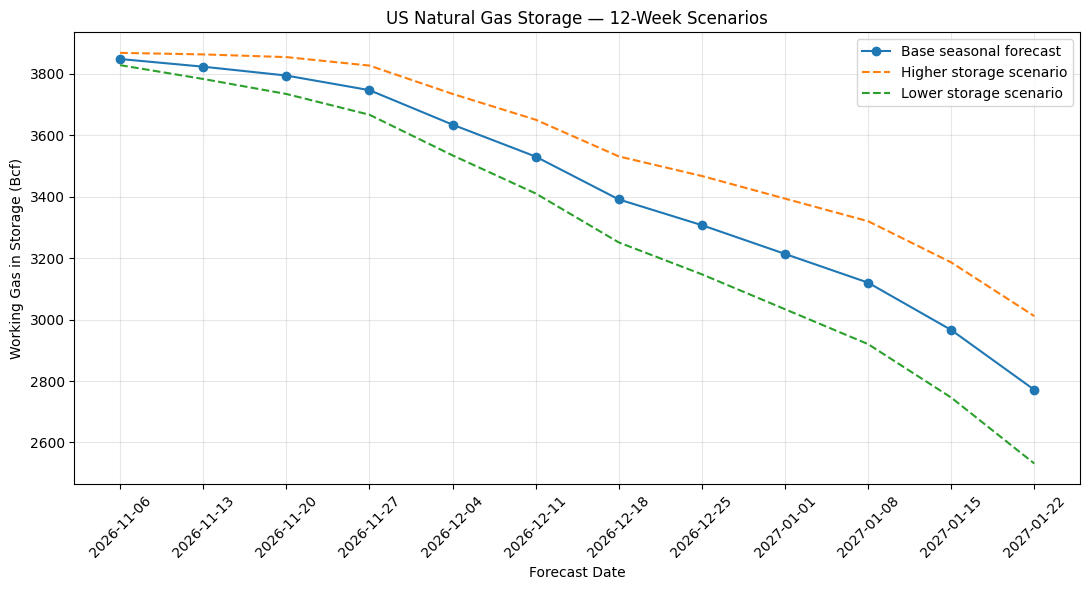


FORWARD STORAGE FORECAST
      Date  Horizon_Weeks  Base_Storage_Bcf  Higher_Storage_Bcf  Lower_Storage_Bcf
2026-11-06              1            3848.2              3868.2             3828.2
2026-11-13              2            3823.2              3863.2             3783.2
2026-11-20              3            3794.4              3854.4             3734.4
2026-11-27              4            3746.8              3826.8             3666.8
2026-12-04              5            3634.6              3734.6             3534.6
2026-12-11              6            3530.6              3650.6             3410.6
2026-12-18              7            3391.2              3531.2             3251.2
2026-12-25              8            3307.4              3467.4             3147.4
2027-01-01              9            3213.8              3393.8             3033.8
2027-01-08             10            3120.2              3320.2             2920.2
2027-01-15             11            2966.2              3186

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [25]:

# ============================================================
# CORRECTION BATCH — REBUILD FORWARD STORAGE FORECAST
# Creates natural_gas_storage_forecast.csv
# Does NOT use historical backtests as future forecasts.
# No API keys or external downloads.
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from google.colab import files

source = Path("eia_natural_gas_storage.csv")

if not source.exists():
    raise FileNotFoundError(
        "eia_natural_gas_storage.csv is not in the "
        "current Colab session. Upload your existing "
        "storage CSV to Colab before running this cell."
    )

storage = pd.read_csv(source)

storage["Date"] = pd.to_datetime(
    storage["Date"], errors="coerce"
)

storage["Storage_Bcf"] = pd.to_numeric(
    storage["Storage_Bcf"], errors="coerce"
)

storage = (
    storage.dropna(subset=["Date", "Storage_Bcf"])
    .sort_values("Date")
    .drop_duplicates("Date")
    .reset_index(drop=True)
)

if len(storage) < 104:
    raise ValueError(
        "At least two years of weekly storage history "
        "are required."
    )

# Use the last 5 years of historical weekly changes
# to estimate seasonally typical changes.
storage["Weekly_Change"] = (
    storage["Storage_Bcf"].diff()
)

storage["ISO_Week"] = (
    storage["Date"].dt.isocalendar().week.astype(int)
)

last_date = storage["Date"].max()
last_level = float(storage["Storage_Bcf"].iloc[-1])

history_start = last_date - pd.DateOffset(years=5)

history = storage[
    (storage["Date"] >= history_start)
    & (storage["Date"] < last_date)
].copy()

history = history.dropna(subset=["Weekly_Change"])

# Avoid week 53 mismatch by using the nearest
# available week when necessary.
weekly_changes = history.groupby("ISO_Week")[
    "Weekly_Change"
].agg(["mean", "std", "count"])

if weekly_changes.empty:
    raise ValueError("No seasonal history available.")

forecast_rows = []

base_level = last_level
high_level = last_level
low_level = last_level

for horizon in range(1, 13):

    future_date = last_date + pd.Timedelta(
        weeks=horizon
    )

    week = int(future_date.isocalendar().week)

    if week in weekly_changes.index:
        row = weekly_changes.loc[week]
    else:
        nearest_week = min(
            weekly_changes.index,
            key=lambda x: min(
                abs(x - week),
                53 - abs(x - week)
            )
        )
        row = weekly_changes.loc[nearest_week]

    avg_change = float(row["mean"])

    # Illustrative sensitivity: +/-20 Bcf per week
    # relative to the historical seasonal change.
    # These are scenarios, not confidence intervals.
    high_change = avg_change + 20
    low_change = avg_change - 20

    base_level += avg_change
    high_level += high_change
    low_level += low_change

    forecast_rows.append({
        "Date": future_date.strftime("%Y-%m-%d"),
        "Horizon_Weeks": horizon,
        "Base_Storage_Bcf": round(base_level, 2),
        "Higher_Storage_Bcf": round(high_level, 2),
        "Lower_Storage_Bcf": round(low_level, 2),
        "Expected_Weekly_Change_Bcf": round(
            avg_change, 2
        ),
        "Scenario_Adjustment_Bcf_Per_Week": 20,
        "Historical_Years": 5,
        "Starting_Storage_Bcf": last_level,
        "Starting_Date": last_date.strftime("%Y-%m-%d")
    })

forecast = pd.DataFrame(forecast_rows)

# ------------------------------------------------------------
# PLOT
# ------------------------------------------------------------

plt.figure(figsize=(11, 6))

plt.plot(
    forecast["Date"],
    forecast["Base_Storage_Bcf"],
    marker="o",
    label="Base seasonal forecast"
)

plt.plot(
    forecast["Date"],
    forecast["Higher_Storage_Bcf"],
    linestyle="--",
    label="Higher storage scenario"
)

plt.plot(
    forecast["Date"],
    forecast["Lower_Storage_Bcf"],
    linestyle="--",
    label="Lower storage scenario"
)

plt.title("US Natural Gas Storage — 12-Week Scenarios")
plt.ylabel("Working Gas in Storage (Bcf)")
plt.xlabel("Forecast Date")
plt.xticks(rotation=45)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("\nFORWARD STORAGE FORECAST")
print(
    forecast[
        [
            "Date",
            "Horizon_Weeks",
            "Base_Storage_Bcf",
            "Higher_Storage_Bcf",
            "Lower_Storage_Bcf"
        ]
    ].to_string(index=False)
)

filename = "natural_gas_storage_forecast.csv"

forecast.to_csv(filename, index=False)

print("\nFORECAST CREATED:", filename)
print("Forecast rows:", len(forecast))
print("Starting date:", last_date.date())
print("Starting storage:", last_level, "Bcf")

files.download(filename)



1. EUROPEAN PRICE SOURCE CHECK
Previous values matching fresh FRED data: 356 of 356


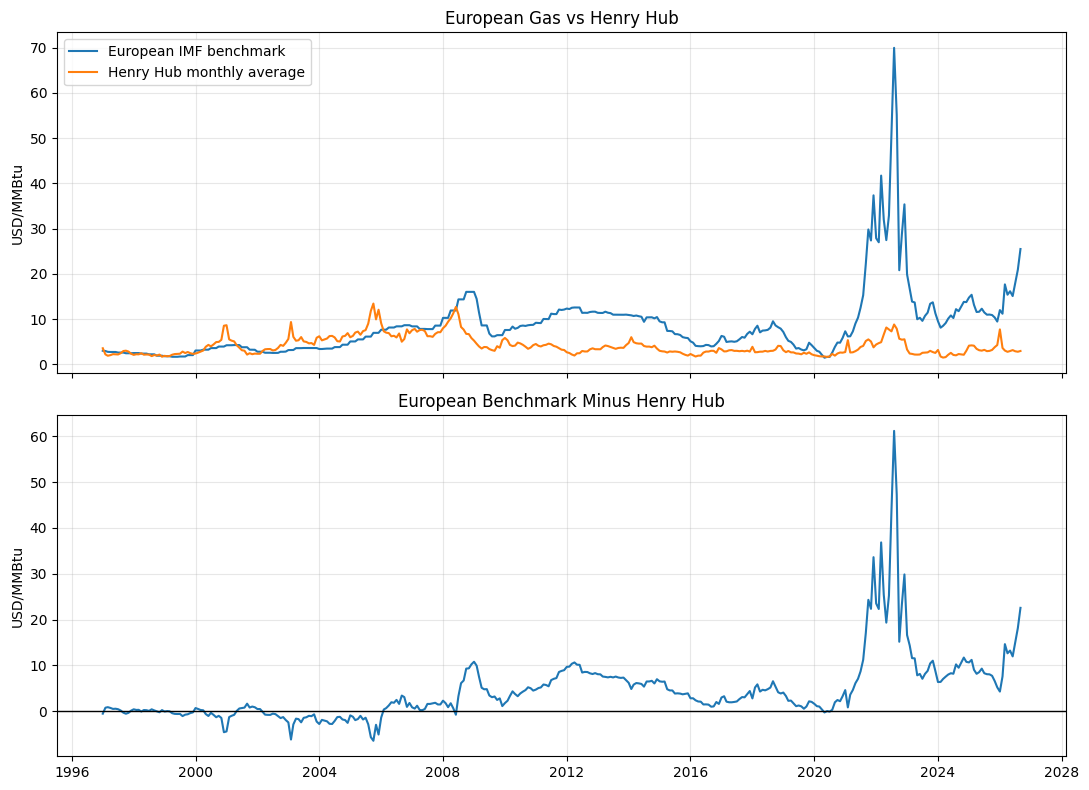

Latest European observation: 2026-09-01
Latest European benchmark: 25.494

2. UK GAS FUNDAMENTALS CHECK
Demand | rows: 119 | ID: PUBOB637 | units: ['mscm']
Linepack | rows: 119 | ID: PUBOB694 | units: ['mscm']
LNG | rows: 119 | ID: PUBOBJ629 | units: ['mscm']
LNG observations flagged for review: 10


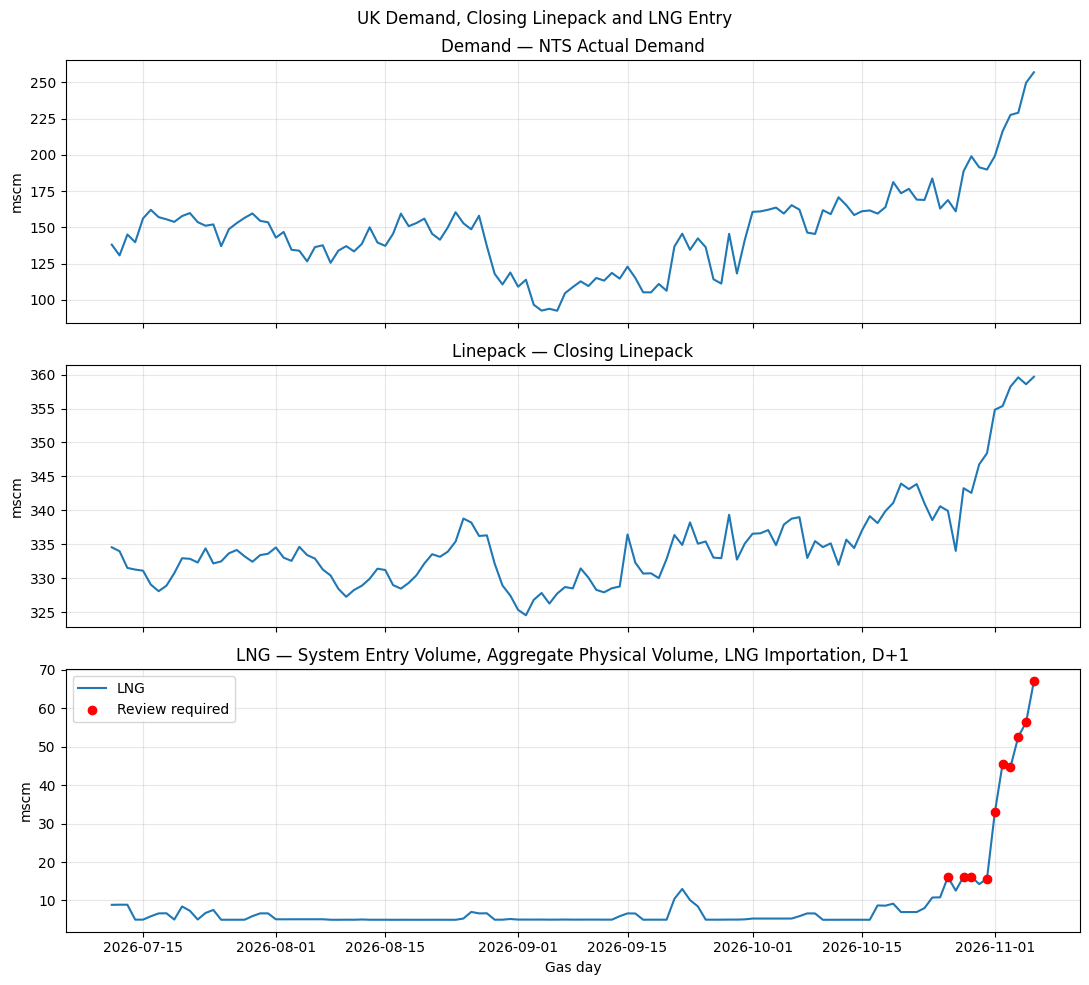

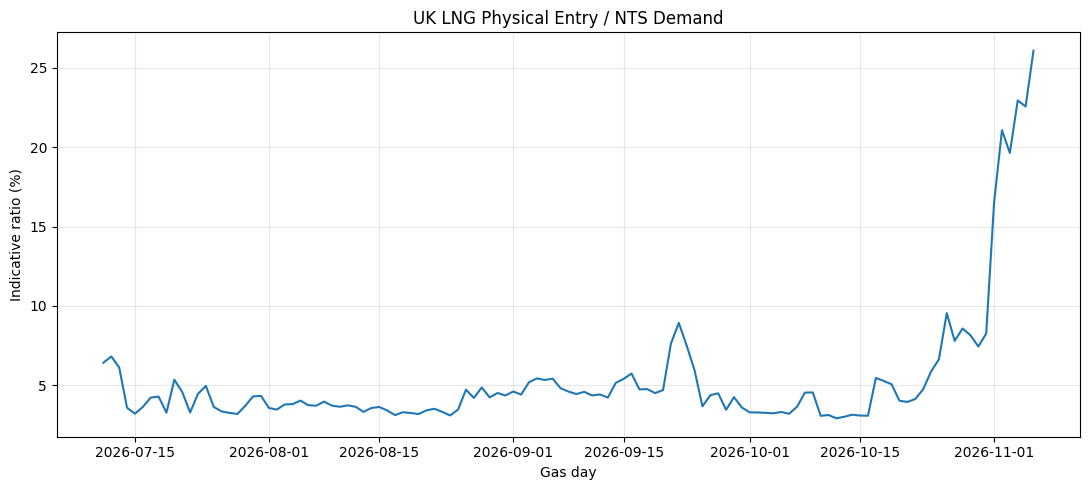


3. FORWARD STORAGE SCENARIOS


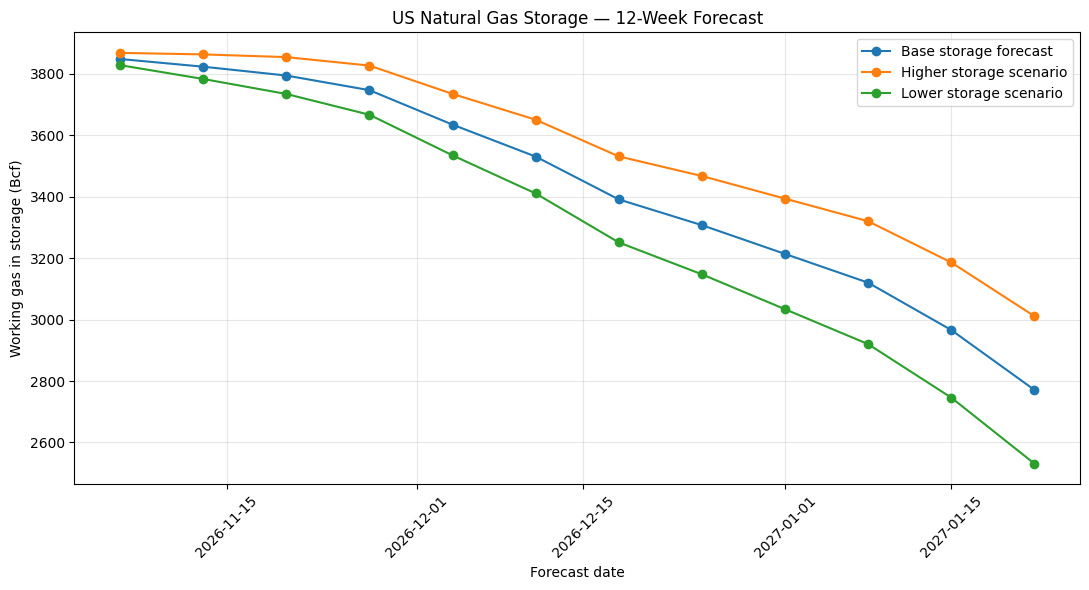

Forward scenario arithmetic: PASSED
12-week base: 2771.4 Bcf
12-week higher: 3011.4 Bcf
12-week lower: 2531.4 Bcf

4. ANALYST MARKET INTERPRETATION

EUROPEAN PRICE CONDITIONS
Europe / Henry Hub premium: 22.54 USD/MMBtu
Interpretation: This is a historical monthly benchmark difference, not a tradable LNG margin.

UK GAS CONDITIONS
Latest demand: 257.067 mscm
Latest LNG entry: 67.04482 mscm
Interpretation: LNG entry has shown elevated recent values, but independent verification is still required.

WINTER STORAGE SCENARIOS
Base: 2771.4 Bcf
Higher: 3011.4 Bcf
Lower: 2531.4 Bcf
Interpretation: Lower storage represents a tighter potential supply position; higher storage represents a looser one. Price direction is not guaranteed.

CORRECTION BATCH COMPLETED
Output file: natural_gas_corrected_market_analysis.csv
Rows: 1580
Sections: ['European Prices', 'Forward Storage Scenarios', 'UK Fundamentals']

CHECKS:
- European benchmark reloaded from FRED
- All 3 UK graphs displayed
- UK LNG review fl

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [26]:

# ============================================================
# NATURAL GAS — CORRECTION BATCH
# European prices, UK LNG, forward storage scenarios
#
# Keeps all 3 UK charts.
# Does not modify or delete original CSVs.
# No API key or manual source downloads.
# One CSV download.
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import requests
import io
from pathlib import Path
from google.colab import files

plt.rcParams["figure.figsize"] = (11, 5)

required = [
    "henry_hub_prices.csv",
    "uk_gas_three_series_validated.csv",
    "natural_gas_storage_forecast.csv"
]

missing = [f for f in required if not Path(f).exists()]

if missing:
    raise FileNotFoundError(
        "Missing files in this Colab runtime: "
        + ", ".join(missing)
        + ". These were created in earlier batches. "
        "Run those cells or upload the saved CSVs to Colab."
    )

output_rows = []

def save_row(date, section, indicator, value, unit,
             status, source, interpretation):
    if pd.isna(value):
        return
    output_rows.append({
        "Date": pd.Timestamp(date).strftime("%Y-%m-%d"),
        "Section": section,
        "Indicator": indicator,
        "Value": float(value),
        "Unit": unit,
        "Validation_Status": status,
        "Source": source,
        "Analyst_Interpretation": interpretation
    })

# ============================================================
# 1. VERIFY EUROPEAN PRICE BENCHMARK
# ============================================================

print("\n1. EUROPEAN PRICE SOURCE CHECK")

url = (
    "https://fred.stlouisfed.org/graph/"
    "fredgraph.csv?id=PNGASEUUSDM"
)

response = requests.get(url, timeout=60)
response.raise_for_status()

eu = pd.read_csv(io.StringIO(response.text))

date_col = eu.columns[0]

eu = eu.rename(columns={date_col: "Date"})

eu["Date"] = pd.to_datetime(
    eu["Date"], errors="coerce"
)

eu["European_Price"] = pd.to_numeric(
    eu["PNGASEUUSDM"], errors="coerce"
)

eu = (
    eu.dropna(subset=["Date", "European_Price"])
    .sort_values("Date")
)

hh = pd.read_csv("henry_hub_prices.csv")

hh["Date"] = pd.to_datetime(
    hh["Date"], errors="coerce"
)

hh["Henry_Hub_USD_MMBtu"] = pd.to_numeric(
    hh["Henry_Hub_USD_MMBtu"],
    errors="coerce"
)

hh = hh.dropna(
    subset=["Date", "Henry_Hub_USD_MMBtu"]
)

hh_monthly = (
    hh.set_index("Date")["Henry_Hub_USD_MMBtu"]
    .resample("MS")
    .agg(["mean", "count"])
    .reset_index()
    .rename(columns={
        "mean": "Henry_Hub",
        "count": "HH_Observations"
    })
)

# Compare monthly observations using the same month.
prices = eu[
    ["Date", "European_Price"]
].merge(
    hh_monthly,
    on="Date",
    how="inner"
)

prices = prices[
    prices["HH_Observations"] > 0
].copy()

prices["Premium"] = (
    prices["European_Price"]
    - prices["Henry_Hub"]
)

# Compare with previous Batch 9 data if present.
previous = Path("natural_gas_market_intelligence.csv")

if previous.exists():

    old = pd.read_csv(previous)

    old_prices = old[
        old["Indicator"] == "European gas benchmark"
    ][["Date", "Value"]].copy()

    old_prices["Date"] = pd.to_datetime(
        old_prices["Date"], errors="coerce"
    )

    old_prices = old_prices.rename(
        columns={"Value": "Previous_European_Price"}
    )

    prices = prices.merge(
        old_prices,
        on="Date",
        how="left"
    )

    prices["Source_Difference"] = (
        prices["European_Price"]
        - prices["Previous_European_Price"]
    )

    matches = (
        prices["Source_Difference"]
        .abs()
        .le(0.0001)
        | prices["Source_Difference"].isna()
    )

    print(
        "Previous values matching fresh FRED data:",
        int(matches.sum()),
        "of",
        len(prices)
    )

else:
    print(
        "Earlier intelligence CSV not present; "
        "using fresh FRED source values."
    )

fig, axes = plt.subplots(
    2, 1, figsize=(11, 8), sharex=True
)

axes[0].plot(
    prices["Date"],
    prices["European_Price"],
    label="European IMF benchmark"
)

axes[0].plot(
    prices["Date"],
    prices["Henry_Hub"],
    label="Henry Hub monthly average"
)

axes[0].set_ylabel("USD/MMBtu")
axes[0].set_title("European Gas vs Henry Hub")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(
    prices["Date"],
    prices["Premium"]
)

axes[1].axhline(0, color="black", linewidth=1)
axes[1].set_ylabel("USD/MMBtu")
axes[1].set_title(
    "European Benchmark Minus Henry Hub"
)
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

for r in prices.itertuples(index=False):

    for name, value in [
        ("European IMF gas benchmark",
         r.European_Price),
        ("Henry Hub monthly average",
         r.Henry_Hub),
        ("Europe minus Henry Hub premium",
         r.Premium)
    ]:

        save_row(
            r.Date,
            "European Prices",
            name,
            value,
            "USD/MMBtu",
            "Source checked; monthly observations",
            "IMF via FRED / FRED DHHNGSP",
            "Historical benchmark comparison. "
            "Not a live NBP/TTF quote or "
            "executable LNG arbitrage margin."
        )

print(
    "Latest European observation:",
    prices["Date"].max().date()
)

print(
    "Latest European benchmark:",
    round(prices["European_Price"].iloc[-1], 3)
)

# ============================================================
# 2. UK DEMAND, LINEPACK AND LNG
# ============================================================

print("\n2. UK GAS FUNDAMENTALS CHECK")

uk = pd.read_csv(
    "uk_gas_three_series_validated.csv"
)

uk["Date"] = pd.to_datetime(
    uk["Date"], errors="coerce"
)

uk["Value"] = pd.to_numeric(
    uk["Value"], errors="coerce"
)

uk = uk.dropna(subset=["Date", "Value"])

expected_ids = {
    "Demand": "PUBOB637",
    "Linepack": "PUBOB694",
    "LNG": "PUBOBJ629"
}

for category, pub_id in expected_ids.items():

    part = uk[
        uk["Category"] == category
    ].sort_values("Date")

    if part.empty:
        raise ValueError(
            f"Missing UK {category} data."
        )

    actual_ids = set(
        part["Publication_ID"].astype(str)
    )

    if actual_ids != {pub_id}:
        raise ValueError(
            f"{category} has unexpected "
            f"publication IDs: {actual_ids}"
        )

    print(
        category,
        "| rows:", len(part),
        "| ID:", pub_id,
        "| units:",
        part["Unit"].unique().tolist()
    )

# Keep all 3 charts.
fig, axes = plt.subplots(
    3, 1, figsize=(11, 10), sharex=True
)

for ax, category in zip(
    axes, ["Demand", "Linepack", "LNG"]
):

    part = uk[
        uk["Category"] == category
    ].sort_values("Date").copy()

    ax.plot(
        part["Date"],
        part["Value"],
        label=category
    )

    ax.set_title(
        category + " — " + part["Series"].iloc[0]
    )

    ax.set_ylabel(part["Unit"].iloc[0])
    ax.grid(alpha=0.3)

    if category == "LNG":

        # A relative change flag, not a claim
        # that the source value is incorrect.
        median = part["Value"].median()

        part["Review_Flag"] = (
            part["Value"] > 3 * median
        ) if median > 0 else False

        flagged = part[part["Review_Flag"]]

        if not flagged.empty:
            ax.scatter(
                flagged["Date"],
                flagged["Value"],
                color="red",
                label="Review required",
                zorder=3
            )

            ax.legend()

        print(
            "LNG observations flagged for review:",
            len(flagged)
        )

    else:
        part["Review_Flag"] = False

    for r in part.itertuples(index=False):

        status = (
            "Source definition and spike "
            "verification outstanding"
            if category == "LNG"
            else "Publication ID and units checked"
        )

        if category == "LNG" and r.Review_Flag:
            status = (
                "LNG elevated observation: "
                "independent verification required"
            )

        save_row(
            r.Date,
            "UK Fundamentals",
            category,
            r.Value,
            r.Unit,
            status,
            "National Gas " + pub_id
            if False else
            "National Gas "
            + expected_ids[category],
            "Operational gas-day data. "
            "LNG is physical NTS entry, "
            "not LNG cargo arrivals."
        )

axes[-1].set_xlabel("Gas day")

plt.suptitle(
    "UK Demand, Closing Linepack and LNG Entry"
)

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# Indicative LNG / demand ratio
# ------------------------------------------------------------

demand = uk[
    uk["Category"] == "Demand"
][["Date", "Value"]].rename(
    columns={"Value": "Demand_mscm"}
)

lng = uk[
    uk["Category"] == "LNG"
][["Date", "Value"]].rename(
    columns={"Value": "LNG_mscm"}
)

combined = demand.merge(
    lng, on="Date", how="inner"
)

combined = combined[
    combined["Demand_mscm"] > 0
].copy()

combined["LNG_to_Demand_Pct"] = (
    combined["LNG_mscm"]
    / combined["Demand_mscm"]
    * 100
)

plt.figure(figsize=(11, 5))

plt.plot(
    combined["Date"],
    combined["LNG_to_Demand_Pct"]
)

plt.title(
    "UK LNG Physical Entry / NTS Demand"
)

plt.ylabel("Indicative ratio (%)")
plt.xlabel("Gas day")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

for r in combined.itertuples(index=False):

    save_row(
        r.Date,
        "UK Fundamentals",
        "LNG entry / NTS demand",
        r.LNG_to_Demand_Pct,
        "%",
        "Indicative ratio; LNG review outstanding",
        "National Gas PUBOBJ629 / PUBOB637",
        "Partial indicator only. Not a "
        "complete UK gas supply-demand balance."
    )

# ============================================================
# 3. CORRECT FORWARD STORAGE FORECAST
# ============================================================

print("\n3. FORWARD STORAGE SCENARIOS")

forecast = pd.read_csv(
    "natural_gas_storage_forecast.csv"
)

forecast["Date"] = pd.to_datetime(
    forecast["Date"], errors="coerce"
)

forecast = forecast.sort_values(
    "Horizon_Weeks"
)

if (
    len(forecast) != 12
    or forecast["Horizon_Weeks"].tolist()
    != list(range(1, 13))
):
    raise ValueError(
        "Forward forecast must contain "
        "horizons 1 through 12."
    )

scenario_columns = {
    "Base_Storage_Bcf": "Base storage forecast",
    "Higher_Storage_Bcf": "Higher storage scenario",
    "Lower_Storage_Bcf": "Lower storage scenario"
}

plt.figure(figsize=(11, 6))

for column, label in scenario_columns.items():

    forecast[column] = pd.to_numeric(
        forecast[column], errors="coerce"
    )

    if forecast[column].isna().any():
        raise ValueError(
            "Missing forecast values in " + column
        )

    plt.plot(
        forecast["Date"],
        forecast[column],
        marker="o",
        label=label
    )

    for r in forecast.itertuples(index=False):

        save_row(
            r.Date,
            "Forward Storage Scenarios",
            label,
            getattr(r, column),
            "Bcf",
            "Forward scenario; not backtest validated",
            "Seasonal model from EIA storage history",
            "Higher storage may reduce supply "
            "tightness; lower storage may "
            "increase winter supply risk. "
            "Not a direct price forecast."
        )

plt.title(
    "US Natural Gas Storage — 12-Week Forecast"
)

plt.ylabel("Working gas in storage (Bcf)")
plt.xlabel("Forecast date")
plt.xticks(rotation=45)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Verify +/-20 Bcf per week scenario arithmetic.
base = forecast["Base_Storage_Bcf"]
higher = forecast["Higher_Storage_Bcf"]
lower = forecast["Lower_Storage_Bcf"]
horizon = forecast["Horizon_Weeks"]

high_ok = np.allclose(
    higher - base,
    20 * horizon,
    atol=0.05
)

low_ok = np.allclose(
    base - lower,
    20 * horizon,
    atol=0.05
)

if not (high_ok and low_ok):
    raise ValueError(
        "Scenario calculations are inconsistent."
    )

print("Forward scenario arithmetic: PASSED")
print(
    "12-week base:",
    round(base.iloc[-1], 2),
    "Bcf"
)

print(
    "12-week higher:",
    round(higher.iloc[-1], 2),
    "Bcf"
)

print(
    "12-week lower:",
    round(lower.iloc[-1], 2),
    "Bcf"
)

# ============================================================
# 4. CORRECTED ANALYST INTERPRETATION
# ============================================================

print("\n4. ANALYST MARKET INTERPRETATION")

latest_price = prices.iloc[-1]
latest_forecast = forecast.iloc[-1]

print("\nEUROPEAN PRICE CONDITIONS")

print(
    "Europe / Henry Hub premium:",
    round(latest_price["Premium"], 2),
    "USD/MMBtu"
)

print(
    "Interpretation: This is a historical "
    "monthly benchmark difference, not "
    "a tradable LNG margin."
)

print("\nUK GAS CONDITIONS")

print(
    "Latest demand:",
    uk[uk["Category"] == "Demand"]
    .sort_values("Date")["Value"].iloc[-1],
    "mscm"
)

print(
    "Latest LNG entry:",
    uk[uk["Category"] == "LNG"]
    .sort_values("Date")["Value"].iloc[-1],
    "mscm"
)

print(
    "Interpretation: LNG entry has "
    "shown elevated recent values, "
    "but independent verification "
    "is still required."
)

print("\nWINTER STORAGE SCENARIOS")

print(
    "Base:",
    latest_forecast["Base_Storage_Bcf"],
    "Bcf"
)

print(
    "Higher:",
    latest_forecast["Higher_Storage_Bcf"],
    "Bcf"
)

print(
    "Lower:",
    latest_forecast["Lower_Storage_Bcf"],
    "Bcf"
)

print(
    "Interpretation: Lower storage "
    "represents a tighter potential "
    "supply position; higher storage "
    "represents a looser one. "
    "Price direction is not guaranteed."
)

# ============================================================
# 5. SAVE CORRECTED DATA
# ============================================================

corrected = pd.DataFrame(output_rows)

corrected = corrected.sort_values(
    ["Section", "Indicator", "Date"]
).reset_index(drop=True)

filename = (
    "natural_gas_corrected_market_analysis.csv"
)

corrected.to_csv(filename, index=False)

print("\n" + "=" * 60)
print("CORRECTION BATCH COMPLETED")
print("=" * 60)

print("Output file:", filename)
print("Rows:", len(corrected))
print(
    "Sections:",
    corrected["Section"].unique().tolist()
)

print("\nCHECKS:")
print("- European benchmark reloaded from FRED")
print("- All 3 UK graphs displayed")
print("- UK LNG review flags retained")
print("- Forward forecast correctly identified")
print("- Forecast scenario arithmetic checked")
print("- Historical backtests kept separate")

print("\nREMAINING VALIDATION:")
print("- Independently verify UK LNG spike")
print("- Backtest this exact forecast method")
print("- Complete final trading insights")

files.download(filename)



PART 1 — UK LNG SOURCE VERIFICATION


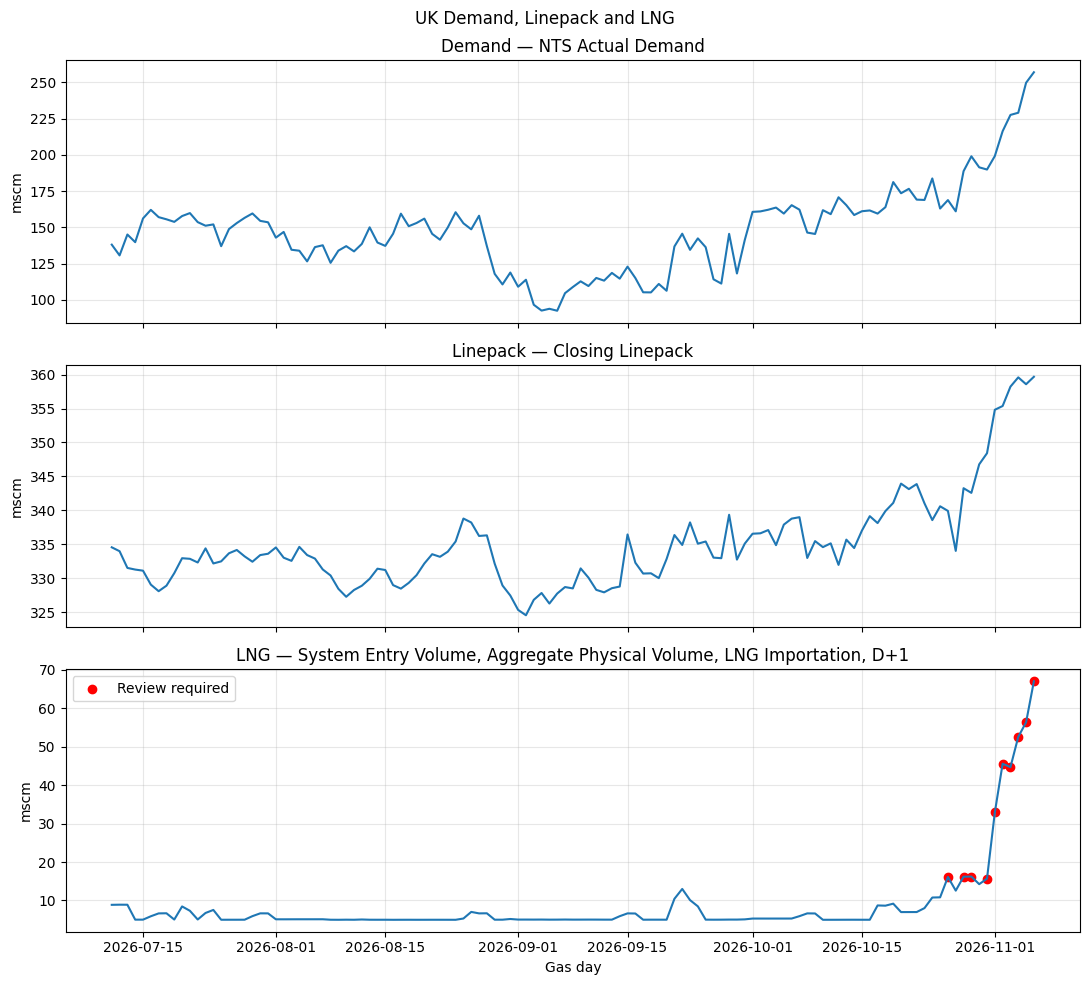

LNG publication: PUBOBJ629
LNG units: mscm
Saved LNG observations: 119

Fresh National Gas columns:
['Applicable At', 'Applicable For', 'Data Item', 'Value', 'Generated Time', 'Quality Indicator']

Source comparison limitation: Fresh CSV columns cannot be mapped unambiguously. Manual schema review is required; no match is assumed.

LNG source result: SOURCE CHECK NOT COMPLETED
Dates compared: 0
Matching values: 0

PART 2 — SEASONAL FORECAST BACKTEST

BACKTEST RESULTS
 Horizon_Weeks  Tests  MAE_Bcf  RMSE_Bcf  Bias_Bcf  Naive_MAE_Bcf  Improvement_vs_Naive_Pct
             4    150    82.85    113.75     -2.16         300.98                     72.47
             8    150   127.13    165.11     -3.68         569.29                     77.67
            12    150   165.21    203.68     -4.74         804.34                     79.46


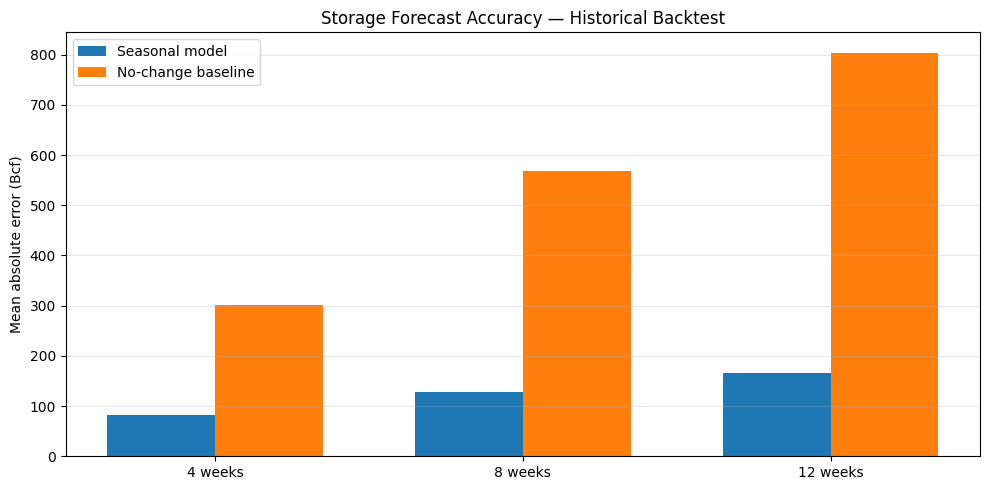

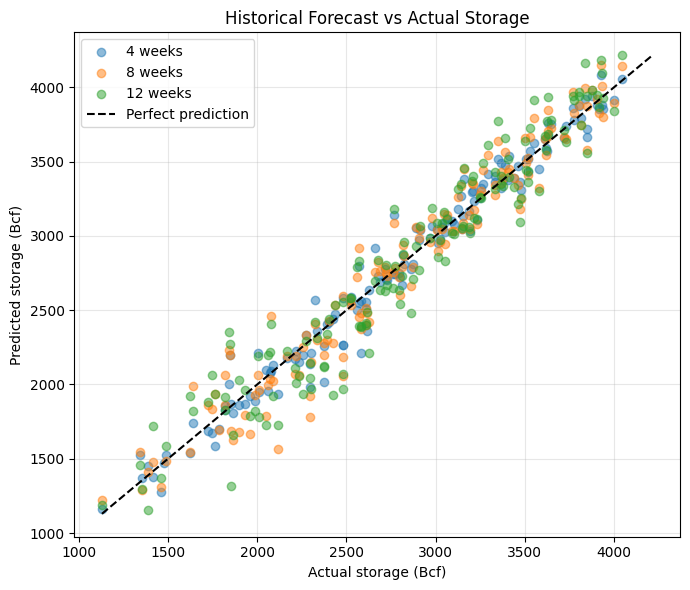


PART 3 — CURRENT FORWARD SCENARIOS


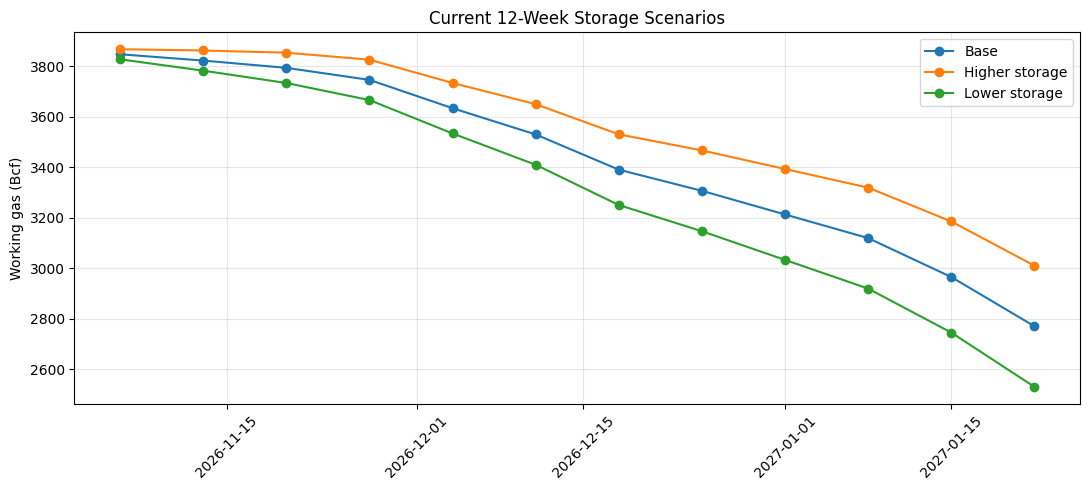


BATCH 13 COMPLETE
LNG source status: SOURCE CHECK NOT COMPLETED
LNG matching dates: 0 / 0
Historical backtest cases: 450
Forward forecast rows: 12
Total output rows: 608
CSV: natural_gas_batch13_validation.csv

IMPORTANT:
A source match does not independently prove the physical LNG flows.
Backtest performance is historical and does not guarantee future accuracy.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [27]:

# ============================================================
# BATCH 13 — FINAL VALIDATION
# 1. UK LNG source comparison
# 2. Exact seasonal forecast backtest
# 3. Preserve all three UK graphs
#
# No API key. One CSV download.
# Original files are not modified.
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import requests
import io
from pathlib import Path
from google.colab import files

plt.rcParams["figure.figsize"] = (11, 5)

NEEDED = [
    "uk_gas_three_series_validated.csv",
    "eia_natural_gas_storage.csv",
    "natural_gas_storage_forecast.csv"
]

missing = [f for f in NEEDED if not Path(f).exists()]
if missing:
    raise FileNotFoundError(
        "These CSVs are missing from this Colab session: "
        + ", ".join(missing)
    )

results = []

def record(section, date, item, actual=np.nan,
           predicted=np.nan, error=np.nan,
           status="", details=""):
    results.append({
        "Section": section,
        "Date": pd.Timestamp(date).strftime("%Y-%m-%d"),
        "Item": item,
        "Actual": actual,
        "Predicted": predicted,
        "Error": error,
        "Status": status,
        "Details": details
    })

# ============================================================
# PART 1 — UK LNG SOURCE COMPARISON
# ============================================================

print("\n" + "=" * 65)
print("PART 1 — UK LNG SOURCE VERIFICATION")
print("=" * 65)

uk = pd.read_csv("uk_gas_three_series_validated.csv")

uk["Date"] = pd.to_datetime(uk["Date"], errors="coerce")
uk["Value"] = pd.to_numeric(uk["Value"], errors="coerce")

uk = uk.dropna(subset=["Date", "Value"])

required_cols = {
    "Date", "Value", "Category", "Publication_ID",
    "Series", "Unit"
}
if not required_cols.issubset(uk.columns):
    raise ValueError(
        "UK CSV is missing: "
        + str(required_cols - set(uk.columns))
    )

expected_ids = {
    "Demand": "PUBOB637",
    "Linepack": "PUBOB694",
    "LNG": "PUBOBJ629"
}

# Preserve and display ALL THREE original graphs.
fig, axes = plt.subplots(
    3, 1, figsize=(11, 10), sharex=True
)

for ax, (category, expected_id) in zip(
    axes, expected_ids.items()
):
    part = uk[
        uk["Category"].astype(str).str.lower()
        == category.lower()
    ].sort_values("Date").copy()

    if part.empty:
        raise ValueError("Missing UK series: " + category)

    actual_ids = set(
        part["Publication_ID"].astype(str)
    )

    if actual_ids != {expected_id}:
        raise ValueError(
            f"{category}: unexpected publication IDs "
            f"{actual_ids}"
        )

    ax.plot(part["Date"], part["Value"])

    ax.set_title(
        category + " — " + str(part["Series"].iloc[0])
    )
    ax.set_ylabel(str(part["Unit"].iloc[0]))
    ax.grid(alpha=0.3)

    if category == "LNG":
        median = part["Value"].median()
        if median > 0:
            flagged = part[
                part["Value"] > 3 * median
            ]
            ax.scatter(
                flagged["Date"], flagged["Value"],
                color="red", label="Review required"
            )
            ax.legend()

axes[-1].set_xlabel("Gas day")
plt.suptitle("UK Demand, Linepack and LNG")
plt.tight_layout()
plt.show()

lng = uk[
    uk["Category"].astype(str).str.lower() == "lng"
].sort_values("Date").copy()

if lng.empty:
    raise ValueError("No LNG data available")

if lng["Unit"].astype(str).str.lower().nunique() != 1:
    raise ValueError("LNG has inconsistent units")

print("LNG publication:", lng["Publication_ID"].iloc[0])
print("LNG units:", lng["Unit"].iloc[0])
print("Saved LNG observations:", len(lng))

# Fetch the same publication independently from
# National Gas's public legacy CSV endpoint.
# Do not silently mark the series verified if
# the endpoint fails or the schema changes.

source_status = "SOURCE CHECK NOT COMPLETED"
matched_count = 0
compared_count = 0

try:
    endpoint = (
        "https://data.nationalgas.com/api/"
        "find-gas-data-download"
    )

    start = lng["Date"].min()
    end = lng["Date"].max()

    params = {
        "applicableFor": "Y",
        "dateFrom": start.strftime(
            "%Y-%m-%dT00:00:00"
        ),
        "dateTo": end.strftime(
            "%Y-%m-%dT23:59:59"
        ),
        "dateType": "GASDAY",
        "latestFlag": "Y",
        "ids": "PUBOBJ629",
        "type": "CSV"
    }

    response = requests.get(
        endpoint, params=params, timeout=90
    )
    response.raise_for_status()

    fresh = pd.read_csv(
        io.StringIO(response.text),
        low_memory=False
    )

    print("\nFresh National Gas columns:")
    print(fresh.columns.tolist())

    # Only compare values when date and numeric
    # columns can be identified unambiguously.
    date_candidates = [
        c for c in fresh.columns
        if "gas day" in c.lower()
        or "gasday" in c.lower()
        or "applicable" in c.lower()
    ]

    value_candidates = [
        c for c in fresh.columns
        if c.strip().lower() in {
            "value", "item value", "data value"
        }
    ]

    if (
        len(date_candidates) != 1
        or len(value_candidates) != 1
    ):
        raise ValueError(
            "Fresh CSV columns cannot be mapped "
            "unambiguously. Manual schema review "
            "is required; no match is assumed."
        )

    fresh["Check_Date"] = pd.to_datetime(
        fresh[date_candidates[0]],
        errors="coerce",
        utc=True
    ).dt.tz_localize(None).dt.normalize()

    fresh["Check_Value"] = pd.to_numeric(
        fresh[value_candidates[0]],
        errors="coerce"
    )

    fresh = fresh.dropna(
        subset=["Check_Date", "Check_Value"]
    )

    # Avoid choosing arbitrarily between
    # multiple publications for one gas day.
    if fresh["Check_Date"].duplicated().any():
        raise ValueError(
            "Multiple fresh records per gas day. "
            "Publication timing must be reviewed."
        )

    original = lng[
        ["Date", "Value"]
    ].copy()

    original["Date"] = original["Date"].dt.normalize()

    comparison = original.merge(
        fresh[["Check_Date", "Check_Value"]],
        left_on="Date",
        right_on="Check_Date",
        how="left"
    )

    comparison["Difference"] = (
        comparison["Value"]
        - comparison["Check_Value"]
    )

    compared = comparison.dropna(
        subset=["Check_Value"]
    )

    compared_count = len(compared)

    matched_count = int(
        np.isclose(
            compared["Value"],
            compared["Check_Value"],
            rtol=0,
            atol=0.01
        ).sum()
    )

    if compared_count == 0:
        source_status = "NO OVERLAPPING SOURCE DATES"
    elif (
        matched_count == compared_count
        and compared_count == len(original)
    ):
        source_status = (
            "ALL SAVED OBSERVATIONS MATCH "
            "FRESH PUBLICATION"
        )
    else:
        source_status = (
            "PARTIAL MATCH OR REVISED VALUES"
        )

    for r in comparison.itertuples(index=False):
        matched = (
            pd.notna(r.Check_Value)
            and abs(r.Difference) <= 0.01
        )

        record(
            "UK LNG Source Check",
            r.Date,
            "PUBOBJ629 LNG",
            r.Value,
            r.Check_Value,
            r.Difference,
            "MATCH" if matched else "REVIEW",
            "Fresh National Gas CSV comparison; "
            "does not independently establish "
            "physical flow accuracy"
        )

except Exception as exc:
    print("\nSource comparison limitation:", str(exc))
    source_status = "SOURCE CHECK NOT COMPLETED"

    for r in lng.itertuples(index=False):
        record(
            "UK LNG Source Check",
            r.Date,
            "PUBOBJ629 LNG",
            r.Value,
            status="UNVERIFIED",
            details=(
                "Automated source comparison unavailable: "
                + str(exc)[:180]
            )
        )

print("\nLNG source result:", source_status)
print("Dates compared:", compared_count)
print("Matching values:", matched_count)

# ============================================================
# PART 2 — EXACT SEASONAL FORECAST BACKTEST
# ============================================================

print("\n" + "=" * 65)
print("PART 2 — SEASONAL FORECAST BACKTEST")
print("=" * 65)

storage = pd.read_csv("eia_natural_gas_storage.csv")

storage["Date"] = pd.to_datetime(
    storage["Date"], errors="coerce"
)
storage["Storage_Bcf"] = pd.to_numeric(
    storage["Storage_Bcf"], errors="coerce"
)

storage = (
    storage.dropna(subset=["Date", "Storage_Bcf"])
    .sort_values("Date")
    .drop_duplicates("Date")
    .reset_index(drop=True)
)

storage["Weekly_Change"] = (
    storage["Storage_Bcf"].diff()
)
storage["ISO_Week"] = (
    storage["Date"].dt.isocalendar().week.astype(int)
)

forecast = pd.read_csv(
    "natural_gas_storage_forecast.csv"
)

forecast["Date"] = pd.to_datetime(
    forecast["Date"], errors="coerce"
)

forecast = forecast.sort_values("Horizon_Weeks")

if (
    len(forecast) != 12
    or forecast["Horizon_Weeks"].tolist()
    != list(range(1, 13))
):
    raise ValueError(
        "Forward forecast horizons must be 1–12"
    )

# Match the actual method used to build the
# forward forecast:
# - prior 5 years of weekly storage changes
# - ISO-week seasonal mean
# - 12-week cumulative projection
# - no use of future observations

def seasonal_prediction(origin_index, horizon):
    origin = storage.iloc[origin_index]
    origin_date = origin["Date"]

    history_start = (
        origin_date - pd.DateOffset(years=5)
    )

    history = storage[
        (storage["Date"] >= history_start)
        & (storage["Date"] < origin_date)
    ].dropna(subset=["Weekly_Change"])

    seasonal = history.groupby("ISO_Week")[
        "Weekly_Change"
    ].mean()

    if seasonal.empty:
        return np.nan

    level = float(origin["Storage_Bcf"])

    for step in range(1, horizon + 1):
        future_date = (
            origin_date + pd.Timedelta(weeks=step)
        )
        week = int(
            future_date.isocalendar().week
        )

        if week in seasonal.index:
            change = float(seasonal.loc[week])
        else:
            nearest = min(
                seasonal.index,
                key=lambda x: min(
                    abs(int(x) - week),
                    53 - abs(int(x) - week)
                )
            )
            change = float(seasonal.loc[nearest])

        level += change

    return level

# Weekly observations, with approximately
# 5 years of prior data and 12 future weeks.
# Use a 4-week step between test origins to
# reduce excessive overlap.
backtest_rows = []

first_origin = 5 * 52 + 10
last_origin = len(storage) - 13

for i in range(first_origin, last_origin + 1, 4):

    origin = storage.iloc[i]
    origin_date = origin["Date"]
    origin_level = float(origin["Storage_Bcf"])

    for horizon in [4, 8, 12]:

        target_date = (
            origin_date
            + pd.Timedelta(weeks=horizon)
        )

        # Match an actual observation on the
        # intended date, not merely row i+horizon.
        actual_match = storage[
            storage["Date"] == target_date
        ]

        if actual_match.empty:
            continue

        predicted = seasonal_prediction(
            i, horizon
        )

        if pd.isna(predicted):
            continue

        actual = float(
            actual_match["Storage_Bcf"].iloc[0]
        )

        error = predicted - actual

        backtest_rows.append({
            "Origin_Date": origin_date,
            "Target_Date": target_date,
            "Horizon_Weeks": horizon,
            "Actual_Bcf": actual,
            "Predicted_Bcf": predicted,
            "Error_Bcf": error,
            "Abs_Error_Bcf": abs(error),
            "Naive_Predicted_Bcf": origin_level,
            "Naive_Abs_Error_Bcf": abs(
                origin_level - actual
            )
        })

bt = pd.DataFrame(backtest_rows)

if bt.empty:
    raise ValueError(
        "No historical backtest observations "
        "could be constructed."
    )

summary = (
    bt.groupby("Horizon_Weeks")
    .agg(
        Tests=("Error_Bcf", "size"),
        MAE_Bcf=("Abs_Error_Bcf", "mean"),
        RMSE_Bcf=(
            "Error_Bcf",
            lambda x: np.sqrt(np.mean(x**2))
        ),
        Bias_Bcf=("Error_Bcf", "mean"),
        Naive_MAE_Bcf=(
            "Naive_Abs_Error_Bcf", "mean"
        )
    )
    .reset_index()
)

summary["Improvement_vs_Naive_Pct"] = (
    100 * (
        1 - summary["MAE_Bcf"]
        / summary["Naive_MAE_Bcf"]
    )
)

print("\nBACKTEST RESULTS")
print(summary.round(2).to_string(index=False))

# Plot error comparison.
x = np.arange(len(summary))
width = 0.35

plt.figure(figsize=(10, 5))

plt.bar(
    x - width/2,
    summary["MAE_Bcf"],
    width,
    label="Seasonal model"
)

plt.bar(
    x + width/2,
    summary["Naive_MAE_Bcf"],
    width,
    label="No-change baseline"
)

plt.xticks(
    x,
    [
        str(v) + " weeks"
        for v in summary["Horizon_Weeks"]
    ]
)

plt.title(
    "Storage Forecast Accuracy — Historical Backtest"
)
plt.ylabel("Mean absolute error (Bcf)")
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

# Forecast vs actual scatter.
plt.figure(figsize=(7, 6))

for horizon in [4, 8, 12]:
    subset = bt[
        bt["Horizon_Weeks"] == horizon
    ]

    plt.scatter(
        subset["Actual_Bcf"],
        subset["Predicted_Bcf"],
        alpha=0.5,
        label=str(horizon) + " weeks"
    )

minimum = min(
    bt["Actual_Bcf"].min(),
    bt["Predicted_Bcf"].min()
)
maximum = max(
    bt["Actual_Bcf"].max(),
    bt["Predicted_Bcf"].max()
)

plt.plot(
    [minimum, maximum],
    [minimum, maximum],
    "k--",
    label="Perfect prediction"
)

plt.title("Historical Forecast vs Actual Storage")
plt.xlabel("Actual storage (Bcf)")
plt.ylabel("Predicted storage (Bcf)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

for r in bt.itertuples(index=False):
    record(
        "Seasonal Forecast Backtest",
        r.Target_Date,
        str(r.Horizon_Weeks) + "-week forecast",
        r.Actual_Bcf,
        r.Predicted_Bcf,
        r.Error_Bcf,
        "HISTORICAL BACKTEST",
        "Origin: " + str(r.Origin_Date.date())
        + "; naive baseline: "
        + str(round(r.Naive_Predicted_Bcf, 2))
    )

for r in summary.itertuples(index=False):
    record(
        "Backtest Summary",
        storage["Date"].max(),
        str(r.Horizon_Weeks) + "-week MAE",
        r.Naive_MAE_Bcf,
        r.MAE_Bcf,
        r.Bias_Bcf,
        "MODEL PERFORMANCE",
        "Tests=" + str(r.Tests)
        + "; RMSE=" + str(round(r.RMSE_Bcf, 2))
        + "; improvement vs naive="
        + str(round(r.Improvement_vs_Naive_Pct, 2))
        + "%"
    )

# ============================================================
# PART 3 — PRESERVE CURRENT FORWARD SCENARIOS
# ============================================================

print("\n" + "=" * 65)
print("PART 3 — CURRENT FORWARD SCENARIOS")
print("=" * 65)

for col in [
    "Base_Storage_Bcf",
    "Higher_Storage_Bcf",
    "Lower_Storage_Bcf"
]:
    forecast[col] = pd.to_numeric(
        forecast[col], errors="coerce"
    )

if forecast[
    [
        "Base_Storage_Bcf",
        "Higher_Storage_Bcf",
        "Lower_Storage_Bcf"
    ]
].isna().any().any():
    raise ValueError("Forward scenario contains missing values")

h = forecast["Horizon_Weeks"].to_numpy()

if not (
    np.allclose(
        forecast["Higher_Storage_Bcf"]
        - forecast["Base_Storage_Bcf"],
        20*h,
        atol=0.05
    )
    and np.allclose(
        forecast["Base_Storage_Bcf"]
        - forecast["Lower_Storage_Bcf"],
        20*h,
        atol=0.05
    )
):
    raise ValueError("Scenario arithmetic failed")

plt.figure(figsize=(11, 5))

for col, label in [
    ("Base_Storage_Bcf", "Base"),
    ("Higher_Storage_Bcf", "Higher storage"),
    ("Lower_Storage_Bcf", "Lower storage")
]:
    plt.plot(
        forecast["Date"],
        forecast[col],
        marker="o",
        label=label
    )

    for r in forecast.itertuples(index=False):
        record(
            "Forward Storage Scenario",
            r.Date,
            label,
            predicted=getattr(r, col),
            status="ILLUSTRATIVE SCENARIO",
            details=(
                "Five-year seasonal model; "
                "higher/lower paths use "
                "+/-20 Bcf per week"
            )
        )

plt.title("Current 12-Week Storage Scenarios")
plt.ylabel("Working gas (Bcf)")
plt.xticks(rotation=45)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# ============================================================
# PART 4 — ONE CSV DOWNLOAD
# ============================================================

output = pd.DataFrame(results)

filename = "natural_gas_batch13_validation.csv"
output.to_csv(filename, index=False)

print("\n" + "=" * 65)
print("BATCH 13 COMPLETE")
print("=" * 65)

print("LNG source status:", source_status)
print("LNG matching dates:", matched_count, "/", compared_count)
print("Historical backtest cases:", len(bt))
print("Forward forecast rows:", len(forecast))
print("Total output rows:", len(output))
print("CSV:", filename)

print("\nIMPORTANT:")
print(
    "A source match does not independently "
    "prove the physical LNG flows."
)
print(
    "Backtest performance is historical "
    "and does not guarantee future accuracy."
)

files.download(filename)


In [28]:

# BATCH 13B — NATIONAL GAS SOURCE FORMAT DIAGNOSTIC
# No API key. No original files modified.
# One CSV download.

import requests
import pandas as pd
import io
from google.colab import files

url = "https://data.nationalgas.com/api/find-gas-data-download"

params = {
    "applicableFor": "Y",
    "dateFrom": "2026-10-25T00:00:00",
    "dateTo": "2026-11-07T23:59:59",
    "dateType": "GASDAY",
    "latestFlag": "Y",
    "ids": "PUBOBJ629",
    "type": "CSV"
}

response = requests.get(url, params=params, timeout=90)
response.raise_for_status()

print("HTTP status:", response.status_code)
print("Content type:", response.headers.get("Content-Type"))
print("First 500 characters:")
print(response.text[:500])

fresh = pd.read_csv(io.StringIO(response.text))

print("\nCOLUMN NAMES:")
print(fresh.columns.tolist())

print("\nFIRST FIVE ROWS:")
print(fresh.head().to_string(index=False))

# Export a small diagnostic sample.
# It may contain dates and values, but no credentials.
filename = "uk_lng_source_diagnostic.csv"
fresh.head(20).to_csv(filename, index=False)

print("\nDiagnostic created:", filename)
files.download(filename)


HTTP status: 200
Content type: text/csv; charset=utf-8
First 500 characters:
Applicable At,Applicable For,Data Item,Value,Generated Time,Quality Indicator
06/11/2026 00:00:00,06/11/2026,"System Entry Volume, Aggregate Physical Volume, LNG Importation, D+1",67.04482,07/11/2026 12:01:00,L
05/11/2026 00:00:00,05/11/2026,"System Entry Volume, Aggregate Physical Volume, LNG Importation, D+1",56.36225,06/11/2026 12:01:01,L
04/11/2026 00:00:00,04/11/2026,"System Entry Volume, Aggregate Physical Volume, LNG Importation, D+1",52.58296,05/11/2026 12:01:00,L
03/11/2026 00:00:00,03/

COLUMN NAMES:
['Applicable At', 'Applicable For', 'Data Item', 'Value', 'Generated Time', 'Quality Indicator']

FIRST FIVE ROWS:
      Applicable At Applicable For                                                            Data Item    Value      Generated Time Quality Indicator
06/11/2026 00:00:00     06/11/2026 System Entry Volume, Aggregate Physical Volume, LNG Importation, D+1 67.04482 07/11/2026 12:01:00         

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

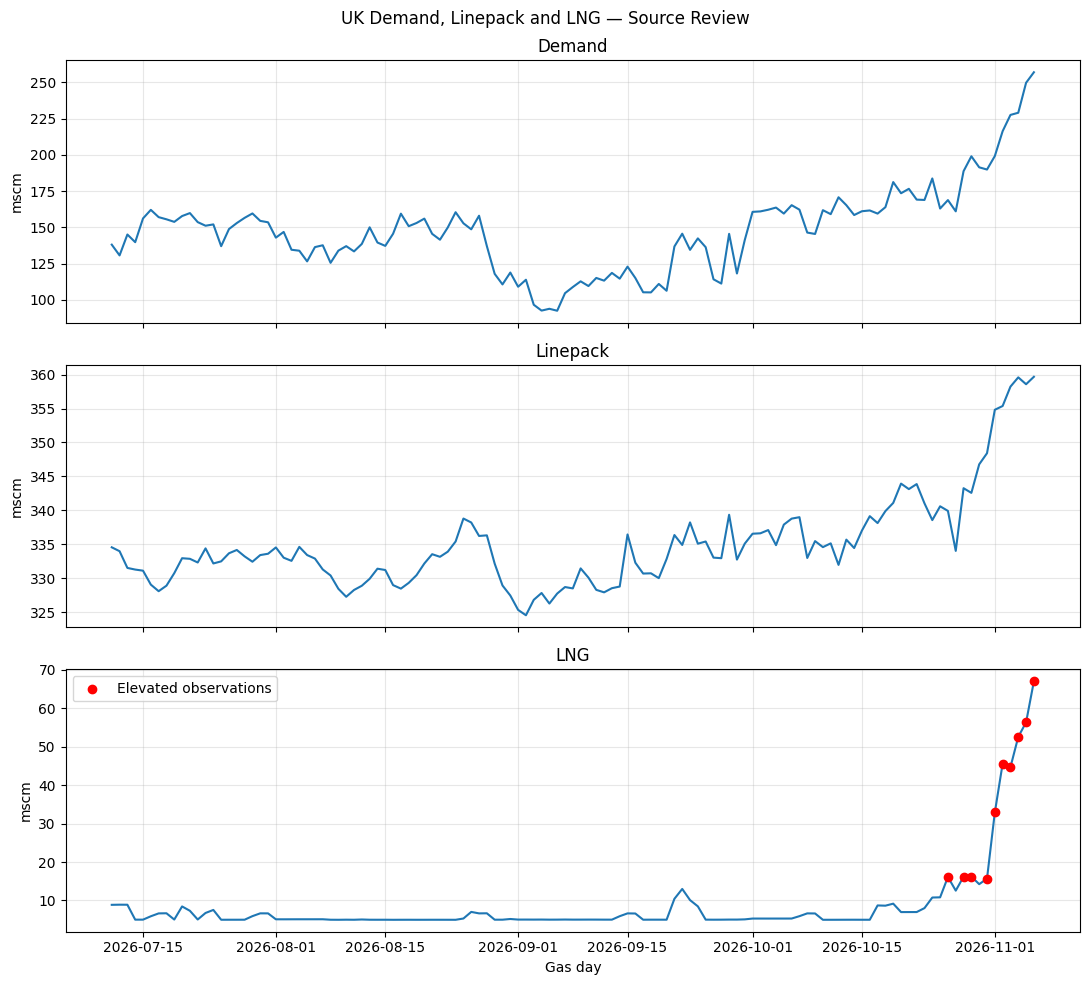


BATCH 13C — VERIFICATION RESULTS
Saved observations: 119
Matching: 119
Differences: 0
Missing source dates: 0
Elevated LNG observations: 10

Official quality indicators:
Quality Indicator
L    116
A      3

Last 10 observations:
      Date  Saved_Value  Official_Value  Difference Status Quality Indicator
2026-10-28     16.17571        16.17571         0.0  MATCH                 L
2026-10-29     16.21259        16.21259         0.0  MATCH                 L
2026-10-30     14.23224        14.23224         0.0  MATCH                 L
2026-10-31     15.67009        15.67009         0.0  MATCH                 A
2026-11-01     32.89744        32.89744         0.0  MATCH                 A
2026-11-02     45.59252        45.59252         0.0  MATCH                 L
2026-11-03     44.69426        44.69426         0.0  MATCH                 L
2026-11-04     52.58296        52.58296         0.0  MATCH                 L
2026-11-05     56.36225        56.36225         0.0  MATCH                 L


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [29]:

# ============================================================
# BATCH 13C — UK LNG SOURCE VERIFICATION
# Correct National Gas date and value columns
# No API key. One CSV download.
# Keeps original files unchanged.
# ============================================================

import pandas as pd
import numpy as np
import requests
import io
import matplotlib.pyplot as plt
from pathlib import Path
from google.colab import files

source_file = Path("uk_gas_three_series_validated.csv")

if not source_file.exists():
    raise FileNotFoundError(
        "uk_gas_three_series_validated.csv is missing "
        "from the current Colab runtime."
    )

uk = pd.read_csv(source_file)

required = {
    "Date", "Value", "Category", "Publication_ID"
}
if not required.issubset(uk.columns):
    raise ValueError(
        "Missing UK columns: "
        + str(required - set(uk.columns))
    )

uk["Date"] = pd.to_datetime(
    uk["Date"], errors="coerce"
).dt.normalize()

uk["Value"] = pd.to_numeric(
    uk["Value"], errors="coerce"
)

lng = uk[
    uk["Category"].astype(str).str.lower().eq("lng")
].copy()

lng = lng[
    lng["Publication_ID"].astype(str).eq("PUBOBJ629")
]

lng = lng.dropna(subset=["Date", "Value"])

if lng.empty:
    raise ValueError("No valid PUBOBJ629 LNG records.")

if lng["Date"].duplicated().any():
    raise ValueError("Duplicate LNG dates in saved CSV.")

# Download the same gas-day publication directly.
endpoint = (
    "https://data.nationalgas.com/api/"
    "find-gas-data-download"
)

params = {
    "applicableFor": "Y",
    "dateFrom": lng["Date"].min().strftime(
        "%Y-%m-%dT00:00:00"
    ),
    "dateTo": lng["Date"].max().strftime(
        "%Y-%m-%dT23:59:59"
    ),
    "dateType": "GASDAY",
    "latestFlag": "Y",
    "ids": "PUBOBJ629",
    "type": "CSV"
}

response = requests.get(
    endpoint, params=params, timeout=90
)
response.raise_for_status()

fresh = pd.read_csv(
    io.StringIO(response.text)
)

required_fresh = {
    "Applicable For", "Value",
    "Data Item", "Generated Time",
    "Quality Indicator"
}

if not required_fresh.issubset(fresh.columns):
    raise ValueError(
        "National Gas format changed: "
        + str(required_fresh - set(fresh.columns))
    )

fresh["Date"] = pd.to_datetime(
    fresh["Applicable For"],
    format="%d/%m/%Y",
    errors="coerce"
)

fresh["Official_Value"] = pd.to_numeric(
    fresh["Value"], errors="coerce"
)

fresh = fresh.dropna(
    subset=["Date", "Official_Value"]
)

fresh = fresh[
    fresh["Data Item"].astype(str).str.contains(
        "LNG Importation", case=False, na=False
    )
].copy()

if fresh.empty:
    raise ValueError(
        "No LNG importation records in fresh source."
    )

if fresh["Date"].duplicated().any():
    raise ValueError(
        "Multiple official values for one gas day. "
        "Publication revisions require review."
    )

comparison = lng[
    ["Date", "Value"]
].rename(
    columns={"Value": "Saved_Value"}
).merge(
    fresh[
        [
            "Date",
            "Official_Value",
            "Generated Time",
            "Quality Indicator",
            "Data Item"
        ]
    ],
    on="Date",
    how="left",
    validate="one_to_one"
)

comparison["Difference"] = (
    comparison["Saved_Value"]
    - comparison["Official_Value"]
)

comparison["Status"] = np.select(
    [
        comparison["Official_Value"].isna(),
        comparison["Difference"].abs() <= 0.01
    ],
    [
        "NO SOURCE MATCH",
        "MATCH"
    ],
    default="VALUE DIFFERENCE"
)

# Preserve elevated-value review flags.
median = lng["Value"].median()

comparison["Elevated_Value_Flag"] = (
    comparison["Saved_Value"] > 3 * median
    if median > 0
    else False
)

comparison["Publication_ID"] = "PUBOBJ629"
comparison["Unit"] = (
    lng["Unit"].iloc[0]
    if "Unit" in lng.columns
    else "Check source units"
)

comparison["Verification_Scope"] = (
    "Agreement with published National Gas data; "
    "not independent physical-flow confirmation"
)

# Plot all three UK graphs again.
fig, axes = plt.subplots(
    3, 1, figsize=(11, 10), sharex=True
)

for ax, category in zip(
    axes, ["Demand", "Linepack", "LNG"]
):
    part = uk[
        uk["Category"].astype(str)
        .str.lower().eq(category.lower())
    ].sort_values("Date")

    if part.empty:
        raise ValueError(
            "Missing UK chart: " + category
        )

    ax.plot(part["Date"], part["Value"])

    ax.set_title(category)
    ax.set_ylabel(
        part["Unit"].iloc[0]
        if "Unit" in part.columns
        else "Reported units"
    )
    ax.grid(alpha=0.3)

    if category == "LNG":
        flagged = comparison[
            comparison["Elevated_Value_Flag"]
        ]
        ax.scatter(
            flagged["Date"],
            flagged["Saved_Value"],
            color="red",
            label="Elevated observations",
            zorder=3
        )
        ax.legend()

axes[-1].set_xlabel("Gas day")
plt.suptitle(
    "UK Demand, Linepack and LNG — Source Review"
)
plt.tight_layout()
plt.show()

# Save one CSV.
filename = "uk_lng_source_verified.csv"

comparison.sort_values("Date").to_csv(
    filename, index=False
)

print("\n" + "=" * 60)
print("BATCH 13C — VERIFICATION RESULTS")
print("=" * 60)

print("Saved observations:", len(comparison))
print(
    "Matching:",
    int((comparison["Status"] == "MATCH").sum())
)
print(
    "Differences:",
    int((
        comparison["Status"] == "VALUE DIFFERENCE"
    ).sum())
)
print(
    "Missing source dates:",
    int((
        comparison["Status"] == "NO SOURCE MATCH"
    ).sum())
)
print(
    "Elevated LNG observations:",
    int(comparison["Elevated_Value_Flag"].sum())
)

print("\nOfficial quality indicators:")
print(
    comparison["Quality Indicator"]
    .value_counts(dropna=False)
    .to_string()
)

print("\nLast 10 observations:")
print(
    comparison.tail(10)[
        [
            "Date",
            "Saved_Value",
            "Official_Value",
            "Difference",
            "Status",
            "Quality Indicator"
        ]
    ].to_string(index=False)
)

if (comparison["Status"] == "MATCH").all():
    print(
        "\nPASS: All saved LNG values match "
        "the current published source."
    )
else:
    print(
        "\nREVIEW REQUIRED: Some LNG values "
        "did not match the current source."
    )

print("\nCSV created:", filename)
files.download(filename)


BATCH 14 — DATA VALIDATION
UK LNG: 119/119 observations match National Gas publication PUBOBJ629.
Seasonal model 12-week MAE: 165.21 Bcf

PRICE COMPARISON
Latest aligned month: 2026-09
European benchmark: 25.494
Henry Hub: 2.95
Premium: 22.544


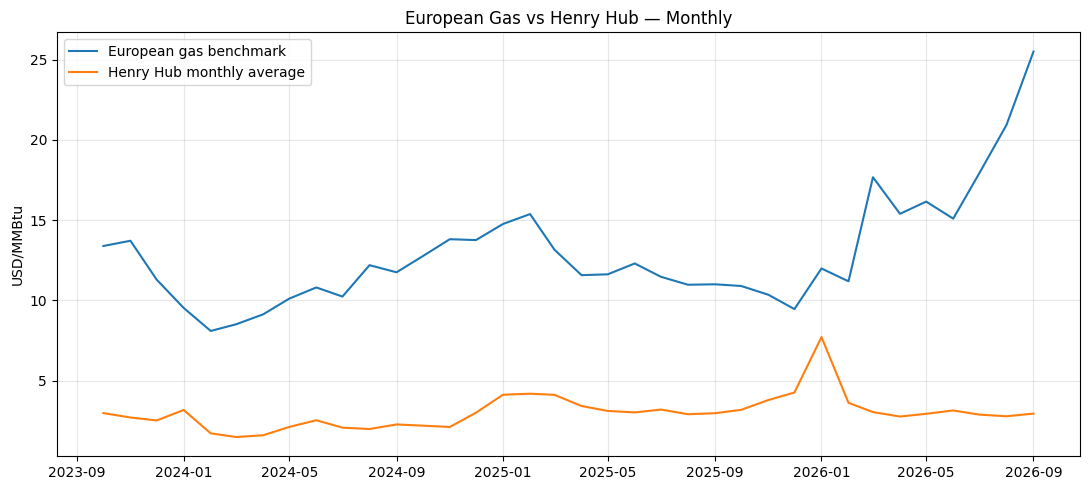

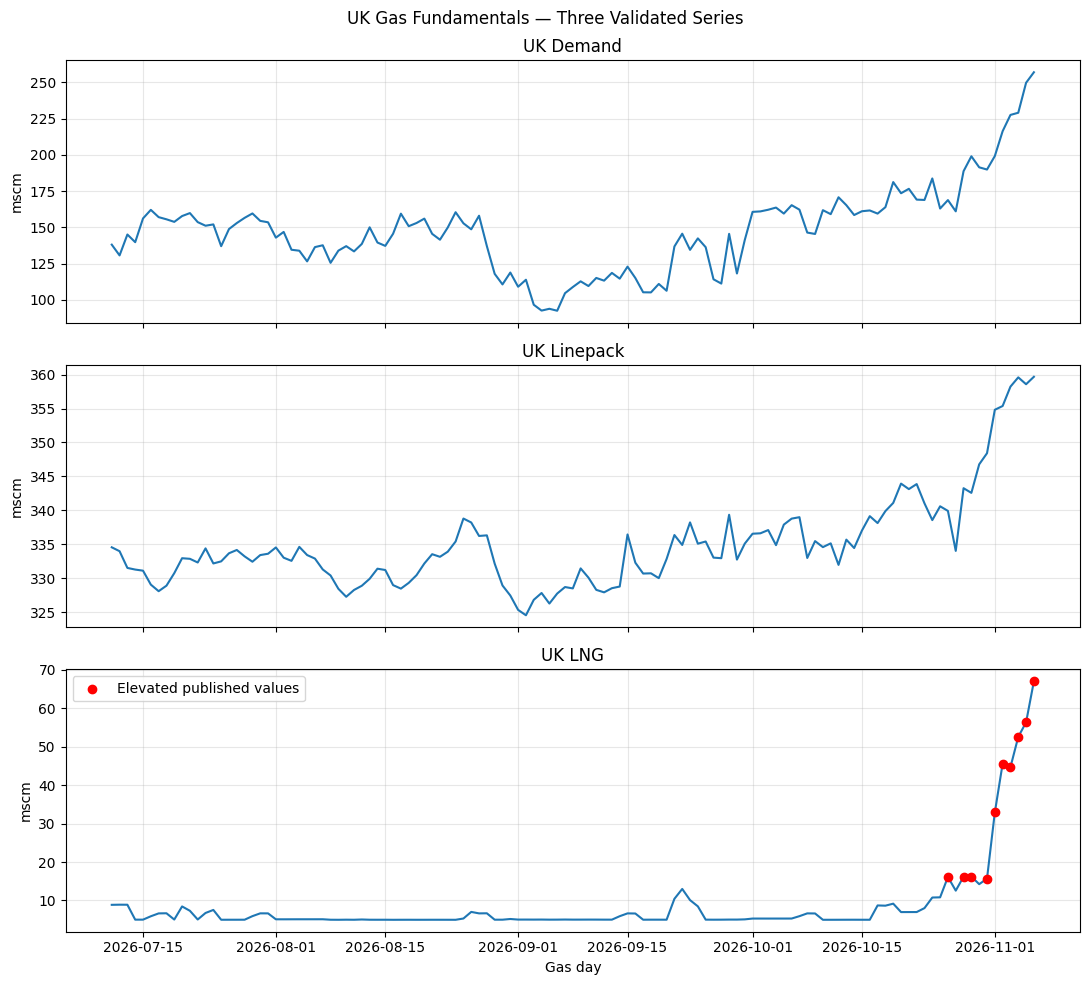


UK FUNDAMENTALS
Latest gas day: 2026-11-06
Demand: 257.07 mscm
Linepack: 359.67 mscm
LNG: 67.04 mscm
LNG entry / NTS demand: 26.08 %

Recent 7-day mean changes
Demand: 44.75 mscm
LNG: 31.14 mscm
Linepack: 15.55 mscm

US STORAGE FORECAST
Starting storage: 3801.0
12-week lower: 2531.4
12-week base: 2771.4
12-week higher: 3011.4
12-week historical MAE: 165.21


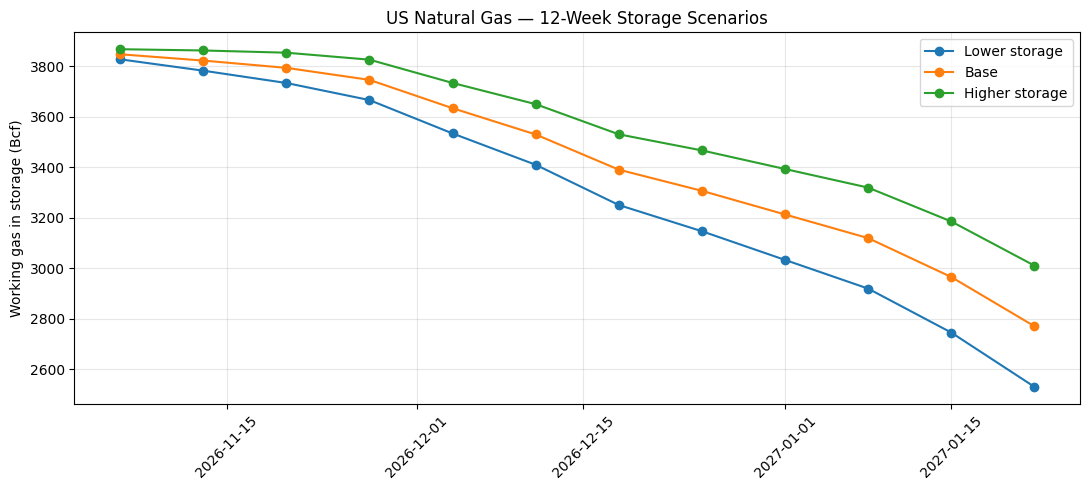


MARKET INTELLIGENCE ASSESSMENT

UK / EUROPE
Operational view: Mixed / neutral
 - Bullish: UK demand seven-day mean increased
 - Bearish: UK LNG NTS entry seven-day mean increased
 - Bearish: UK linepack seven-day mean increased
European premium: 22.54 USD/MMBtu in 2026-09
Important: benchmark spread is not an executable LNG arbitrage margin.

UNITED STATES
Henry Hub view: Neutral / insufficient price evidence
Storage forecast: 3801.0 Bcf to 2771.4 Bcf over 12 weeks.
Bullish-price lower-storage case: 2531.4 Bcf
Bearish-price higher-storage case: 3011.4 Bcf
Historical 12-week MAE: 165.2 Bcf

CONCLUSION
This is a conditional, evidence-based market assessment rather than a live trading recommendation.

BATCH 14 COMPLETED
Output records: 29
File: natural_gas_final_trading_intelligence.csv

Sections:
Section
Risk Register        8
Market Evidence      7
Forward Scenario     3
Model Validation     3
Supporting Signal    3
Trading Scenario     3
Market Assessment    2


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [30]:

# ============================================================
# BATCH 14 — PROFESSIONAL NATURAL GAS MARKET INTELLIGENCE
#
# Uses completed price, UK, LNG and forecast validation.
# Produces evidence-based US and UK/Europe market views.
# Preserves all three UK graphs.
#
# One CSV download. No original files modified.
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from google.colab import files

plt.rcParams["figure.figsize"] = (11, 5)

required_files = [
    "natural_gas_corrected_market_analysis.csv",
    "natural_gas_storage_forecast.csv",
    "natural_gas_batch13_validation.csv",
    "uk_lng_source_verified.csv"
]

missing = [
    f for f in required_files
    if not Path(f).exists()
]

if missing:
    raise FileNotFoundError(
        "Missing files in this Colab runtime: "
        + ", ".join(missing)
        + ". Upload the missing CSVs to Colab "
        "before running this cell."
    )

market = pd.read_csv(required_files[0])
forecast = pd.read_csv(required_files[1])
validation = pd.read_csv(required_files[2])
lng_check = pd.read_csv(required_files[3])

market["Date"] = pd.to_datetime(
    market["Date"], errors="coerce"
)
market["Value"] = pd.to_numeric(
    market["Value"], errors="coerce"
)

forecast["Date"] = pd.to_datetime(
    forecast["Date"], errors="coerce"
)

lng_check["Date"] = pd.to_datetime(
    lng_check["Date"], errors="coerce"
)

records = []

def add(section, market_region, indicator, value,
        unit="", interpretation="", source="",
        confidence="", as_of=""):
    records.append({
        "Section": section,
        "Market": market_region,
        "Indicator": indicator,
        "Value": value,
        "Unit": unit,
        "Interpretation": interpretation,
        "Source_or_Method": source,
        "Confidence_or_Status": confidence,
        "As_Of": as_of
    })

def get_series(section, indicator):
    part = market[
        (market["Section"] == section)
        & (market["Indicator"] == indicator)
    ].dropna(subset=["Date", "Value"])

    return part.sort_values("Date").copy()

def last_value(series, name):
    if series.empty:
        raise ValueError("Missing indicator: " + name)
    return float(series["Value"].iloc[-1])

def recent_change(series, days=28):
    if series.empty:
        return np.nan, np.nan

    end_date = series["Date"].max()
    current = float(series["Value"].iloc[-1])

    earlier = series[
        series["Date"] <= (
            end_date - pd.Timedelta(days=days)
        )
    ]

    if earlier.empty:
        return np.nan, np.nan

    previous = float(earlier["Value"].iloc[-1])

    return current - previous, previous

# ============================================================
# 1. VALIDATION GATES
# ============================================================

print("=" * 65)
print("BATCH 14 — DATA VALIDATION")
print("=" * 65)

expected_lng = {
    "MATCH"
}

lng_status = lng_check["Status"].astype(str)

if not lng_status.isin(expected_lng).all():
    raise ValueError(
        "LNG verification has unmatched observations. "
        "Resolve these before generating market views."
    )

if len(lng_check) != 119:
    raise ValueError(
        "Unexpected LNG verification coverage: "
        + str(len(lng_check))
    )

if not np.allclose(
    pd.to_numeric(
        lng_check["Saved_Value"], errors="coerce"
    ),
    pd.to_numeric(
        lng_check["Official_Value"], errors="coerce"
    ),
    rtol=0,
    atol=0.01
):
    raise ValueError(
        "Saved and official LNG values differ."
    )

print(
    "UK LNG: 119/119 observations match "
    "National Gas publication PUBOBJ629."
)

bt_summary = validation[
    validation["Section"] == "Backtest Summary"
].copy()

bt_summary["Predicted"] = pd.to_numeric(
    bt_summary["Predicted"], errors="coerce"
)

bt_summary["Actual"] = pd.to_numeric(
    bt_summary["Actual"], errors="coerce"
)

def find_backtest(horizon):
    target = str(horizon) + "-week MAE"

    subset = bt_summary[
        bt_summary["Item"] == target
    ]

    if len(subset) != 1:
        raise ValueError(
            "Missing backtest summary: " + target
        )

    row = subset.iloc[0]

    return (
        float(row["Predicted"]),
        float(row["Actual"])
    )

mae4, naive4 = find_backtest(4)
mae8, naive8 = find_backtest(8)
mae12, naive12 = find_backtest(12)

if not all(
    np.isfinite(v) and v >= 0
    for v in [
        mae4, naive4, mae8,
        naive8, mae12, naive12
    ]
):
    raise ValueError("Invalid backtest metrics")

print(
    "Seasonal model 12-week MAE:",
    round(mae12, 2), "Bcf"
)

# ============================================================
# 2. EUROPEAN AND US GAS PRICES
# ============================================================

europe = get_series(
    "European Prices",
    "European IMF gas benchmark"
)

henry = get_series(
    "European Prices",
    "Henry Hub monthly average"
)

premium = get_series(
    "European Prices",
    "Europe minus Henry Hub premium"
)

price_date = min(
    europe["Date"].max(),
    henry["Date"].max(),
    premium["Date"].max()
)

europe_latest = europe[
    europe["Date"] == price_date
]

henry_latest = henry[
    henry["Date"] == price_date
]

premium_latest = premium[
    premium["Date"] == price_date
]

if (
    len(europe_latest) != 1
    or len(henry_latest) != 1
    or len(premium_latest) != 1
):
    raise ValueError(
        "Latest European and US price dates "
        "do not align."
    )

eu_price = float(
    europe_latest["Value"].iloc[0]
)

hh_price = float(
    henry_latest["Value"].iloc[0]
)

spread = float(
    premium_latest["Value"].iloc[0]
)

if not np.isclose(
    eu_price - hh_price, spread, atol=0.01
):
    raise ValueError("Price spread arithmetic failed")

price_date_text = price_date.strftime("%Y-%m")

print("\nPRICE COMPARISON")
print("Latest aligned month:", price_date_text)
print("European benchmark:", round(eu_price, 3))
print("Henry Hub:", round(hh_price, 3))
print("Premium:", round(spread, 3))

add(
    "Market Evidence",
    "UK/Europe",
    "European gas benchmark",
    round(eu_price, 4),
    "USD/MMBtu",
    "Monthly European benchmark; not a live "
    "TTF or NBP trading quote.",
    "IMF benchmark via FRED",
    "Historical monthly benchmark",
    price_date_text
)

add(
    "Market Evidence",
    "US",
    "Henry Hub monthly average",
    round(hh_price, 4),
    "USD/MMBtu",
    "US spot-price benchmark, monthly average.",
    "FRED DHHNGSP",
    "Historical monthly average",
    price_date_text
)

add(
    "Market Evidence",
    "Cross-market",
    "European minus Henry Hub premium",
    round(spread, 4),
    "USD/MMBtu",
    "Benchmark price difference only. "
    "Not a net LNG arbitrage margin: "
    "liquefaction, freight, regasification, "
    "basis and timing costs are excluded.",
    "Calculated from aligned monthly prices",
    "Descriptive spread, not executable trade",
    price_date_text
)

plt.figure(figsize=(11, 5))

recent_europe = europe.tail(36)
recent_henry = henry.tail(36)

plt.plot(
    recent_europe["Date"],
    recent_europe["Value"],
    label="European gas benchmark"
)

plt.plot(
    recent_henry["Date"],
    recent_henry["Value"],
    label="Henry Hub monthly average"
)

plt.title("European Gas vs Henry Hub — Monthly")
plt.ylabel("USD/MMBtu")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# ============================================================
# 3. UK DEMAND, LINEPACK AND LNG
# ============================================================

demand = get_series("UK Fundamentals", "Demand")
linepack = get_series("UK Fundamentals", "Linepack")
lng = get_series("UK Fundamentals", "LNG")

ratio = get_series(
    "UK Fundamentals",
    "LNG entry / NTS demand"
)

uk_series = {
    "Demand": demand,
    "Linepack": linepack,
    "LNG": lng
}

fig, axes = plt.subplots(
    3, 1, figsize=(11, 10), sharex=True
)

for ax, (name, part) in zip(
    axes, uk_series.items()
):
    ax.plot(part["Date"], part["Value"])
    ax.set_title("UK " + name)
    ax.set_ylabel("mscm")
    ax.grid(alpha=0.3)

    if name == "LNG":
        elevated = lng_check[
            lng_check["Elevated_Value_Flag"]
            .astype(str).str.lower()
            .eq("true")
        ]

        ax.scatter(
            elevated["Date"],
            pd.to_numeric(
                elevated["Saved_Value"],
                errors="coerce"
            ),
            color="red",
            label="Elevated published values",
            zorder=3
        )
        ax.legend()

axes[-1].set_xlabel("Gas day")

plt.suptitle(
    "UK Gas Fundamentals — Three Validated Series"
)
plt.tight_layout()
plt.show()

# Align latest daily indicators to a common date.
common_dates = (
    set(demand["Date"])
    & set(linepack["Date"])
    & set(lng["Date"])
    & set(ratio["Date"])
)

if not common_dates:
    raise ValueError(
        "No common UK observation date."
    )

uk_date = max(common_dates)

def at_date(series, date):
    part = series[series["Date"] == date]
    if len(part) != 1:
        raise ValueError(
            "Duplicate or missing UK observation"
        )
    return float(part["Value"].iloc[0])

demand_now = at_date(demand, uk_date)
linepack_now = at_date(linepack, uk_date)
lng_now = at_date(lng, uk_date)
ratio_now = at_date(ratio, uk_date)

if demand_now <= 0:
    raise ValueError("Invalid UK demand denominator")

# Ratio could be stored as a fraction or percentage.
# Detect its representation from actual arithmetic.
calculated_fraction = lng_now / demand_now

if np.isclose(
    ratio_now, calculated_fraction, atol=0.001
):
    ratio_pct = ratio_now * 100
elif np.isclose(
    ratio_now, calculated_fraction * 100,
    atol=0.1
):
    ratio_pct = ratio_now
else:
    raise ValueError(
        "LNG-to-demand ratio does not match "
        "the underlying volumes."
    )

demand_change, demand_previous = recent_change(
    demand
)

linepack_change, linepack_previous = recent_change(
    linepack
)

lng_change, lng_previous = recent_change(
    lng
)

# Compare recent 7 days with preceding 7 days,
# reducing reliance on one anomalous gas day.
def consecutive_windows(series):
    end = series["Date"].max()

    recent = series[
        (series["Date"] > end - pd.Timedelta(days=7))
        & (series["Date"] <= end)
    ]

    previous = series[
        (series["Date"] > end - pd.Timedelta(days=14))
        & (
            series["Date"]
            <= end - pd.Timedelta(days=7)
        )
    ]

    if len(recent) < 5 or len(previous) < 5:
        return np.nan, np.nan, np.nan

    a = float(recent["Value"].mean())
    b = float(previous["Value"].mean())

    return a, b, a - b

demand_7, demand_prior, demand_delta = (
    consecutive_windows(demand)
)

lng_7, lng_prior, lng_delta = (
    consecutive_windows(lng)
)

linepack_7, linepack_prior, linepack_delta = (
    consecutive_windows(linepack)
)

print("\nUK FUNDAMENTALS")
print("Latest gas day:", uk_date.date())
print("Demand:", round(demand_now, 2), "mscm")
print("Linepack:", round(linepack_now, 2), "mscm")
print("LNG:", round(lng_now, 2), "mscm")
print(
    "LNG entry / NTS demand:",
    round(ratio_pct, 2), "%"
)

print("\nRecent 7-day mean changes")
print("Demand:", round(demand_delta, 2), "mscm")
print("LNG:", round(lng_delta, 2), "mscm")
print(
    "Linepack:", round(linepack_delta, 2), "mscm"
)

for name, value, change in [
    ("Demand", demand_now, demand_delta),
    ("Linepack", linepack_now, linepack_delta),
    ("LNG", lng_now, lng_delta)
]:
    add(
        "Market Evidence",
        "UK",
        name + " latest level",
        round(value, 4),
        "mscm",
        "Latest observed level; recent seven-day "
        "mean change: "
        + str(round(change, 3))
        + " mscm.",
        "National Gas Transmission",
        (
            "LNG values matched publication; "
            "original quality indicators retained"
            if name == "LNG"
            else "Published operational series"
        ),
        str(uk_date.date())
    )

add(
    "Market Evidence",
    "UK",
    "LNG entry divided by NTS demand",
    round(ratio_pct, 3),
    "%",
    "Partial comparison of physical LNG NTS "
    "entry with NTS demand. Not a complete "
    "UK gas supply balance.",
    "National Gas Transmission; calculated",
    "Descriptive ratio",
    str(uk_date.date())
)

# ============================================================
# 4. US STORAGE AND FORECAST EVIDENCE
# ============================================================

forecast = forecast.sort_values(
    "Horizon_Weeks"
).copy()

if forecast["Horizon_Weeks"].tolist() != list(
    range(1, 13)
):
    raise ValueError(
        "Expected exactly 12 forecast horizons."
    )

last = forecast.iloc[-1]

starting_storage = float(
    last["Starting_Storage_Bcf"]
)

base12 = float(last["Base_Storage_Bcf"])
higher12 = float(last["Higher_Storage_Bcf"])
lower12 = float(last["Lower_Storage_Bcf"])

if not lower12 < base12 < higher12:
    raise ValueError(
        "Forward storage scenarios are not ordered."
    )

if not np.isclose(
    higher12 - base12, 240, atol=0.1
):
    raise ValueError(
        "Higher scenario should be base +240 Bcf."
    )

if not np.isclose(
    base12 - lower12, 240, atol=0.1
):
    raise ValueError(
        "Lower scenario should be base -240 Bcf."
    )

starting_date = str(last["Starting_Date"])
target_date = str(last["Date"].date())

print("\nUS STORAGE FORECAST")
print("Starting storage:", starting_storage)
print("12-week lower:", lower12)
print("12-week base:", base12)
print("12-week higher:", higher12)
print("12-week historical MAE:", round(mae12, 2))

for name, value in [
    ("Lower storage scenario", lower12),
    ("Base storage forecast", base12),
    ("Higher storage scenario", higher12)
]:
    add(
        "Forward Scenario",
        "US",
        name,
        round(value, 3),
        "Bcf",
        "Projected working gas on "
        + target_date
        + ". Higher/lower scenarios apply "
        "illustrative +/-20 Bcf weekly changes. "
        "These are not statistical confidence "
        "intervals.",
        "Five-year ISO-week seasonal model",
        "Illustrative forward projection",
        target_date
    )

for horizon, model_mae, baseline_mae in [
    (4, mae4, naive4),
    (8, mae8, naive8),
    (12, mae12, naive12)
]:
    improvement = (
        100 * (1 - model_mae / baseline_mae)
        if baseline_mae > 0
        else np.nan
    )

    add(
        "Model Validation",
        "US",
        str(horizon) + "-week backtest MAE",
        round(model_mae, 3),
        "Bcf",
        "No-change baseline MAE: "
        + str(round(baseline_mae, 3))
        + " Bcf; relative MAE improvement: "
        + str(round(improvement, 2))
        + "%. Historical evaluation only.",
        "Batch 13 seasonal forecast backtest",
        "150 overlapping historical tests "
        "per horizon; not independent trials",
        starting_date
    )

plt.figure(figsize=(11, 5))

for column, label in [
    ("Lower_Storage_Bcf", "Lower storage"),
    ("Base_Storage_Bcf", "Base"),
    ("Higher_Storage_Bcf", "Higher storage")
]:
    plt.plot(
        forecast["Date"],
        forecast[column],
        marker="o",
        label=label
    )

plt.title("US Natural Gas — 12-Week Storage Scenarios")
plt.ylabel("Working gas in storage (Bcf)")
plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

# ============================================================
# 5. MARKET INTELLIGENCE
#
# Direction refers to price pressure, not a
# recommendation to buy or sell a contract.
#
# UK/Europe and US assessed separately.
# ============================================================

print("\n" + "=" * 65)
print("MARKET INTELLIGENCE ASSESSMENT")
print("=" * 65)

# UK/Europe:
# A seven-day rise in demand supports price.
# A seven-day rise in LNG supply entry weighs on price.
# A rise in linepack is a weak loosening signal.
# Signals are descriptive, not a fitted trading model.

uk_signals = []

if np.isfinite(demand_delta):
    if demand_delta > 0:
        uk_signals.append((
            "Bullish",
            "UK demand seven-day mean increased"
        ))
    elif demand_delta < 0:
        uk_signals.append((
            "Bearish",
            "UK demand seven-day mean decreased"
        ))

if np.isfinite(lng_delta):
    if lng_delta > 0:
        uk_signals.append((
            "Bearish",
            "UK LNG NTS entry seven-day mean increased"
        ))
    elif lng_delta < 0:
        uk_signals.append((
            "Bullish",
            "UK LNG NTS entry seven-day mean decreased"
        ))

if np.isfinite(linepack_delta):
    if linepack_delta > 0:
        uk_signals.append((
            "Bearish",
            "UK linepack seven-day mean increased"
        ))
    elif linepack_delta < 0:
        uk_signals.append((
            "Bullish",
            "UK linepack seven-day mean decreased"
        ))

bullish_count = sum(
    x[0] == "Bullish" for x in uk_signals
)

bearish_count = sum(
    x[0] == "Bearish" for x in uk_signals
)

# Require at least two directional signals,
# with no opposing signal, for a directional label.
if bullish_count >= 2 and bearish_count == 0:
    uk_view = "Bullish pressure"
elif bearish_count >= 2 and bullish_count == 0:
    uk_view = "Bearish pressure"
else:
    uk_view = "Mixed / neutral"

# US:
# Storage projection shows seasonal direction,
# but not surplus/deficit vs five-year norms.
# No directional price view from forecast alone.
us_view = "Neutral / insufficient price evidence"

add(
    "Market Assessment",
    "UK/Europe",
    "Near-term UK operational pressure",
    uk_view,
    "Qualitative",
    "Based on changes in UK NTS demand, "
    "physical LNG entry and linepack. "
    "Does not incorporate full UK supply, "
    "weather forecasts, TTF/NBP forwards "
    "or pipeline outage information.",
    "Transparent three-indicator rule",
    "Indicative; not a calibrated price forecast",
    str(uk_date.date())
)

for direction, explanation in uk_signals:
    add(
        "Supporting Signal",
        "UK/Europe",
        direction + " indicator",
        direction,
        "Qualitative",
        explanation,
        "National Gas seven-day means",
        "Descriptive evidence",
        str(uk_date.date())
    )

add(
    "Market Assessment",
    "US",
    "Henry Hub directional assessment",
    us_view,
    "Qualitative",
    "The 12-week forecast projects storage "
    "levels, not Henry Hub prices. "
    "A defensible bullish/bearish price view "
    "requires comparison with seasonal norms, "
    "weather forecasts, production and LNG "
    "export demand.",
    "Storage forecast and historical backtest",
    "Evidence insufficient for a price call",
    starting_date
)

# ============================================================
# 6. BULLISH, BASE AND BEARISH CASES
# ============================================================

scenarios = [
    {
        "name": "Bullish gas-price case",
        "us": lower12,
        "uk": (
            "Higher demand, weaker LNG entry, "
            "falling linepack or supply disruption"
        ),
        "risk": (
            "Weather turns milder; LNG supply "
            "recovers; storage remains comfortable"
        )
    },
    {
        "name": "Base / neutral case",
        "us": base12,
        "uk": (
            "Mixed UK demand and supply indicators; "
            "no persistent tightening trend"
        ),
        "risk": (
            "A major weather or supply shock "
            "breaks the assumed seasonal pattern"
        )
    },
    {
        "name": "Bearish gas-price case",
        "us": higher12,
        "uk": (
            "Lower demand, sustained LNG entry, "
            "rising linepack or mild weather"
        ),
        "risk": (
            "Unexpected cold, infrastructure "
            "outages or stronger LNG competition"
        )
    }
]

for s in scenarios:
    add(
        "Trading Scenario",
        "Cross-market",
        s["name"],
        round(s["us"], 2),
        "US storage Bcf at 12 weeks",
        "UK/Europe conditions: " + s["uk"]
        + ". Invalidation risk: " + s["risk"]
        + ". The US storage path and UK market "
        "conditions are separate scenario "
        "assumptions, not a joint forecast.",
        "Validated UK indicators and "
        "illustrative US storage scenarios",
        "Conditional scenario, not trade advice",
        target_date
    )

# ============================================================
# 7. RISKS AND DATA LIMITATIONS
# ============================================================

risks = [
    (
        "Benchmark mismatch",
        "European IMF benchmark is monthly; "
        "it is not a live TTF or NBP quote."
    ),
    (
        "LNG arbitrage limitation",
        "European minus Henry Hub benchmark "
        "spread excludes liquefaction, shipping, "
        "regasification and timing costs."
    ),
    (
        "UK balance limitation",
        "LNG entry / NTS demand excludes "
        "other UK supply and demand components."
    ),
    (
        "UK LNG publication quality",
        "All 119 values match the National Gas "
        "publication, but quality flags remain "
        "as published and physical flows "
        "are not independently audited."
    ),
    (
        "Forecast scenario uncertainty",
        "Higher/lower storage paths use "
        "+/-20 Bcf per week by assumption; "
        "not probability-based intervals."
    ),
    (
        "Backtest dependence",
        "Historical test windows overlap, "
        "and past accuracy does not guarantee "
        "future forecasting performance."
    ),
    (
        "US price-model limitation",
        "Storage forecasts are not direct "
        "Henry Hub price forecasts."
    ),
    (
        "Missing live catalysts",
        "No live forward curves, updated "
        "weather forecasts, outage notices "
        "or shipping economics are used."
    )
]

for name, detail in risks:
    add(
        "Risk Register",
        "Cross-market",
        name,
        "Review",
        "",
        detail,
        "Analyst methodology review",
        "Explicit limitation",
        str(uk_date.date())
    )

# ============================================================
# 8. ANALYST SUMMARY
# ============================================================

print("\nUK / EUROPE")
print("Operational view:", uk_view)

for direction, reason in uk_signals:
    print(" -", direction + ":", reason)

print(
    "European premium:",
    round(spread, 2),
    "USD/MMBtu in", price_date_text
)

print(
    "Important: benchmark spread is not "
    "an executable LNG arbitrage margin."
)

print("\nUNITED STATES")
print("Henry Hub view:", us_view)

print(
    "Storage forecast:",
    round(starting_storage, 1),
    "Bcf to",
    round(base12, 1),
    "Bcf over 12 weeks."
)

print(
    "Bullish-price lower-storage case:",
    round(lower12, 1), "Bcf"
)

print(
    "Bearish-price higher-storage case:",
    round(higher12, 1), "Bcf"
)

print(
    "Historical 12-week MAE:",
    round(mae12, 1), "Bcf"
)

print("\nCONCLUSION")
print(
    "This is a conditional, evidence-based "
    "market assessment rather than a live "
    "trading recommendation."
)

# ============================================================
# 9. ONE CSV DOWNLOAD
# ============================================================

output = pd.DataFrame(records)

filename = "natural_gas_final_trading_intelligence.csv"

output.to_csv(filename, index=False)

print("\n" + "=" * 65)
print("BATCH 14 COMPLETED")
print("=" * 65)

print("Output records:", len(output))
print("File:", filename)

print("\nSections:")
print(
    output["Section"].value_counts().to_string()
)

files.download(filename)
